In [1]:
import hashlib, importlib, io, json, math, os, struct, subprocess, sys, time, zipfile
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor, as_completed
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from affine import Affine
from matplotlib.path import Path as PolyPath
from pyproj import CRS, Transformer
from rasterio.enums import MergeAlg
from rasterio.features import rasterize
from scipy import ndimage
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import spearmanr

assert Path.cwd().name == "ml", "run this notebook from the ml/ folder (the %%writefile cells write to ml/export/)"
ROOT = Path.cwd().parent                     # repo root
DATA, RAW, CACHE, EXPORT = ROOT / "data", ROOT / "ml" / "datasets", ROOT / "data" / "cache", ROOT / "ml" / "export"
for p in (RAW, CACHE, EXPORT):
    p.mkdir(parents=True, exist_ok=True)

LOCAL = dict(
    glo30_tiles=RAW / "glo30_tileList.txt",
    geology_moon=RAW / "geology" / "Unified_Geologic_Map_of_the_Moon_GIS_v2.zip",
    geology_mars=RAW / "geology" / "sim3292_database.zip",
    gazetteer_moon=RAW / "gazetteer" / "MOON_nomenclature_center_pts.zip",
    gazetteer_mars=RAW / "gazetteer" / "MARS_nomenclature_center_pts.zip",
    robbins_moon=RAW / "robbins" / "Catalog_Moon_Release_20180815_shapefile180.zip",
    robbins_mars=RAW / "robbins" / "Catalog_Mars_Release_2020_1kmPlus_FullMorphData.csv.zip",
    ctx_footprints=RAW / "stac" / "ctx_dtm_footprints.npz",
    analog_sites=ROOT / "ml" / "analog_sites.csv",          # sourced site list, built by hand + checked against documents
    earth_craters=ROOT / "ml" / "earth_craters.csv",        # USGS locations + Wikidata diameters
    lola_polar_site=RAW / "dem" / "LDEM_80S_20MPP_ADJ.TIF",
    lola_polar_regional=RAW / "dem" / "LDEM_80S_80MPP_ADJ.TIF",
    worldclim=RAW / "climate" / "wc2.1_10m_prec.zip",
    gvp=RAW / "gvp_holocene.json",
    lola_118m=RAW / "dem" / "Lunar_LRO_LOLA_Global_LDEM_118m_Mar2014.tif",                  # optional
    mola_hrsc=RAW / "dem" / "Mars_HRSC_MOLA_BlendDEM_Global_200mp_v2.tif",                 # optional
)


def need(key):
    p = LOCAL[key]
    if not p.exists():
        raise FileNotFoundError(f"{key}: put the file at {p} (see ml/data.md)")
    return p


PROFILE = os.environ.get("ANALOG_PROFILE", "v1")   # "smoke" (pipeline check) | "v1" (ships) | "full"
SIZES = {
    "smoke": dict(per_region=60, n_random_land=300, n_volcanoes=60, n_eval=60, n_boot=10),
    "v1": dict(per_region=600, n_random_land=2500, n_volcanoes=300, n_eval=150, n_boot=20),
    "full": dict(per_region=2000, n_random_land=20000, n_volcanoes=400, n_eval=200, n_boot=50),
}
MODEL_VERSION = f"regions-3.0-{PROFILE}"
CACHE_TAG = "r3"                  # bump when features or sampling change, so old caches aren't reused
SEED = 20261114
CFG = dict(
    **SIZES[PROFILE],                          # library blocks per region; Earth set sizes; eval blocks per region
    tag_share=0.5,                             # half of each region's blocks are placed on mapped landforms
    oversample={"moon": 3.5, "mars": 2.0},     # candidate locations per block kept (stripes, missing DTMs)
    max_per_feature=4 if PROFILE == "smoke" else 10,
    line_step_km=15.0,                         # spacing of candidate blocks along a mapped line
    stripe_max=0.18,                           # Kaguya blocks above this stripe score are rejected
    max_lat=86.5,                              # the global DEMs can't be windowed closer to a pole
    polar_lat=-80.0, polar_max_lat=89.0,       # Moon south of 80S reads polar LOLA instead, which works to the pole
    site_max_nodata=0.05,                      # share of no-data allowed in a 4 km window (filled)
    ctx_inset_km=4.5,                          # a Mars point must sit this far inside a CTX footprint
    min_crater_km=1.0,                         # Earth craters smaller than this are too small for a 4 km block
    crater_min_relief=30.0,                    # Earth crater blocks flatter than this (m) are buried or eroded: dropped
    cover_max=0.3, snap_km=6.0,                # analog sites with more tree/crop/built/water than this get nudged
    discount_floor=0.0,                        # overall = landscape x (floor + (1 - floor) x conditions). 0.4 let farmland through
    earth_floor_grid=(0.2, 0.3, 0.4),           # landscape = similarity x (floor + (1 - floor) x Earth percentile); picked on held-out sites
    earth_gamma_grid=(1.0, 0.7, 0.5),          # v2.1: Earth factor = floor + (1 - floor) x percentile^gamma; under 1 is gentler on mid-ranked land
    surface_beta_grid=(0.25, 0.35, 0.5),       # v2.1: overall = landscape x (surface / 100)^beta instead of sqrt(landscape x surface)
    terrain_power_grid=(1.0, 0.85, 0.75, 0.65, 0.55),  # v2.1: similarity = 100 x p^k; under 1 lifts mid-range matches more than top ones (same order)
    surface_weight_grid=(0.15, 0.25, 0.35),      # v2.1.1: overall = landscape^(1-w) x surface^w, always between the two
    keep_analog_overall=0.92,
    # v3.0 heads: trained on verified analog sites vs random land, whole areas held out
    head_l2_grid=(1.0, 3.0, 10.0, 30.0),       # ridge strength of the terrain head, picked on held-out areas
    head_feature_weight=0.3,                   # volcano and crater blocks count as positives at this weight (a site counts 1)
    head_alpha=0.5,                            # region score logit = terrain head + alpha x (how far above ordinary land the region match is)
    head_area_deg=6.0,                         # sites and land in the same 6 degree cell are held out together
    head_overall_grid=(0.2, 0.3, 0.4),         # overall = terrain^(1-w) x surface^w                  # v2.1: verified sites' median overall must stay at least this share of v2.0's
    weight_lambda_grid=(0.0, 0.5, 1.0, 2.0),    # library weighting strength (0 = off); picked on held-out sites
    commonness_n=200,                           # random Earth blocks used to measure how common each library block's terrain is
    joint_beta=0.5,                             # weight of landform triplets next to region triplets in the joint loss
    planet_alone_max=0.55,                      # a new spatial feature that alone guesses the planet more often than this is dropped
    lf_min_blocks=25 if PROFILE != "smoke" else 8, lf_badge_min=60.0, lf_valid_auc=0.65, lf_valid_min=10,   # landform scores: min blocks, badge threshold, validation AUC (own blocks vs untagged), min tested
    built_penalty=3.0, built_full=0.05,        # fixed conditions penalty, in logit points, reached at 5% built-up land
    area_ring_km=4.0,                          # area-quality sites are also scored at 8 points this far out (evaluation only)
    workers=24,
    shortlist=100, top_k=25,                   # per region and scale: match 100 blocks, average the best 25
    n_segments=10, lam_s_grid=(0.1, 1.0, 10.0), lam_r=1e-3,
    folds=5, pos_per_block=6, max_anchors=4000,
    cross_weight=0.0,                          # Earth-to-planet triplets made both transfer tests worse in 1.1, so they're off
    drop={"site": ("rough_coarse",), "regional": ()},   # features ignored per scale (the tokens stay the same, so caches survive)
    site_share_min=0.4,                        # the 4 km scale gets at least this share of the landscape score
    score_workers=8,                           # processes used to score the Earth blocks
)
SCALES = ("site", "regional")
WORLDS = ("moon", "mars")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print(PROFILE, "profile | model", MODEL_VERSION)

v1 profile | model regions-3.0-v1


In [2]:
%%writefile export/analog_runtime.py
from __future__ import annotations

import math

import numpy as np
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
from scipy.special import expit, ndtri

#  grid and constants

SCALES = {   # the same feature code runs at both scales; everything below is in pixels
    "site": dict(res=31.25, flat_deg=1.0, sun_low=1.5, sun_mid=10.0),
    "regional": dict(res=250.0, flat_deg=0.25, sun_low=1.0, sun_mid=4.0),
}
BLOCK_PX = 128                      # the block: 4 km (site) or 32 km (regional)
PAD_PX = 64                         # margin on every side, for shadows cast from outside the block
WINDOW_PX = BLOCK_PX + 2 * PAD_PX   # 256 px padded window
CELL_PX = 16                        # 8 x 8 = 64 cells (tokens) per block
LOWPASS_PX = 1.0                    # the same Gaussian blur on every world: one effective resolution
ROUGH_FINE_PX, ROUGH_COARSE_PX, TPI_PX = 3, 11, 39      # filter window widths
TPI_NEAR_PX, TPI_FAR_PX = 17, 97                         # v2.0 spatial context windows (the 64 px padding covers both)
RING_PX, N_RINGS = 6, 10                                 # radial profile: 10 rings of 6 px around each candidate centre
LF_SHORT, LF_K = 15, 5                                   # landform scores: shortlist and top-k (v2.1: 30 -> 15, faster clicks)
SHADOW_PX, SVF_PX = 64, 32          # horizon search distances
RADIUS_M = {"earth": 6_371_000.0, "moon": 1_737_400.0, "mars": 3_396_190.0}
WORLDS = ("moon", "mars")

# v1.1: 13 -> 7 token features. dropped the ones that mostly measure DEM noise (rough_fine, curv) and the
# near-duplicates (slope_p90, cell_relief, svf ~ slope_mean; geo_flat = 1 - convex - concave). see ml/diag.ipynb
TOKEN_FEATURES = (
    "slope_mean", "rough_coarse", "geo_convex", "geo_concave",
    "shadow_low", "shadow_mid", "norm_height",
    "tpi_near", "tpi_far",          # v2.0: height against the surroundings ~0.5 and ~1.5 km out, over the block's relief
)
SPEC_BANDS = ((64, 128), (32, 64), (16, 32), (8, 16), (4, 8), (2, 4))   # wavelength bands in pixels for the power spectrum
BLOCK_FEATURES = ("relief", "hurst", "linearity", "depression_area", "depression_depth",
                  *(f"spec{k + 1}" for k in range(len(SPEC_BANDS))),   # v2.0: share of relief in each wavelength band
                  "bowl", "bowl_r", "cone", "cone_r")                  # v2.0: best radially symmetric bowl / cone, and its radius
INPUT_NAMES = TOKEN_FEATURES + tuple("d_" + b for b in BLOCK_FEATURES)
N_TOK, N_IN = len(TOKEN_FEATURES), len(TOKEN_FEATURES) + len(BLOCK_FEATURES)
ENV_NAMES = ("tree", "crop", "built", "water", "snow", "bare", "sparse", "precip", "aridity")   # what the readers return for a click
GATE_NAMES = ("tree", "crop", "built", "water", "open", "sparse", "precip")  # what the conditions model sees. v2.1.1: aridity dropped again,
# it reads cold polar deserts (Devon Island, Iceland) as humid because their evaporation is low, and didn't help held-out ranks
# v3.0 heads. terrain head inputs: per scale, the mean and the spread of every cell measurement over the 64 cells, then
# the block measurements (log relief). surface head inputs: land-cover shares and log rainfall
SURFACE_INPUTS = ("tree", "crop", "built", "water", "snow", "bare", "sparse", "precip")
HEAD_SCALES = ("site", "regional")
HEAD_Z_CLIP = 4.0
# which measurement each terrain-head input belongs to, so "why it matches" shows one row per measurement
HEAD_T_GROUPS = tuple(n for _ in HEAD_SCALES for n in (TOKEN_FEATURES + TOKEN_FEATURES + tuple("d_" + b for b in BLOCK_FEATURES)))
GRID = np.linspace(0.0, 1.0, 1001)
QUANTILES = (np.arange(8) + 0.5) / 8

# 8 azimuths as (row step, col step). Row 0 is north. Closed under 90 degree rotation and mirroring.
DIRS = ((0, 1), (-1, 1), (-1, 0), (-1, -1), (0, -1), (1, -1), (1, 0), (1, 1))


#  terrain features (no training)

def fill_nans(z: np.ndarray) -> np.ndarray:
    bad = np.isnan(z)
    if not bad.any():
        return z
    if bad.all():
        raise ValueError("window has no valid pixels")
    idx = ndimage.distance_transform_edt(bad, return_distances=False, return_indices=True)
    return z[tuple(idx)]


def detrend(z: np.ndarray) -> np.ndarray:
    # Remove the best-fit plane, so a regional tilt doesn't count as texture.
    n = z.shape[0]
    yy, xx = np.mgrid[0:n, 0:n] - (n - 1) / 2.0
    A = np.c_[xx.ravel(), yy.ravel(), np.ones(n * n)]
    return z - (A @ np.linalg.lstsq(A, z.ravel(), rcond=None)[0]).reshape(n, n)


def stripe_score(z_block: np.ndarray, n_bins: int = 18) -> float:
    n = z_block.shape[0]
    w = np.hanning(n)
    P = np.abs(np.fft.fftshift(np.fft.fft2(detrend(z_block) * w[:, None] * w[None, :]))) ** 2
    ky, kx = np.mgrid[0:n, 0:n] - n // 2
    k = np.hypot(kx, ky)
    m = (k >= n / 8) & (k < n / 2)                      # wavelengths of 2 to 8 pixels
    b = np.minimum(((np.degrees(np.arctan2(ky, kx)) % 180) / (180 / n_bins)).astype(int), n_bins - 1)
    e = np.bincount(b[m], weights=P[m], minlength=n_bins)
    return float(e.max() / max(e.sum(), 1e-30))


def slope_deg(z: np.ndarray, res: float) -> np.ndarray:
    gy, gx = np.gradient(z, res)
    return np.degrees(np.arctan(np.hypot(gx, gy)))


def horizon_tangents(z, res, pad, radius_m):
    n = z.shape[0] - 2 * pad
    c = z[pad:pad + n, pad:pad + n]
    far, near = np.empty((8, n, n)), np.empty((8, n, n))
    for a, (dr, dc) in enumerate(DIRS):
        step = math.hypot(dr, dc)
        kmax = min(int(SHADOW_PX // step), pad)
        best = np.full((n, n), -np.inf)
        best_near = np.full((n, n), -np.inf)
        for k in range(1, kmax + 1):
            d = k * step * res
            s = z[pad + k * dr: pad + k * dr + n, pad + k * dc: pad + k * dc + n]
            t = (s - c - d * d / (2.0 * radius_m)) / d
            np.maximum(best, t, out=best)
            if k * step <= SVF_PX:
                np.maximum(best_near, t, out=best_near)
        far[a], near[a] = best, best_near
    return far, near


def hurst_exponent(z: np.ndarray) -> float:
    lags = np.array([1, 2, 4, 8, 16, 32])
    gam = []
    for L in lags:
        dx = z[:, L:] - z[:, :-L]
        dy = z[L:, :] - z[:-L, :]
        gam.append(0.25 * (np.mean(dx * dx) + np.mean(dy * dy)))
    gam = np.maximum(np.array(gam), 1e-12)
    return float(np.polyfit(np.log(lags), np.log(gam), 1)[0] / 2.0)


def depressions(z: np.ndarray, pad: int, relief: float):
    f = 4
    n = z.shape[0] // f
    zc = z[:n * f, :n * f].reshape(n, f, n, f).mean(axis=(1, 3))
    filled = np.full_like(zc, zc.max())
    filled[0, :], filled[-1, :], filled[:, 0], filled[:, -1] = zc[0, :], zc[-1, :], zc[:, 0], zc[:, -1]
    for _ in range(4 * n):
        nxt = np.maximum(zc, ndimage.minimum_filter(filled, size=3, mode="nearest"))
        if np.array_equal(nxt, filled):
            break
        filled = nxt
    p = pad // f
    depth = (filled - zc)[p:n - p, p:n - p]
    rel = max(relief, 1e-6)
    return float((depth > 0.03 * rel).mean()), float(min(depth.mean() / rel, 1.0))


def layout_features(zc: np.ndarray, z: np.ndarray, pad: int, relief: float):
    # Block-level shape numbers the cell matching cannot see (it compares cells as an unordered set).
    gy, gx = np.gradient(detrend(zc))
    jxx, jyy, jxy = (gx * gx).mean(), (gy * gy).mean(), (gx * gy).mean()
    linearity = math.sqrt((jxx - jyy) ** 2 + 4 * jxy * jxy) / max(jxx + jyy, 1e-12)   # 0 = no grain, 1 = one direction
    p2 = np.percentile(zc, 2)
    hyps = float(np.clip((zc.mean() - p2) / max(relief, 1e-6), 0.0, 1.0))             # low = flat floor with peaks
    dep_area, dep_depth = depressions(z, pad, relief)
    return float(linearity), hyps, dep_area, dep_depth


def spectrum_bands(zc: np.ndarray) -> np.ndarray:
    # radially averaged power spectrum: share of the block's (detrended, edge-tapered) relief in each wavelength band.
    # direction-free, so rotating the block doesn't change it
    n = zc.shape[0]
    w = np.hanning(n)
    F = np.abs(np.fft.fft2(detrend(zc) * w[:, None] * w[None, :])) ** 2
    f = np.fft.fftfreq(n)
    fr = np.hypot(f[:, None], f[None, :])
    lam = np.divide(1.0, fr, out=np.full_like(fr, np.inf), where=fr > 0)
    band = np.array([F[(lam > lo) & (lam <= hi)].sum() for lo, hi in SPEC_BANDS])
    tot = band.sum()
    return band / tot if tot > 0 else np.full(len(SPEC_BANDS), 1.0 / len(SPEC_BANDS))


def radial_shapes(zc: np.ndarray, relief: float):
    # best bowl (rim higher than centre) and best cone (centre higher than surroundings) over a 5 x 5 grid of centres.
    # strength = height difference over relief x how much of the area's variance the ring profile explains
    n = zc.shape[0]
    zn = (zc - zc.mean()) / max(relief, 1.0)
    yy, xx = np.mgrid[0:n, 0:n]
    best_b, best_c = (0.0, 0.0), (0.0, 0.0)
    for cy in range(n // 4, 3 * n // 4 + 1, n // 8):
        for cx in range(n // 4, 3 * n // 4 + 1, n // 8):
            ring = (np.hypot(yy - cy, xx - cx) / RING_PX).astype(int)
            m = ring < N_RINGS
            lab, v = ring[m], zn[m]
            cnt = np.bincount(lab, minlength=N_RINGS)
            if (cnt == 0).any():
                continue
            p = np.bincount(lab, v, minlength=N_RINGS) / cnt
            sst = ((v - v.mean()) ** 2).sum()
            r2 = 1.0 - ((v - p[lab]) ** 2).sum() / sst if sst > 0 else 0.0
            b, c = max(0.0, p[1:].max() - p[0]) * r2, max(0.0, p[0] - p[1:].min()) * r2
            if b > best_b[0]:
                best_b = (b, (np.argmax(p[1:]) + 1.5) * RING_PX / (n / 2))
            if c > best_c[0]:
                best_c = (c, (np.argmin(p[1:]) + 1.5) * RING_PX / (n / 2))
    return best_b[0], best_b[1], best_c[0], best_c[1]


def to_cells(a: np.ndarray, cell_px: int) -> np.ndarray:
    # (H, H) map -> (n_cells, cell_px^2), cells in row-major order (cell index = i * n + j).
    n = a.shape[0] // cell_px
    return a.reshape(n, cell_px, n, cell_px).transpose(0, 2, 1, 3).reshape(n * n, cell_px * cell_px)


def compute_features(z_padded: np.ndarray, radius_m: float, scale: str = "site", return_maps: bool = False):
    cfg = SCALES[scale]
    res, pad, cell_px = cfg["res"], PAD_PX, CELL_PX
    z = ndimage.gaussian_filter(fill_nans(np.asarray(z_padded, dtype=np.float64)), LOWPASS_PX, mode="nearest")
    n = z.shape[0] - 2 * pad

    def crop(a):
        return a[pad:pad + n, pad:pad + n]

    slope = crop(slope_deg(z, res))
    rc = crop(z - ndimage.uniform_filter(z, ROUGH_COARSE_PX, mode="nearest"))

    tpi = crop(z - ndimage.uniform_filter(z, TPI_PX, mode="nearest"))
    tpi_n = crop(z - ndimage.uniform_filter(z, TPI_NEAR_PX, mode="nearest"))
    tpi_f = crop(z - ndimage.uniform_filter(z, TPI_FAR_PX, mode="nearest"))
    thr = 0.5 * (TPI_PX // 2) * res * np.tan(np.radians(cfg["flat_deg"]))
    flat = (np.abs(tpi) < thr).astype(float)
    convex = (tpi >= thr).astype(float)
    concave = (tpi <= -thr).astype(float)

    far, near = horizon_tangents(z, res, pad, radius_m)
    shadow_low = (far > np.tan(np.radians(cfg["sun_low"]))).mean(axis=0)
    shadow_mid = (far > np.tan(np.radians(cfg["sun_mid"]))).mean(axis=0)
    svf = 1.0 - np.sin(np.arctan(np.maximum(near, 0.0))).mean(axis=0)

    zc = crop(z)
    p2, p98 = np.percentile(zc, [2, 98])
    relief = p98 - p2

    S, RC, CV, CC, SL, SM, ZC, TN, TF = (to_cells(a, cell_px) for a in (slope, rc, convex, concave, shadow_low, shadow_mid, zc,
                                                                        tpi_n / max(relief, 1.0), tpi_f / max(relief, 1.0)))
    tokens = np.stack([
        S.mean(1),
        np.sqrt((RC ** 2).mean(1)),
        CV.mean(1), CC.mean(1),
        SL.mean(1),
        SM.mean(1),
        (ZC.mean(1) - p2) / max(relief, 1.0),
        TN.mean(1), TF.mean(1),
    ], axis=1)
    linearity, _, dep_area, dep_depth = layout_features(zc, z, pad, relief)
    block = np.array([relief, hurst_exponent(zc), linearity, dep_area, dep_depth, *spectrum_bands(zc), *radial_shapes(zc, relief)])
    if return_maps:
        return tokens, block, dict(dem=zc, slope=slope, tpi=tpi, shadow_low=shadow_low, svf=svf)
    return tokens, block


#  sketches and matching (no training)

def sketch_raw(tokens_scaled: np.ndarray) -> np.ndarray:
    q = np.quantile(tokens_scaled, QUANTILES, axis=-2)
    q = np.moveaxis(q, 0, -2) / np.sqrt(len(QUANTILES))
    return q.reshape(*q.shape[:-2], -1)


def block_diff(bu: np.ndarray, BV: np.ndarray) -> np.ndarray:
    # Block-level mismatches: |log relief ratio|, then plain absolute differences.
    BV = np.atleast_2d(BV)
    d = np.abs(BV - bu[None, :])
    d[:, 0] = np.abs(np.log1p(np.maximum(BV[:, 0], 0.0)) - math.log1p(max(bu[0], 0.0)))
    return d


def pair_inputs_many(U: np.ndarray, V: np.ndarray, bu: np.ndarray, BV: np.ndarray):
    V = np.asarray(V, dtype=np.float64)
    C = (U * U).sum(1)[None, :, None] + (V * V).sum(2)[:, None, :] - 2.0 * np.einsum("if,sjf->sij", U, V)
    raw = np.empty((len(V), N_IN))
    partner = np.empty((len(V), U.shape[0]), dtype=np.int64)
    for s in range(len(V)):
        _, c = linear_sum_assignment(C[s])
        d = U - V[s][c]
        raw[s, :N_TOK] = (d * d).mean(axis=0)
        partner[s] = c
    raw[:, N_TOK:] = block_diff(bu, BV)
    return raw, raw[:, :N_TOK].sum(1), partner


#  the trained model

class Model:
    # everything in model.npz, plus a few derived lookups

    def __init__(self, z: dict):
        self.z = z
        self.version = str(z["version"])
        self.scales = [str(s) for s in z["scales"]]
        self.S = {}
        for s in self.scales:
            g = lambda k, s=s: z[f"{s}__{k}"]
            self.S[s] = dict(
                scale=g("scaler_scale"), pca_mean=g("pca_mean"), pca_comp=g("pca_components"),
                pct_table=g("pct_table"), curve=g("curve_vals"), bias=float(g("bias")),
                ens_curve=g("ens_curve_vals"), ens_bias=g("ens_bias"),
                tokens=g("lib_tokens"),                       # (N, 64, N_TOK) scaled, float16 on disk
                block=g("lib_block").astype(np.float64), sketch=g("lib_sketch").astype(np.float64),
                earth_sketch=g("earth_sketch"), ood_threshold=float(g("ood_threshold")),
                weight=float(g("combo_weight")),
                logw=(z[f"{s}__lib_logw"].astype(np.float64) if f"{s}__lib_logw" in z else np.zeros(len(z["lib_world"]))),
                block_mask=(z[f"{s}__block_mask"].astype(np.float64) if f"{s}__block_mask" in z else np.ones(len(BLOCK_FEATURES))),
            )
        # library: one row per Moon or Mars location, with tokens at every scale
        self.lib_world = z["lib_world"]
        self.lib_region = z["lib_region"]                     # index into region_keys
        self.lib_tag, self.lib_name = z["lib_tag"], z["lib_name"]
        self.lib_lat, self.lib_lon, self.lib_href = z["lib_lat"], z["lib_lon"], z["lib_href"]
        self.region_keys = [str(s) for s in z["region_keys"]]       # "moon:maria", ...
        self.region_title = [str(s) for s in z["region_title"]]
        self.region_world = [k.split(":")[0] for k in self.region_keys]
        self.members = [np.flatnonzero(self.lib_region == r) for r in range(len(self.region_keys))]
        self.calib = {s: [np.sort(z[f"{s}__calib__{r}"]) for r in range(len(self.region_keys))] for s in self.scales}
        self.combo_bias = float(z["combo_bias"])
        self.top_k, self.shortlist = int(z["top_k"]), int(z["shortlist"])
        # Earth-side conditions; they can only discount the landscape score
        self.gate_names = [str(s) for s in z["gate_names"]]
        self.gate_table, self.gate_curve = z["gate_table"], z["gate_curve_vals"]
        self.gate_bias = float(z["gate_bias"])
        self.discount_floor = float(z["discount_floor"])
        self.built_penalty = float(z["built_penalty"]) if "built_penalty" in z else 0.0
        self.built_full = float(z["built_full"]) if "built_full" in z else 0.05
        # Earth-relative factor: each region's similarity is discounted when that much similarity is common on Earth
        self.earth_floor = float(z["earth_floor"]) if "earth_floor" in z else 1.0
        self.earth_gamma = float(z["earth_gamma"]) if "earth_gamma" in z else 1.0          # v2.1
        self.surface_beta = float(z["surface_beta"]) if "surface_beta" in z else None     # v2.1; None = v2.0's sqrt(landscape x surface)
        self.terrain_power = float(z["terrain_power"]) if "terrain_power" in z else 1.0   # v2.1: similarity = 100 x p^k
        self.surface_weight = float(z["surface_weight"]) if "surface_weight" in z else None  # v2.1.1: weighted geometric mean
        # v3.0: heads trained on verified analog sites vs random land. None with older model files
        self.head = None
        if "head_t_w" in z:
            self.head = dict(
                t=dict(w=np.asarray(z["head_t_w"], float), mu=np.asarray(z["head_t_mu"], float), sd=np.asarray(z["head_t_sd"], float), b=float(z["head_t_b"])),
                s=dict(w=np.asarray(z["head_s_w"], float), mu=np.asarray(z["head_s_mu"], float), sd=np.asarray(z["head_s_sd"], float), b=float(z["head_s_b"])),
                cal_t=tuple(float(v) for v in z["head_cal_t"]), cal_s=tuple(float(v) for v in z["head_cal_s"]), alpha=float(z["head_alpha"]))
        self.aridity = z["aridity_grid"] if "aridity_grid" in z else None                 # v2.1: aridity index x 10000, same grid as precip
        self.earth_ref = [np.sort(z[f"earth_ref__{r}"]) if f"earth_ref__{r}" in z else None for r in range(len(self.region_keys))]
        self.precip = z["precip_grid"]                        # mm per year, row 0 = 90 N, col 0 = 180 W
        # v1.3.1 display scale: surface is shown out of its real maximum, overall is the geometric mean, and the
        # overall percentile among random Earth land is stored per world. none of this changes any ranking
        self.surface_max = float(z["surface_max"]) if "surface_max" in z else 100.0
        self.overall_ref = {w: np.sort(z[f"overall_ref__{w}"]) for w in WORLDS if f"overall_ref__{w}" in z}
        # v2.0 library weighting: a match against terrain that's common on Earth counts less
        self.weight_lambda = float(z["weight_lambda"]) if "weight_lambda" in z else 0.0
        # v2.0 landform scores: one per (region, landform tag) with enough blocks
        self.lf_keys = [str(x) for x in z["lf_keys"]] if "lf_keys" in z else []
        nl = len(self.lf_keys)
        self.lf_region = np.asarray(z["lf_region"], int) if nl else np.zeros(0, int)
        self.lf_tag = np.asarray(z["lf_tag"]).astype(str) if nl else np.zeros(0, str)
        self.lf_label = [t.replace("_", " ") for t in self.lf_tag]
        self.lf_valid = np.asarray(z["lf_valid"], bool) if "lf_valid" in z else np.zeros(nl, bool)
        self.lf_members = [np.flatnonzero((self.lib_region == self.lf_region[i]) & (self.lib_tag.astype(str) == self.lf_tag[i])) for i in range(nl)]
        self.lf_calib = {s: [np.sort(z[f"{s}__lfcal__{i}"]) if f"{s}__lfcal__{i}" in z else None for i in range(nl)] for s in self.scales}
        self.lf_earth = [np.sort(z[f"lf_earth__{i}"]) if f"lf_earth__{i}" in z else None for i in range(nl)]
        self.lf_badge_min = float(z["lf_badge_min"]) if "lf_badge_min" in z else 60.0


def load(path) -> Model:
    with np.load(path, allow_pickle=False) as f:
        return Model({k: f[k] for k in f.files})


def aridity_at(model, lat: float, lon: float) -> float:
    # v2.1: aridity index (rain / potential evaporation; under 0.05 hyper-arid, over 0.65 humid) from the grid inside
    # the model file (Global Aridity Index v3.1, Zomer et al. 2022, CC BY 4.0). NaN where unknown or with an older model
    g = getattr(model, "aridity", None)
    if g is None:
        return float("nan")
    i = min(max(int((90.0 - lat) / 180.0 * g.shape[0]), 0), g.shape[0] - 1)
    j = min(max(int(((lon + 180.0) % 360.0) / 360.0 * g.shape[1]), 0), g.shape[1] - 1)
    v = float(g[i, j])
    return float("nan") if v >= 65535 else v / 10000.0


def head_terrain_x(emb: dict) -> np.ndarray:
    # terrain head inputs from an embedding {scale: (tokens, block, sketch)}; NaN for a missing scale (read as typical)
    x = []
    for s in HEAD_SCALES:
        if s in emb:
            tok, blk = np.asarray(emb[s][0], dtype=np.float64), np.array(emb[s][1], dtype=np.float64)
            blk[0] = np.log1p(max(blk[0], 0.0))
            x += [tok.mean(0), tok.std(0), blk]
        else:
            x += [np.full(N_TOK, np.nan), np.full(N_TOK, np.nan), np.full(len(BLOCK_FEATURES), np.nan)]
    return np.concatenate(x)


def surface_x(env: dict) -> np.ndarray:
    # surface head inputs: land-cover shares as they are, rainfall as log(1 + mm). NaN = unknown (read as typical)
    def f(k):
        v = env.get(k)
        return float("nan") if v is None else float(v)
    return np.array([np.log1p(max(f(n), 0.0)) if n == "precip" and not np.isnan(f(n)) else f(n) for n in SURFACE_INPUTS])


def head_logit(H: dict, x: np.ndarray):
    # (logit, contribution of every input). inputs are standardised on the training blocks and clipped, unknown = 0
    z = np.clip(np.nan_to_num((np.asarray(x, dtype=float) - H["mu"]) / H["sd"]), -HEAD_Z_CLIP, HEAD_Z_CLIP)
    c = H["w"] * z
    return float(H["b"] + c.sum()), c


def terrain_head(model, emb: dict):
    # None with an older model. else dict(T=calibrated terrain logit, parts={measurement: logit points}, alpha)
    if getattr(model, "head", None) is None:
        return None
    lg, c = head_logit(model.head["t"], head_terrain_x(emb))
    a, c0 = model.head["cal_t"]
    parts = {}
    for n, v in zip(HEAD_T_GROUPS, c):
        parts[n] = parts.get(n, 0.0) + a * float(v)
    return dict(T=a * lg + c0, parts=parts, alpha=model.head["alpha"])


def match_z(pct: float) -> float:
    # how far above ordinary Earth land a region or landform match is, as a normal score of its percentile
    return float(ndtri(min(max(pct, 0.005), 0.995)))


def sim_curve(model, x):
    # similarity (0-100) from a combined logit. v2.1: 100 x p^k with k <= 1 lifts mid-range matches more than the
    # best ones, without changing the order (k = 1 is v2.0)
    return 100.0 * float(expit(x)) ** getattr(model, "terrain_power", 1.0)


def earth_factor(model, pct: float) -> float:
    # landscape = similarity x this. v2.1 adds the gamma: under 1 it is gentler on land that is only mid-ranked
    return model.earth_floor + (1.0 - model.earth_floor) * pct ** getattr(model, "earth_gamma", 1.0)


def overall_of(model, landscape: float, surface: float) -> float:
    # v2.1: surface as a soft discount, landscape x (surface / 100)^beta, so a bare place keeps nearly its terrain score
    # and surface can't lift a weak terrain match. older models: the v1.3.1 geometric mean
    w = getattr(model, "surface_weight", None)
    if w is not None:            # v2.1.1: landscape^(1-w) x surface^w, so it always sits between the two numbers
        return float(max(landscape, 0.0) ** (1.0 - w) * max(surface, 0.0) ** w)
    beta = getattr(model, "surface_beta", None)
    if beta is None:
        return float(np.sqrt(max(landscape, 0.0) * surface))
    return float(max(landscape, 0.0) * (max(surface, 0.0) / 100.0) ** beta)


def precip_at(model: Model, lat: float, lon: float) -> float:
    # Mean annual precipitation (mm) from the small grid inside the model file. NaN where unknown.
    g = model.precip
    i = min(max(int((90.0 - lat) / 180.0 * g.shape[0]), 0), g.shape[0] - 1)
    j = min(max(int(((lon + 180.0) % 360.0) / 360.0 * g.shape[1]), 0), g.shape[1] - 1)
    v = float(g[i, j])
    return float("nan") if v >= 65535 else v


def top_k_for(model: Model, n_members: int) -> int:
    return max(3, min(model.top_k, n_members // 4))


def embed(model: Model, dems: dict, radius_m: float) -> dict:
    # {scale: padded DEM} -> {scale: (scaled tokens, block features, sketch)}.
    out = {}
    for s in model.scales:
        if dems.get(s) is None:
            continue
        P = model.S[s]
        tok_raw, blk = compute_features(dems[s], radius_m, s)
        blk = blk * P["block_mask"]                 # block features that failed the planet check are switched off
        tok = tok_raw / P["scale"]
        out[s] = (tok, blk, (sketch_raw(tok) - P["pca_mean"]) @ P["pca_comp"].T)
    if not out:
        raise ValueError("no DEM given")
    return out


def to_z(table: np.ndarray, raw: np.ndarray) -> np.ndarray:
    # raw (n, F) -> percentiles (n, F) in [0, 1] using per-input quantile tables (F, 1001).
    raw = np.atleast_2d(raw)
    return np.stack([np.interp(raw[:, k], table[k], GRID) for k in range(raw.shape[1])], axis=1)


def curves_at(curve_vals: np.ndarray, Z: np.ndarray) -> np.ndarray:
    # Curve values (n, F) for percentiles Z (n, F); curves are tabulated on GRID.
    return np.stack([np.interp(Z[:, k], GRID, curve_vals[k]) for k in range(Z.shape[1])], axis=1)


def pair_logit(model: Model, scale: str, raw: np.ndarray, ensemble: bool = False):
    # Pair model of one scale: (logit (n,), contributions (n, 19)[, ensemble logits (n, E)]).
    P = model.S[scale]
    Z = to_z(P["pct_table"], raw)
    contrib = curves_at(P["curve"], Z)
    lg = P["bias"] + contrib.sum(1)
    if not ensemble:
        return lg, contrib
    ens = np.stack([b + curves_at(cv, Z).sum(1) for cv, b in zip(P["ens_curve"], P["ens_bias"])], axis=1)
    return lg, contrib, ens


def calibrated(calib_sorted: np.ndarray, A: float, drop_self: float | None = None) -> float:
    n = len(calib_sorted)
    below = np.searchsorted(calib_sorted, A, side="right")
    if drop_self is not None:            # evaluation only: remove the query's own entry
        n -= 1
        below -= int(drop_self <= A)
    return float((below + 0.5) / (n + 1))


def to_logit(score_0_100: float) -> float:
    p = min(max(score_0_100 / 100.0, 0.02), 0.98)
    return float(np.log(p / (1 - p)))


#  v2.0.1 breakdowns: every shown score split into score points that add up to it exactly

def _secant(g, a: float, b: float, min_w: float = 0.5) -> float:
    # average slope of g between a and b, taken over at least min_w so a step in a calibration table can't blow it up
    lo, hi = min(a, b), max(a, b)
    if hi - lo < min_w:
        mid = 0.5 * (lo + hi)
        lo, hi = mid - 0.5 * min_w, mid + 0.5 * min_w
    return float((g(hi) - g(lo)) / (hi - lo))


def _breakdown(score: float, sim: float, parts: dict, L: float, common: float, power: float = 1.0):
    # score = base + sum(terms) + common + earth, all in score points.
    #   terms: each measurement (logit points of the combined logit L, times the average slope of the 0-100 score)
    #   common: the library weighting (matches against terrain that's common on Earth count less)
    #   earth: the Earth factor (score - similarity; this place looks like ordinary Earth land)
    #   base: what's left, i.e. the score of a typical match with every measurement at its typical value
    tot = float(sum(parts.values()) + common)
    r = _secant(lambda x: 100.0 * float(expit(x)) ** power, L - tot, L)
    terms = {n: float(r * v) for n, v in parts.items()}
    com = float(r * common)
    earth = float(score - sim)
    return dict(base=float(score - sum(terms.values()) - com - earth), terms=terms, common=com, earth=earth,
                total=float(score)), r


def _cell_logits(model: "Model", scale: str, raw: np.ndarray, contrib: np.ndarray, d: np.ndarray) -> np.ndarray:
    # each 500 m cell's share of the cell-feature part of one pair logit. a cell feature's input is the mean squared
    # mismatch over the 64 matched cell pairs, so its effect is split evenly over the cells, then shifted towards cells
    # that match better or worse than the block's average (by the local slope of that feature's curve). sums exactly
    # to the cell features' contributions.
    P = model.S[scale]
    d2 = d * d
    r0 = np.asarray(raw, dtype=float)[:N_TOK]
    step = np.maximum(0.1 * r0, 1e-9)
    hi, lo = np.array(raw, dtype=float), np.array(raw, dtype=float)
    hi[:N_TOK] = r0 + step
    lo[:N_TOK] = np.maximum(r0 - step, 0.0)
    h = curves_at(P["curve"], to_z(P["pct_table"], np.stack([hi, lo])))
    slope = (h[0, :N_TOK] - h[1, :N_TOK]) / np.maximum(hi[:N_TOK] - lo[:N_TOK], 1e-12)
    n = d2.shape[0]
    return ((np.asarray(contrib, dtype=float)[:N_TOK] / n)[None, :] + slope[None, :] * (d2 - r0[None, :]) / n).sum(1)


def _scale_parts(model: "Model", per: dict, calib_of) -> tuple[np.ndarray, float]:
    # per scale: (mean contributions of the top pairs, mean weighting term, aggregate). the shown score goes
    # aggregate -> calibrated score -> logit -> weighted sum; each scale's step is replaced by its average slope from
    # the typical pair (logit = bias) to this aggregate
    w_all = sum(model.S[s]["weight"] for s in model.scales)
    w_sum = sum(model.S[s]["weight"] for s in per)
    rescale = w_all / w_sum if 0 < w_sum < w_all else 1.0
    items, comm = np.zeros(N_IN), 0.0
    for s, v in per.items():
        cal = calib_of(s)
        if cal is None or not len(cal):
            continue
        m = _secant(lambda a, cal=cal: to_logit(100.0 * calibrated(cal, a)), model.S[s]["bias"], v["aggregate"])
        m *= model.S[s]["weight"] * rescale
        items = items + m * np.asarray(v["cbar"])
        comm += m * v["comm"]
    return items, comm


def landform_aggregates(model: Model, emb: dict, ids, exclude: np.ndarray | None = None) -> dict:
    # {landform id: {scale: dict(aggregate, top)}}: mean of the top LF_K weighted pair logits over the landform's blocks
    out = {}
    for i in ids:
        memt = model.lf_members[i]
        if exclude is not None:
            memt = memt[~exclude[memt]]
        if len(memt) < LF_K:
            continue
        per = {}
        for s, (tok, blk, sk) in emb.items():
            P = model.S[s]
            sh = memt[np.argsort(((P["sketch"][memt] - sk) ** 2).sum(1))[:LF_SHORT]]
            raw_t, _, _ = pair_inputs_many(tok, P["tokens"][sh], blk, P["block"][sh])
            lg_t, c_t = pair_logit(model, s, raw_t)
            lw_t = model.weight_lambda * P["logw"][sh]
            lg_t = lg_t + lw_t
            o = np.argsort(-lg_t)
            per[s] = dict(aggregate=float(lg_t[o[:LF_K]].mean()), top=[int(j) for j in sh[o[:3]]],
                          cbar=c_t[o[:LF_K]].mean(0), comm=float(lw_t[o[:LF_K]].mean()))
        out[int(i)] = per
    return out


def landform_score(model: Model, i: int, per: dict, head: dict | None = None) -> dict:
    # same steps as the region score: calibrate per scale, combine the scales, then the Earth factor
    w_all = sum(model.S[s]["weight"] for s in model.scales)
    L, w_s, scales = model.combo_bias, 0.0, {}
    for s, v in per.items():
        cal = model.lf_calib.get(s, [None] * (i + 1))[i]
        sc = 100.0 * calibrated(cal, v["aggregate"]) if cal is not None and len(cal) else 50.0
        scales[s] = dict(score=sc, aggregate=v["aggregate"])
        L += model.S[s]["weight"] * to_logit(sc)
        w_s += model.S[s]["weight"]
    if 0 < w_s < w_all:
        L = model.combo_bias + (L - model.combo_bias) * w_all / w_s
    sim = sim_curve(model, L)
    ref = model.lf_earth[i] if i < len(model.lf_earth) else None
    pct = float(np.searchsorted(ref, L, side="right") / len(ref)) if ref is not None and len(ref) else 1.0
    f = earth_factor(model, pct)
    if head is not None:
        # v3.0: the terrain head, plus how far above ordinary land this landform's match is
        z = match_z(pct)
        Lr = head["T"] + head["alpha"] * z
        sc = float(100.0 * expit(Lr))
        out = dict(score=sc, similarity=sim, earth_percentile=100.0 * pct, logit=float(L), scales=scales, match_z=z)
        out["breakdown"], _ = _breakdown(sc, sc, {**head["parts"], "region_match": head["alpha"] * z}, Lr, 0.0, 1.0)
        out["breakdown"]["kind"] = "head"
        return out
    out = dict(score=sim * f, similarity=sim, earth_percentile=100.0 * pct, logit=float(L), scales=scales)
    if all("cbar" in v for v in per.values()):
        items, comm = _scale_parts(model, per, lambda s: model.lf_calib.get(s, [None] * (i + 1))[i])
        out["breakdown"], _ = _breakdown(sim * f, sim, dict(zip(INPUT_NAMES, items.tolist())), float(L), comm, model.terrain_power)
    return out


def region_scores(model: Model, emb: dict, world: str, exclude: np.ndarray | None = None,
                  n_best: int = 5, with_cells: bool = False, landforms: bool = False, head: dict | None = None):
    # head (v3.0, from terrain_head): the region score becomes 100 x expit(terrain head + alpha x match_z); without it
    # this is the v2 score (similarity x Earth factor), which the notebook still uses for the raw region logits
    out = []
    for r, key in enumerate(model.region_keys):
        if model.region_world[r] != world:
            continue
        mem = model.members[r]
        if exclude is not None:
            mem = mem[~exclude[mem]]
        if len(mem) < 4:
            continue
        k = top_k_for(model, len(mem))
        per_scale, cand, parts, w_sum, L = {}, {}, {}, 0.0, model.combo_bias
        for s, (tok, blk, sk) in emb.items():
            P = model.S[s]
            short = mem[np.argsort(((P["sketch"][mem] - sk) ** 2).sum(1))[:model.shortlist]]
            raw, W, partner = pair_inputs_many(tok, P["tokens"][short], blk, P["block"][short])
            lg, contrib = pair_logit(model, s, raw)
            lw = model.weight_lambda * P["logw"][short]
            lg = lg + lw                                            # v2.0: matches against common terrain count less
            o_k = np.argsort(-lg)[:k]
            A = float(lg[o_k].mean())
            score = 100.0 * calibrated(model.calib[s][r], A)
            per_scale[s] = dict(score=score, aggregate=A)
            parts[s] = dict(aggregate=A, cbar=contrib[o_k].mean(0), comm=float(lw[o_k].mean()))
            cand[s] = dict(short=short, lg=lg, lw=lw, contrib=contrib, W=W, partner=partner, raw=raw)
            L += P["weight"] * to_logit(score)
            w_sum += P["weight"]
        w_all = sum(model.S[s]["weight"] for s in model.scales)
        if 0 < w_sum < w_all:             # a scale is missing: the others carry its weight
            L = model.combo_bias + (L - model.combo_bias) * w_all / w_sum

        lead = "site" if "site" in cand else next(iter(cand))
        c0 = cand[lead]
        top = np.argsort(-c0["lg"])[:max(30, n_best)]        # the 30 best at the lead scale are re-ranked with every scale
        joint = c0["lg"][top].copy()
        others, others_c, others_w = {}, {}, {}
        for s in emb:
            if s == lead:
                continue
            tok, blk, _ = emb[s]
            P = model.S[s]
            raw_o, _, _ = pair_inputs_many(tok, P["tokens"][c0["short"][top]], blk, P["block"][c0["short"][top]])
            lg_o, others_c[s] = pair_logit(model, s, raw_o)
            others_w[s] = model.weight_lambda * P["logw"][c0["short"][top]]
            others[s] = lg_o + others_w[s]
            joint = joint + others[s]
        joint = joint / (1 + len(others))
        best = []
        for o in np.argsort(-joint)[:n_best]:
            i = top[o]
            j = int(c0["short"][i])
            b = dict(index=j, name=str(model.lib_name[j]), tag=str(model.lib_tag[j]), region=key,
                     lat=float(model.lib_lat[j]), lon=float(model.lib_lon[j]), href=str(model.lib_href[j]),
                     pair_score=float(100 * expit(joint[o])), logit=float(joint[o]),
                     scale_logits={lead: float(c0["lg"][i]), **{s: float(v[o]) for s, v in others.items()}},
                     W=float(c0["W"][i]),
                     contributions={n: float(v) for n, v in zip(INPUT_NAMES, c0["contrib"][i])}, _o=int(o))
            if with_cells:
                tok = emb[lead][0]
                d = tok - model.S[lead]["tokens"][j].astype(np.float64)[c0["partner"][i]]
                b["cell_cost"] = (d * d).sum(1).reshape(8, 8).tolist()
                b["partner"] = c0["partner"][i].tolist()
                b["_d"] = d
            best.append(b)
        sim = sim_curve(model, L)
        ref = model.earth_ref[r]
        pct = float(np.searchsorted(ref, L, side="right") / len(ref)) if ref is not None and len(ref) else 1.0
        factor = earth_factor(model, pct)
        if head is not None:
            zr = match_z(pct)
            Lr = head["T"] + head["alpha"] * zr
            factor = 1.0
        # v1.3.2: put each best site on the region score's scale. the region's logit L sits where the average of its
        # top pairs sits, so a site's logit is shifted by the same amount, then gets the same Earth factor.
        # contributions become score points (logit points x the slope of the score at that site), so they read like "+4"
        ref_j = float(np.mean(np.sort(joint)[::-1][:min(k, len(joint))]))
        for b in best:
            L_site = (Lr if head is not None else L) + b["logit"] - ref_j
            power = 1.0 if head is not None else model.terrain_power
            p0 = float(expit(L_site))
            p = p0 ** power                                   # v2.1: the same lift as the region's similarity
            b["pair_score_raw"] = b["pair_score"]
            b["pair_score"] = 100.0 * p * factor
            slope = 100.0 * power * p * (1.0 - p0) * factor
            b["contributions_logit"] = b["contributions"]
            b["contributions"] = {n: v * slope for n, v in b["contributions"].items()}
            # v2.0.1: exact breakdown of pair_score, averaged over the scales like the pair logit itself
            o = b.pop("_o")
            i = top[o]
            n_sc = 1 + len(others)
            feats = (c0["contrib"][i] + sum(others_c[s][o] for s in others)) / n_sc
            comm = (float(c0["lw"][i]) + sum(float(others_w[s][o]) for s in others)) / n_sc
            b["breakdown"], r_b = _breakdown(b["pair_score"], 100.0 * p, dict(zip(INPUT_NAMES, feats.tolist())),
                                             L_site, comm, power)
            if "_d" in b:
                # each cell's share of the 4 km cell features, in the same score points (they add up to those terms)
                cl = _cell_logits(model, lead, c0["raw"][i], c0["contrib"][i], b.pop("_d"))
                b["cell_points"] = (r_b * cl / n_sc).reshape(8, 8).tolist()
        items, comm_l = _scale_parts(model, parts, lambda s: model.calib[s][r])
        region_bd, _ = _breakdown(sim * factor, sim, dict(zip(INPUT_NAMES, items.tolist())), float(L), comm_l, model.terrain_power)
        score_r = sim * factor
        if head is not None:
            score_r = float(100.0 * expit(Lr))
            region_bd, _ = _breakdown(score_r, score_r, {**head["parts"], "region_match": head["alpha"] * zr}, Lr, 0.0, 1.0)
            region_bd["kind"] = "head"
        lf, lf_all = None, []
        if landforms and model.lf_keys:
            for i, per in landform_aggregates(model, emb, np.flatnonzero(model.lf_region == r), exclude).items():
                d = landform_score(model, i, per, head)
                lead_ = "site" if "site" in per else next(iter(per))
                d.update(tag=str(model.lf_tag[i]), label=model.lf_label[i], validated=bool(model.lf_valid[i]),
                         matches=[dict(index=j, name=str(model.lib_name[j]), lat=float(model.lib_lat[j]), lon=float(model.lib_lon[j]))
                                  for j in per[lead_]["top"]])
                lf_all.append(d)
            if lf_all:
                # v2.0.1: show the best validated landform when the region has one, else the best one (marked unvalidated)
                lf = max([d for d in lf_all if d["validated"]] or lf_all, key=lambda d: d["score"])
                lf["badge"] = bool(lf["validated"] and lf["score"] >= model.lf_badge_min and lf["score"] >= score_r)
        out.append(dict(region_id=r, region=key, title=model.region_title[r], score=score_r, similarity=sim,
                        earth_percentile=100.0 * pct, earth_factor=factor,
                        logit=float(L), scales=per_scale, n_members=int(len(mem)), best=best, breakdown=region_bd,
                        landform=lf, landform_scores={d["tag"]: float(d["score"]) for d in lf_all}))
    out.sort(key=lambda d: -d["score"])
    return out


def gate_inputs(env: dict, names=GATE_NAMES) -> np.ndarray:
    # conditions inputs from the raw land-cover shares. "open" = bare ground + snow and ice: neither hides the
    # terrain, so snow isn't penalised (polar analogs like the Dry Valleys are mostly snow, ice and bare rock)
    e = {k: float(v) for k, v in env.items()}
    bare = e.get("bare", np.nan)
    e["open"] = np.nan if np.isnan(bare) else bare + float(np.nan_to_num(e.get("snow", 0.0)))
    return np.array([e.get(n, np.nan) for n in names], dtype=float)


def conditions(model: Model, env: dict):
    # Earth-side conditions: (logit, {input: contribution in logit points}).
    if getattr(model, "head", None) is not None:
        # v3.0: the surface head (trained on verified sites vs random land), plus the fixed building penalty
        lg, c = head_logit(model.head["s"], surface_x(env))
        a, c0 = model.head["cal_s"]
        terms = {n: a * float(v) for n, v in zip(SURFACE_INPUTS, c)}
        fixed = -model.built_penalty * min(float(np.nan_to_num(env.get("built", 0.0))) / model.built_full, 1.0)
        terms["built"] = terms.get("built", 0.0) + fixed
        return float(a * lg + c0 + fixed), terms
    # older models: one-sided curves
    x = gate_inputs(env, model.gate_names)
    built = float(np.nan_to_num(env.get("built", 0.0)))
    Z = to_z(model.gate_table, np.nan_to_num(x, nan=0.0)[None, :])[0]
    Z[np.isnan(x)] = 0.5                 # missing -> typical land
    h = np.array([np.interp(Z[m], GRID, model.gate_curve[m]) for m in range(len(x))])
    terms = {n: float(v) for n, v in zip(model.gate_names, h)}
    fixed = -model.built_penalty * min(built / model.built_full, 1.0)       # buildings never occur at analog sites
    terms["built"] = terms.get("built", 0.0) + fixed
    return float(model.gate_bias + h.sum() + fixed), terms


def score_click(model: Model, dems: dict, env: dict, worlds=WORLDS, n_best: int = 5) -> dict:
    # Everything the API returns for one Earth click: one entry per world (the two tabs).
    emb = embed(model, dems, RADIUS_M["earth"])
    G, terms = conditions(model, env)
    ood = {s: bool(np.sqrt(((model.S[s]["earth_sketch"] - emb[s][2]) ** 2).sum(1).min()) > model.S[s]["ood_threshold"])
           for s in emb}
    blk = emb["site"][1] if "site" in emb else next(iter(emb.values()))[1]
    raw = float(100 * expit(G))                                    # the conditions model's probability, at most surface_max
    surface = float(min(100.0, 100.0 * raw / model.surface_max))   # shown out of 100: 100 = as bare and dry as the model allows
    out = dict(model_version=model.version, scales_used=list(emb), ood=any(ood.values()), ood_by_scale=ood,
               conditions=dict(score=surface, raw=raw, logit=G, discount=surface / 100.0, terms_logit=terms,
                               # terms in surface-score points: logit points x the slope of the 0-100 surface score here
                               terms={n: v * 100.0 * (raw / 100.0) * (1.0 - raw / 100.0) * 100.0 / model.surface_max
                                      for n, v in terms.items()}),
               block={n: float(v) for n, v in zip(BLOCK_FEATURES, blk)}, worlds={})
    head = terrain_head(model, emb)
    if head is not None:
        out["terrain_head"] = dict(score=float(100.0 * expit(head["T"])), logit=float(head["T"]))   # before any region match
    for w in worlds:
        regs = region_scores(model, emb, w, n_best=n_best, with_cells=True, landforms=True, head=head)
        for reg in regs:
            # geometric mean: both terrain and surface have to be good, without squashing two good scores into a low one
            reg["overall"] = overall_of(model, reg["score"], surface)
            if reg.get("landform"):                            # v2.1.1: the feature's overall, the same formula
                reg["landform"]["overall"] = overall_of(model, reg["landform"]["score"], surface)
        regs.sort(key=lambda d: -d["overall"])
        best = max((b for reg in regs for b in reg["best"]), key=lambda b: b["logit"])
        ref = model.overall_ref.get(w)
        pct = float(100.0 * np.searchsorted(ref, regs[0]["overall"], side="right") / len(ref)) if ref is not None else None
        out["worlds"][w] = dict(regions=regs, best_region=regs[0]["region"], landscape_score=regs[0]["score"],
                                overall=regs[0]["overall"], overall_percentile=pct, best_match=best)
    return out


_WORKER_MODELS = {}


def region_logits_task(args):
    # (model path, embedding) -> (region logits (R,), per-scale scores (R, n_scales)). for process pools: the
    # notebook scores thousands of Earth blocks with it; the server doesn't need it
    path, emb = args
    m = _WORKER_MODELS.get(path)
    if m is None:
        m = _WORKER_MODELS[path] = load(path)
    logit = np.full(len(m.region_keys), np.nan)
    per = np.full((len(m.region_keys), len(m.scales)), np.nan)
    for w in WORLDS:
        for reg in region_scores(m, emb, w, n_best=1):
            logit[reg["region_id"]] = reg["logit"]
            per[reg["region_id"]] = [reg["scales"].get(s, {}).get("score", np.nan) for s in m.scales]
    return logit, per


def landform_task(args):
    # (model path, embedding, landform ids, exclude mask) -> landform_aggregates, for process pools in the notebook
    path, emb, ids, exclude = args
    m = _WORKER_MODELS.get(path)
    if m is None:
        m = _WORKER_MODELS[path] = load(path)
    return landform_aggregates(m, emb, ids, exclude)


Overwriting export/analog_runtime.py


In [3]:
%%writefile export/analog_readers.py
#most things here will be fetched with a s3 bucket 
from __future__ import annotations

import ssl
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import rasterio
import rasterio.enums
import rasterio.windows
from pyproj import CRS, Transformer
from scipy import ndimage

import analog_runtime as rt

GDAL_ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.TIF",
                GDAL_HTTP_MULTIPLEX="YES", GDAL_HTTP_MULTIRANGE="YES", GDAL_HTTP_MERGE_CONSECUTIVE_RANGES="YES",
                GDAL_HTTP_MAX_RETRY="3", GDAL_HTTP_RETRY_DELAY="1", VSI_CACHE="TRUE", VSI_CACHE_SIZE="67108864")
GLO30 = "https://copernicus-dem-30m.s3.amazonaws.com"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map"
GLOBAL_DEM = {   # the regional scale on the Moon and Mars (library building only)
    "moon": "/vsicurl/https://planetarymaps.usgs.gov/mosaic/Lunar_LRO_LOLA_Global_LDEM_118m_Mar2014.tif",
    "mars": "/vsicurl/https://planetarymaps.usgs.gov/mosaic/Mars/HRSC_MOLA_Blend/Mars_HRSC_MOLA_BlendDEM_Global_200mp_v2.tif",
}
POLAR_DEM = {   # Moon south of 80S: polar stereographic LOLA, readable all the way to the pole
    "site": "https://pgda.gsfc.nasa.gov/data/LOLA_20mpp/LDEM_80S_20MPP_ADJ.TIF",
    "regional": "https://pgda.gsfc.nasa.gov/data/LOLA_20mpp/LDEM_80S_80MPP_ADJ.TIF",
}
POLAR_LAT = -80.0
UA = "Mozilla/5.0 (analog-explorer)"
WC = {10: "tree", 20: "shrub", 30: "grass", 40: "crop", 50: "built", 60: "bare", 70: "snow",
      80: "water", 90: "wetland", 95: "mangrove", 100: "moss"}
WC_NAMES = ("tree", "crop", "built", "water", "snow", "bare", "sparse")
_TILES = None
# v2.1 speed: the reads for one click run at the same time. rasterio/GDAL release the GIL while waiting on the network.
# two pools so a window waiting on its tiles can never block the tiles themselves
_READ_POOL = ThreadPoolExecutor(6, thread_name_prefix="read")
_TILE_POOL = ThreadPoolExecutor(12, thread_name_prefix="tile")


def http(url, body=None, timeout=60, tries=3, headers=None):
    ctx = ssl.create_default_context()
    try:
        import certifi
        ctx = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        pass
    for t in range(tries):
        try:
            hdr = {"User-Agent": UA, **({"Content-Type": "application/json"} if body else {}), **(headers or {})}
            with urllib.request.urlopen(urllib.request.Request(url, data=body, headers=hdr), context=ctx, timeout=timeout) as r:
                return r.read()
        except Exception:
            if t == tries - 1:
                raise
            time.sleep(1 + 2 * t)


# ---------------------------------------------------------------- the common local grid

def window_lonlat(lat, lon, R, res, n_px=rt.WINDOW_PX):
    c = (np.arange(n_px) - (n_px - 1) / 2) * res
    X, Y = np.meshgrid(c, -c)            # x east, y north; row 0 is north
    aeqd = CRS.from_proj4(f"+proj=aeqd +lat_0={lat} +lon_0={lon} +R={R} +units=m +no_defs")
    geo = CRS.from_proj4(f"+proj=longlat +R={R} +no_defs")
    return Transformer.from_crs(aeqd, geo, always_xy=True).transform(X, Y)


def read_raster_window(href, lat, lon, R, res, max_nodata=0.02):
    lon_g, lat_g = window_lonlat(lat, lon, R, res)
    with rasterio.Env(**GDAL_ENV), rasterio.open(href) as ds:
        crs = CRS.from_wkt(ds.crs.to_wkt())
        if crs.is_projected:
            xs, ys = Transformer.from_crs(crs.geodetic_crs, crs, always_xy=True).transform(lon_g, lat_g)
            native = abs(ds.res[0])
        else:
            xs, ys = lon_g, lat_g
            if ds.bounds.right > 180.5:                      # a 0..360 raster
                xs = np.mod(xs, 360.0)
            native = abs(ds.res[1]) * np.pi / 180.0 * R
        cols, rows = ~ds.transform * (xs, ys)
        cols, rows = np.asarray(cols) - 0.5, np.asarray(rows) - 0.5        # pixel-centre coordinates
        c0, c1 = int(np.floor(cols.min())) - 3, int(np.ceil(cols.max())) + 4
        r0, r1 = int(np.floor(rows.min())) - 3, int(np.ceil(rows.max())) + 4
        if c0 < 0 or r0 < 0 or c1 > ds.width or r1 > ds.height:
            raise ValueError("window leaves the raster")
        if (c1 - c0) > 0.4 * ds.width or (c1 - c0) * (r1 - r0) > 30_000_000:
            raise ValueError("window crosses the map edge or is too close to a pole")
        a = ds.read(1, window=rasterio.windows.Window(c0, r0, c1 - c0, r1 - r0), masked=True)
    z = a.astype(np.float64).filled(np.nan)
    z[z < -30000] = np.nan
    bad = ndimage.map_coordinates(np.isnan(z).astype(float), [rows - r0, cols - c0], order=1, mode="nearest")
    if (bad > 0.5).mean() > max_nodata:
        raise ValueError("too much nodata")
    z = rt.fill_nans(z)
    factor = res / native
    if factor > 1.2:
        z = ndimage.gaussian_filter(z, 0.5 * factor)
    return ndimage.map_coordinates(z, [rows - r0, cols - c0], order=1, mode="nearest"), native


#  Earth terrain: Copernicus GLO-30

def glo30_tile_name(la, lo):
    return f"Copernicus_DSM_COG_10_{'N' if la >= 0 else 'S'}{abs(la):02d}_00_{'E' if lo >= 0 else 'W'}{abs(lo):03d}_00_DEM"


def glo30_tiles(cache_path=None):
    # Names of the tiles that exist (land). Fetched once; pass cache_path to keep a local copy.
    global _TILES
    if _TILES is None:
        if cache_path is not None and cache_path.exists():
            text = cache_path.read_text()
        else:
            text = http(f"{GLO30}/tileList.txt").decode()
            if cache_path is not None:
                cache_path.write_text(text)
        _TILES = {s.strip() for s in text.splitlines() if s.strip()}
    return _TILES


def read_glo30_window(lat, lon, res):
    R = rt.RADIUS_M["earth"]
    lon_g, lat_g = window_lonlat(lat, lon, R, res)
    lon_g = (lon_g + 180.0) % 360.0 - 180.0
    out = np.full(lon_g.shape, np.nan)
    lat_f, lon_f = np.floor(lat_g).astype(int), np.floor(lon_g).astype(int)
    tiles = glo30_tiles()

    def one(la, lo):
        # one GLO-30 tile's part of the window: (selection mask, heights), or None when the tile doesn't exist (sea)
        name = glo30_tile_name(la, lo)
        if name not in tiles:
            return None
        sel = (lat_f == la) & (lon_f == lo)
        with rasterio.Env(**GDAL_ENV), rasterio.open(f"/vsicurl/{GLO30}/{name}/{name}.tif") as ds:
            dx, dy = ds.res
            w = rasterio.windows.from_bounds(lon_g[sel].min() - 9 * dx, lat_g[sel].min() - 9 * dy,
                                             lon_g[sel].max() + 9 * dx, lat_g[sel].max() + 9 * dy, ds.transform)
            w = w.round_offsets().round_lengths().intersection(rasterio.windows.Window(0, 0, ds.width, ds.height))
            native_m = dy * np.pi / 180.0 * R
            f = max((k for k in (1, 2, 4, 8) if k * native_m <= res), default=1)   # overview level
            shape = (max(1, int(round(w.height / f))), max(1, int(round(w.width / f))))
            arr = ds.read(1, window=w, out_shape=shape, resampling=rasterio.enums.Resampling.average).astype(np.float64)
            t = ds.window_transform(w)
        sx, sy = t.a * w.width / shape[1], t.e * w.height / shape[0]          # degrees per decimated pixel
        factor = res / (abs(sy) * np.pi / 180.0 * R)
        if factor > 1.2:
            arr = ndimage.gaussian_filter(arr, 0.5 * factor, mode="nearest")
        col = (lon_g[sel] - t.c) / sx - 0.5
        row = (lat_g[sel] - t.f) / sy - 0.5
        return sel, ndimage.map_coordinates(arr, [row, col], order=1, mode="nearest")

    # v2.1 speed: the 1-4 tiles a window touches are read at the same time
    keys = sorted({(int(a), int(b)) for a, b in zip(lat_f.ravel(), lon_f.ravel())})
    for got in _TILE_POOL.map(lambda k: one(*k), keys):
        if got is not None:
            out[got[0]] = got[1]
    return out


def flat_fraction(z):
    # Share of pixels identical to both neighbours: GLO-30 flattens water bodies.
    same = (z[:-1, :-1] == z[:-1, 1:]) & (z[:-1, :-1] == z[1:, :-1])
    return float(same.mean())


#  Earth surface: ESA WorldCover 2021

def worldcover_shares(lat, lon, half_m=2000.0):
    # Land-cover shares over the 4 km block: tree, crop, built, water, snow, bare. NaN when unknown.
    dlat = np.degrees(half_m / rt.RADIUS_M["earth"])
    dlon = dlat / max(np.cos(np.radians(lat)), 1e-3)
    la0, lo0 = int(np.floor(lat / 3) * 3), int(np.floor(lon / 3) * 3)
    name = f"ESA_WorldCover_10m_2021_v200_{'N' if la0 >= 0 else 'S'}{abs(la0):02d}{'E' if lo0 >= 0 else 'W'}{abs(lo0):03d}_Map.tif"
    try:
        with rasterio.Env(**GDAL_ENV), rasterio.open(f"/vsicurl/{WORLDCOVER}/{name}") as ds:
            w = rasterio.windows.from_bounds(lon - dlon, lat - dlat, lon + dlon, lat + dlat, ds.transform)
            w = w.round_offsets().round_lengths().intersection(rasterio.windows.Window(0, 0, ds.width, ds.height))
            a = ds.read(1, window=w)
    except Exception:
        # no tile. Antarctica (WorldCover stops at 60 S): no trees, crops, buildings or open water down there, and the
        # split between ice and bare rock is unknown (the surface head reads unknown as typical). elsewhere: all unknown
        if lat < -60.0:
            return dict(tree=0.0, crop=0.0, built=0.0, water=0.0, snow=np.nan, bare=np.nan, sparse=np.nan)
        return {n: np.nan for n in WC_NAMES}
    a = a[a > 0]
    if a.size == 0:
        return {n: np.nan for n in WC_NAMES}
    s = {name: float(np.mean(a == k)) for k, name in WC.items()}
    return dict(tree=s["tree"] + s["mangrove"], crop=s["crop"], built=s["built"],
                water=s["water"] + s["wetland"], snow=s["snow"], bare=s["bare"],
                sparse=s["shrub"] + s["grass"] + s["moss"])     # shrubland, grassland, moss and lichen


#  one click, start to finish

def fetch_earth(model, lat, lon, scales=None):
    # Everything score_click needs for an Earth coordinate: ({scale: padded DEM}, env dict).
    # v2.1 speed: both elevation windows and the land cover are read at the same time (they used to go one by one)
    futs = {s: _READ_POOL.submit(read_glo30_window, lat, lon, rt.SCALES[s]["res"]) for s in (scales or model.scales)}
    f_env = _READ_POOL.submit(worldcover_shares, lat, lon)
    dems = {s: f.result() for s, f in futs.items()}
    site = dems.get("site", next(iter(dems.values())))
    if np.isnan(site).mean() > 0.5 or flat_fraction(np.nan_to_num(site, nan=-1e9)) > 0.5:
        raise ValueError("no_terrain: the block is mostly ocean, lake or missing data")
    for s in list(dems):
        if np.isnan(dems[s]).mean() > 0.6:
            del dems[s]                                  # e.g. a small island: no regional context
    env = f_env.result()
    env["precip"] = rt.precip_at(model, lat, lon)
    env["aridity"] = rt.aridity_at(model, lat, lon)      # v2.1, from the grid inside model.npz
    return dems, env


def score_latlon(model, lat, lon, **kw):
    dems, env = fetch_earth(model, lat, lon)
    out = rt.score_click(model, dems, env, **kw)
    out["env"] = env
    return out


def library_block_dem(model, index, scale="site", pad_px=0):
    # The matched Moon or Mars block as a (128, 128) height grid, read from its source DEM (about 1 s).
    # pad_px (at most PAD_PX) keeps that much margin on every side, so the viewer can shift the block to line it up
    world, lat = str(model.lib_world[index]), float(model.lib_lat[index])
    href = str(model.lib_href[index]) if scale == "site" else GLOBAL_DEM[world]
    if scale != "site" and world == "moon" and lat <= POLAR_LAT:
        href = POLAR_DEM[scale]
    dem, _ = read_raster_window(href, float(model.lib_lat[index]), float(model.lib_lon[index]),
                                rt.RADIUS_M[world], rt.SCALES[scale]["res"], max_nodata=0.2)
    c = rt.PAD_PX - int(min(max(pad_px, 0), rt.PAD_PX))
    return dem[c:dem.shape[0] - c, c:dem.shape[1] - c]


Overwriting export/analog_readers.py


In [4]:
sys.path.insert(0, str(EXPORT))
import analog_runtime as rt
import analog_readers as rd
rt, rd = importlib.reload(rt), importlib.reload(rd)
rd.glo30_tiles(need("glo30_tiles"))
for w, k in (("moon", "lola_118m"), ("mars", "mola_hrsc")):
    if LOCAL[k].exists():
        rd.GLOBAL_DEM[w] = str(LOCAL[k])        # much faster than range reads of the USGS mosaic
POLAR_LOCAL = {s: str(need(k)) for s, k in (("site", "lola_polar_site"), ("regional", "lola_polar_regional"))}
print(f"runtime ok: {rt.N_TOK} token features, {len(rt.BLOCK_FEATURES)} block features, {rt.N_IN} pair inputs;",
      "scales:", {s: f"{c['res']} m px, {rt.BLOCK_PX * c['res'] / 1000:.0f} km block" for s, c in rt.SCALES.items()})


def run_parallel(fn, jobs, label, workers=CFG["workers"], every=200):
    # Run fn(job) in threads; failures become None. Prints progress.
    out, t0 = [None] * len(jobs), time.time()
    with ThreadPoolExecutor(workers) as ex:
        futs = {ex.submit(fn, j): i for i, j in enumerate(jobs)}
        for n, f in enumerate(as_completed(futs), 1):
            try:
                out[futs[f]] = f.result()
            except Exception:
                out[futs[f]] = None
            if n % every == 0 or n == len(jobs):
                print(f"  [{label}] {n}/{len(jobs)} done, {sum(o is not None for o in out)} ok, {time.time() - t0:.0f}s")
    return out


def hillshade(z, res=31.25, az=315, alt=35):
    gy, gx = np.gradient(z, res)
    slope, aspect = np.arctan(np.hypot(gx, gy)), np.arctan2(-gx, gy)
    a, e = np.radians(az), np.radians(alt)
    return np.sin(e) * np.cos(slope) + np.cos(e) * np.sin(slope) * np.cos(a - aspect)

runtime ok: 9 token features, 15 block features, 24 pair inputs; scales: {'site': '31.25 m px, 4 km block', 'regional': '250.0 m px, 32 km block'}


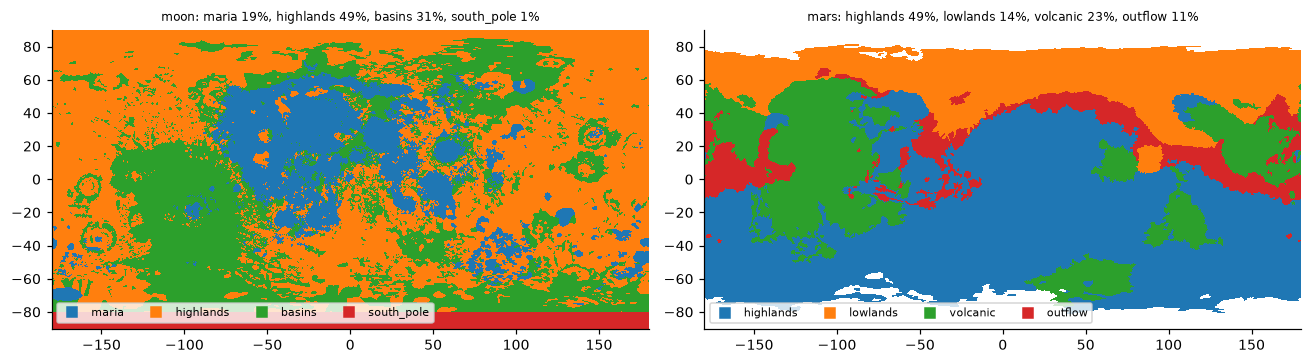

In [5]:
MAP_LAYER = {
    ("moon", "units"): "Unified_Geologic_Map_of_the_Moon_GIS/Lunar_GIS/Shapefiles/GeoUnits",
    ("moon", "lines"): "Unified_Geologic_Map_of_the_Moon_GIS/Lunar_GIS/Shapefiles/Linear_Features",
    ("mars", "units"): "SIM3292_MarsGlobalGeologicGIS_20M/SIM3292_Shapefiles/SIM3292_Global_Geology",
    ("mars", "lines"): "SIM3292_MarsGlobalGeologicGIS_20M/SIM3292_Shapefiles/SIM3292_Global_Structure",
}
REGIONS = {   # (key, title shown on the site). Region code = position + 1.
    "moon": [("maria", "Lunar maria"), ("highlands", "Lunar highlands"),
             ("basins", "Impact basin rings and ejecta"), ("south_pole", "South polar region")],
    "mars": [("highlands", "Southern cratered highlands"), ("lowlands", "Northern lowlands"),
             ("volcanic", "Volcanic provinces"), ("outflow", "Outflow channels and chaos")],
}
MARS_UNITS = {
    "highlands": "eNh mNh lNh Nhu HNhu eHh Nhe mNhm eNhm eHb HNb eAb lHb",
    "lowlands": "mAl lHl",
    "volcanic": "eHv lHv AHv lAv lNv Av lAvf lHvf Hve Nve Ave",
    "outflow": "Hto Ht lHt eHt HNt Htu AHtu",
    "_excluded": "Ap Apu lApc lApd Hp Hpe Hpu",          # polar units: no region
}
FILL, EXCLUDED = 0, 255
RES_DEG = 0.125
REGION_KEYS = [f"{w}:{k}" for w in WORLDS for k, _ in REGIONS[w]]
REGION_TITLE = [t for w in WORLDS for _, t in REGIONS[w]]


def parse_dbf(raw):
    # dBASE table -> list of dicts (all fields as stripped strings).
    n_rec, head_len, rec_len = struct.unpack("<IHH", raw[4:12])
    fields, o = [], 32
    while raw[o] != 0x0D:
        fields.append((raw[o:o + 11].split(b"\0")[0].decode(), raw[o + 16]))
        o += 32
    rows = []
    for i in range(n_rec):
        rec, pos, row = raw[head_len + i * rec_len: head_len + (i + 1) * rec_len], 1, {}
        for name, length in fields:
            row[name] = rec[pos:pos + length].decode("utf-8", "replace").strip()
            pos += length
        rows.append(row)
    return rows


def read_shp_parts(raw):
    # PolyLine / Polygon (also Z and M variants) -> per record, a list of (n, 2) x-y arrays.
    out, o = [], 100
    while o + 8 <= len(raw):
        clen = struct.unpack(">i", raw[o + 4:o + 8])[0] * 2
        c, o = raw[o + 8:o + 8 + clen], o + 8 + clen
        if struct.unpack("<i", c[:4])[0] == 0:
            out.append([])
            continue
        n_parts, n_pts = struct.unpack("<ii", c[36:44])
        starts = np.frombuffer(c, "<i4", n_parts, 44)
        pts = np.frombuffer(c, "<f8", 2 * n_pts, 44 + 4 * n_parts).reshape(-1, 2)
        out.append(np.split(pts, starts[1:]))
    return out


def wrap_lon(lon):
    return (np.asarray(lon) + 180.0) % 360.0 - 180.0


def map_layer(world, kind):
    # One layer of a geologic map as (attribute rows, parts in lon/lat degrees).
    stem = MAP_LAYER[(world, kind)]
    name, d = stem.rsplit("/", 1)[1], RAW / "geology"
    if not all((d / f"{name}{e}").exists() for e in (".shp", ".dbf", ".prj")):
        with zipfile.ZipFile(need(f"geology_{world}")) as zf:
            for ext in (".shp", ".dbf", ".prj"):
                (d / f"{name}{ext}").write_bytes(zf.read(stem + ext))
    attrs = parse_dbf((d / f"{name}.dbf").read_bytes())
    parts = read_shp_parts((d / f"{name}.shp").read_bytes())
    crs = CRS.from_wkt((d / f"{name}.prj").read_text())
    tr = Transformer.from_crs(crs, crs.geodetic_crs, always_xy=True) if crs.is_projected else None
    out = []
    for pp in parts:
        ll = []
        for p in pp:
            x, y = tr.transform(p[:, 0], p[:, 1]) if tr else (p[:, 0], p[:, 1])
            ll.append(np.column_stack([x, y]))
        out.append(ll)
    return attrs, out


def unit_code(world, a):
    # Region code of one map unit: 1..4, FILL (take the surroundings) or EXCLUDED.
    if world == "moon":
        d = a["FIRST_Un_2"].lower()
        if "basin" in d or "formation" in d:
            return 3
        if "mare" in d or "dark mantling" in d:
            return 1
        return FILL if "crater" in d else 2
    for i, (key, _) in enumerate(REGIONS["mars"]):
        if a["Unit"] in MARS_UNITS[key].split():
            return i + 1
    return EXCLUDED if a["Unit"] in MARS_UNITS["_excluded"].split() else FILL


def region_raster(world):
    path = RAW / "geology" / f"regions_{world}_v1.npz"
    if path.exists():
        with np.load(path) as f:
            return f["grid"]
    attrs, parts = map_layer(world, "units")
    shape = (int(180 / RES_DEG), int(360 / RES_DEG))
    T = Affine(RES_DEG, 0, -180, 0, -RES_DEG, 90)
    codes = np.array([unit_code(world, a) for a in attrs])
    grid = np.zeros(shape, np.uint8)
    for c in np.unique(codes):
        if c == FILL:
            continue
        # Every ring is burnt with +1; odd counts are inside (holes cancel), whatever the ring order.
        shapes = [({"type": "Polygon", "coordinates": [ring.tolist()]}, 1)
                  for i in np.flatnonzero(codes == c) for ring in parts[i] if len(ring) >= 4]
        cnt = rasterize(shapes, out_shape=shape, transform=T, merge_alg=MergeAlg.add, dtype="uint8")
        grid[(cnt % 2) == 1] = c
    known = grid != FILL
    idx = ndimage.distance_transform_edt(~known, return_distances=False, return_indices=True)
    grid = grid[tuple(idx)]                                # craters and gaps take the nearest region
    if world == "moon":
        lat = 90 - (np.arange(shape[0]) + 0.5) * RES_DEG
        grid[lat < -80.0, :] = 4
    np.savez_compressed(path, grid=grid)
    return grid


REGION_GRID = {w: region_raster(w) for w in WORLDS}


def region_code(world, lat, lon):
    g = REGION_GRID[world]
    i = np.clip(((90.0 - np.asarray(lat)) / RES_DEG).astype(int), 0, g.shape[0] - 1)
    j = np.clip(((wrap_lon(lon) + 180.0) / RES_DEG).astype(int), 0, g.shape[1] - 1)
    return g[i, j]


fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, w in zip(axes, WORLDS):
    g = REGION_GRID[w]
    area = np.cos(np.radians(90 - (np.arange(g.shape[0]) + 0.5) * RES_DEG))[:, None] * np.ones_like(g, float)
    share = {k: area[g == i + 1].sum() / area.sum() for i, (k, _) in enumerate(REGIONS[w])}
    im = ax.imshow(np.where(g == EXCLUDED, np.nan, g.astype(float)), cmap="tab10", vmin=0.5, vmax=10.5,
                   extent=(-180, 180, -90, 90), interpolation="nearest")
    ax.set_title(f"{w}: " + ", ".join(f"{k} {100 * v:.0f}%" for k, v in share.items()), fontsize=8)
    for i, (k, _) in enumerate(REGIONS[w]):
        ax.plot([], [], "s", color=plt.cm.tab10((i + 0.5) / 10), label=k)
    ax.legend(fontsize=7, loc="lower left", ncol=4)
plt.tight_layout(); plt.show()

In [6]:
def dbf_columns(fobj, cols, chunk=100_000):
    # Stream a few numeric columns out of a big .dbf (the Robbins Moon table is 577 MB unzipped).
    head = fobj.read(32)
    n_rec, head_len, rec_len = struct.unpack("<IHH", head[4:12])
    desc = fobj.read(head_len - 32)
    fields, o = [], 0
    while desc[o] != 0x0D:
        fields.append((desc[o:o + 11].split(b"\0")[0].decode(), desc[o + 16]))
        o += 32
    dt = np.dtype([("_del", "S1")] + [(n, f"S{l}") for n, l in fields])
    out, left = {c: [] for c in cols}, n_rec
    while left > 0:
        k = min(chunk, left)
        arr = np.frombuffer(fobj.read(k * rec_len), dtype=dt, count=k)
        for c in cols:
            out[c].append(pd.to_numeric(pd.Series(arr[c].astype(str)).str.strip(), errors="coerce").values)
        left -= k
    return {c: np.concatenate(v) for c, v in out.items()}


def gazetteer(world):
    with zipfile.ZipFile(need(f"gazetteer_{world}")) as zf:
        df = pd.DataFrame(parse_dbf(zf.read(next(n for n in zf.namelist() if n.lower().endswith(".dbf")))))
    for c in ("diameter", "center_lon", "center_lat", "min_lon", "max_lon", "min_lat", "max_lat"):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df[df.approval.str.startswith("Adopted")].copy()
    df["lon"], df["lat"] = wrap_lon(df.center_lon), df.center_lat
    df["kind"] = df["type"].str.split(",").str[0].str.strip()
    return df.dropna(subset=["lat", "lon"]).reset_index(drop=True)


def robbins(world):
    # Centre and rim diameter of every crater of 1 km and larger. Cut to a small npz on first use.
    small = RAW / "robbins" / f"robbins_{world}.npz"
    if not small.exists():
        with zipfile.ZipFile(need(f"robbins_{world}")) as zf:
            if world == "moon":
                with zf.open(next(n for n in zf.namelist() if n.endswith(".dbf"))) as f:
                    c = dbf_columns(f, ["LAT_EL_IM", "LON_EL_IM", "DIAM_C_IM"])
                lat, lon, d = c["LAT_EL_IM"], c["LON_EL_IM"], c["DIAM_C_IM"]
            else:
                with zf.open(next(n for n in zf.namelist() if n.endswith(".csv"))) as f:
                    c = pd.read_csv(f, usecols=["LAT_CIRC_IMG", "LON_CIRC_IMG", "DIAM_CIRC_IMG"], encoding="utf-8-sig")
                lat, lon, d = c.LAT_CIRC_IMG.values, c.LON_CIRC_IMG.values, c.DIAM_CIRC_IMG.values
        np.savez_compressed(small, lat=lat.astype(np.float32), lon=wrap_lon(lon).astype(np.float32), diameter=d.astype(np.float32))
    with np.load(small) as f:
        return pd.DataFrame({k: f[k].astype(float) for k in f.files}).dropna()


def line_features(world):
    attrs, parts = map_layer(world, "lines")
    return [dict(attrs=a, parts=[np.column_stack([wrap_lon(p[:, 0]), p[:, 1]]) for p in pp], id=f"{world}-line-{i}")
            for i, (a, pp) in enumerate(zip(attrs, parts)) if pp]


def haversine_m(lat1, lon1, lat2, lon2, R):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2) - np.radians(lon1)
    return 2 * R * np.arcsin(np.sqrt(np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2))


def points_along(parts, step_m, R):
    # Points every step_m along a polyline (first one half a step in), as (lat, lon).
    out = []
    for p in parts:
        if len(p) < 2:
            continue
        lon, lat = p[:, 0], p[:, 1]
        seg = haversine_m(lat[:-1], lon[:-1], lat[1:], lon[1:], R)
        seg[np.abs(np.diff(lon)) > 180] = 0.0            # never interpolate across the date line
        cum = np.r_[0.0, np.cumsum(seg)]
        for s in np.arange(step_m / 2, cum[-1], step_m):
            j = min(int(np.searchsorted(cum, s, side="right")) - 1, len(seg) - 1)
            t = (s - cum[j]) / seg[j] if seg[j] > 0 else 0.0
            out.append((lat[j] + t * (lat[j + 1] - lat[j]), lon[j] + t * (lon[j + 1] - lon[j])))
    return out


def destination(lat, lon, dist_m, az, R):
    # Point dist_m from (lat, lon) along azimuth az (radians), on a sphere of radius R.
    p1, l1, d = math.radians(lat), math.radians(lon), dist_m / R
    p2 = math.asin(math.sin(p1) * math.cos(d) + math.cos(p1) * math.sin(d) * math.cos(az))
    l2 = l1 + math.atan2(math.sin(az) * math.sin(d) * math.cos(p1), math.cos(d) - math.sin(p1) * math.sin(p2))
    return math.degrees(p2), (math.degrees(l2) + 180) % 360 - 180


def group_of(world, lat, lon):
    return f"{world}:{int(lat // 10)}:{int(lon // 10)}"


def attr_is(field, *values):
    return lambda a: a.get(field, "") in values


def attr_starts(field, prefix):
    return lambda a: a.get(field, "").lower().startswith(prefix) and "catena" not in a.get("COMMENT", "").lower()


def is_catena(a):
    return "catena" in a.get("COMMENT", "").lower()


ANY = (0.0, 1e9)
CRATER_TAGS = ("small_crater", "crater_rim", "crater_floor", "crater_chain")
TAGS = {   # (tag, source, selector, placement)
    "moon": [
        ("small_crater", "robbins", (1.2, 3.2), "centre"),
        ("crater_rim", "robbins", (8, 60), "rim"),
        ("crater_floor", "robbins", (60, 300), "floor"),
        ("crater_chain", "line", is_catena, "along"),
        ("sinuous_rille", "line", attr_starts("TYPE", "channel"), "along"),
        ("graben", "line", attr_starts("TYPE", "graben"), "along"),
        ("wrinkle_ridge", "line", attr_starts("TYPE", "ridge crest"), "along"),
        ("massif", "gaz", ({"Mons", "Promontorium"}, ANY), "box"),
    ],
    "mars": [
        ("small_crater", "robbins", (1.0, 3.2), "centre"),
        ("crater_rim", "robbins", (8, 60), "rim"),
        ("crater_floor", "robbins", (60, 300), "floor"),
        ("volcanic_edifice", "gaz", ({"Mons", "Tholus", "Patera"}, ANY), "box"),
        ("lava_flow", "line", attr_is("Interpreta", "Lobate flow"), "along"),
        ("wrinkle_ridge", "line", attr_is("Interpreta", "Wrinkle ridge"), "along"),
        ("graben", "line", attr_is("Interpreta", "Graben axis"), "along"),
        ("scarp", "line", attr_is("Interpreta", "Scarp"), "along"),
        ("channel", "line", attr_is("Interpreta", "Channel axis", "Outflow Channel"), "along"),
        ("yardang", "line", attr_is("Interpreta", "Yardangs"), "along"),
        ("mesa", "gaz", ({"Mensa", "Collis"}, ANY), "box"),
        ("chaos", "gaz", ({"Chaos", "Labyrinthus"}, ANY), "box"),
        ("canyon", "gaz", ({"Chasma"}, ANY), "box"),
    ],
}


def tag_candidates(world, tdef, rng, gaz, lines):
    tag, src, sel, how = tdef
    R, cap, out = rt.RADIUS_M[world], CFG["max_per_feature"], []
    if src == "robbins":
        df = robbins(world)
        df = df[df.diameter.between(*sel)]
        for i, r in df.sample(n=min(len(df), 30 * CFG["per_region"]), random_state=int(rng.integers(1 << 31))).iterrows():
            rad_m, az = 500.0 * r.diameter, rng.uniform(0, 2 * np.pi)
            dist = {"centre": 0.0, "rim": rad_m, "floor": rng.uniform(0.2, 0.45) * rad_m}[how]
            lat, lon = destination(r.lat, r.lon, dist, az, R) if dist else (r.lat, r.lon)
            label = {"centre": f"{r.diameter:.1f} km crater", "rim": f"rim of a {r.diameter:.0f} km crater",
                     "floor": f"floor of a {r.diameter:.0f} km crater"}[how]
            out.append((f"{world}-robbins-{i}", r.lat, r.lon, lat, lon, label))
    elif src == "gaz":
        kinds, (dmin, dmax) = sel
        for _, r in gaz[gaz.kind.isin(kinds) & gaz.diameter.between(dmin, dmax)].iterrows():
            for _ in range(cap):
                dlat, dlon = (r.max_lat - r.min_lat) / 2, ((r.max_lon - r.min_lon) % 360.0) / 2
                if not (np.isfinite(dlat) and np.isfinite(dlon)) or dlon > 90 or dlat <= 0:
                    dlat = dlon = math.degrees(500.0 * r.diameter / R)
                lat = float(np.clip(r.lat + rng.uniform(-0.5, 0.5) * dlat, -89.9, 89.9))
                lon = float(wrap_lon(r.lon + rng.uniform(-0.5, 0.5) * dlon))
                out.append((f"{world}-gaz-{r['name']}", r.lat, r.lon, lat, lon, f"{tag.replace('_', ' ')} ({r['name']})"))
    else:
        for f in lines:
            if not sel(f["attrs"]):
                continue
            pts = points_along(f["parts"], CFG["line_step_km"] * 1000.0, R)
            if not pts:
                continue
            ref = pts[len(pts) // 2]
            for j in rng.choice(len(pts), size=min(cap, len(pts)), replace=False):
                out.append((f["id"], ref[0], ref[1], pts[j][0], pts[j][1], tag.replace("_", " ")))
    return out


GAZ = {w: gazetteer(w) for w in WORLDS}
for w in WORLDS:
    print(f"{w}: {len(GAZ[w])} named features, {len(robbins(w))} Robbins craters, {len(line_features(w))} mapped lines")

moon: 9087 named features, 1296758 Robbins craters, 3800 mapped lines
mars: 2055 named features, 385049 Robbins craters, 3593 mapped lines


In [7]:
STAC = "https://stac.astrogeology.usgs.gov/api/search"
KAGUYA = ["kaguya_terrain_camera_usgs_dtms_v2_equi", "kaguya_terrain_camera_usgs_dtms_v2_southpolar",
          "kaguya_terrain_camera_usgs_dtms_v2_northpolar"]


def dtm_href(item):
    a = item["assets"]
    return next(a[k]["href"] for k in ("dtm", "dem", "geoid_adjusted_dem") if k in a)


def kaguya_hrefs(lat, lon, limit=4):
    for coll in KAGUYA:
        body = json.dumps({"collections": [coll], "limit": limit,
                           "intersects": {"type": "Point", "coordinates": [lon, lat]}}).encode()
        items = json.loads(rd.http(STAC, body))["features"]
        if items:
            return [dtm_href(i) for i in items]
    return []


def ctx_footprints():
    # real CTX DTM outlines (not bounding boxes), one ring per polygon part
    with np.load(need("ctx_footprints")) as f:
        href, item, start, xy = f["href"], f["ring_item"], f["ring_start"], f["xy"].astype(np.float64)
    rings, keep = [], []
    for r in range(len(item)):
        ring = xy[start[r]:start[r + 1]].copy()
        ring[:, 0] = np.where(ring[:, 0] > 180, ring[:, 0] - 360, ring[:, 0])
        if len(ring) < 4 or np.ptp(ring[:, 0]) > 180:             # degenerate or wraps the date line
            continue
        rings.append(ring); keep.append(item[r])
    return href, np.array(keep), rings


CTX_HREF, CTX_ITEM, CTX_RINGS = ctx_footprints()
CTX_BOX = np.array([[r[:, 0].min(), r[:, 1].min(), r[:, 0].max(), r[:, 1].max()] for r in CTX_RINGS])
CTX_PATH = [PolyPath(r) for r in CTX_RINGS]
COV_DEG = 0.05
CTX_COVER = rasterize(((dict(type="Polygon", coordinates=[r.tolist()]), 1) for r in CTX_RINGS),
                      out_shape=(int(180 / COV_DEG), int(360 / COV_DEG)), transform=Affine(COV_DEG, 0, -180, 0, -COV_DEG, 90),
                      fill=0, dtype="uint8").astype(bool)
_w = np.cos(np.radians(90 - (np.arange(CTX_COVER.shape[0]) + 0.5) * COV_DEG))[:, None]
print(f"CTX DTMs: {len(CTX_HREF)} with {len(CTX_RINGS)} footprint rings; footprints cover {100 * (CTX_COVER * _w).sum() / (_w.sum() * CTX_COVER.shape[1]):.1f}% of Mars")


def ctx_covered(lat, lon):
    i = np.clip(((90.0 - np.asarray(lat)) / COV_DEG).astype(int), 0, CTX_COVER.shape[0] - 1)
    j = np.clip(((wrap_lon(lon) + 180.0) / COV_DEG).astype(int), 0, CTX_COVER.shape[1] - 1)
    return CTX_COVER[i, j]


def ctx_hrefs(lat, lon, limit=4):
    # DTMs whose real footprint holds the point and a ring of points ctx_inset_km around it, deepest first
    R, d = rt.RADIUS_M["mars"], CFG["ctx_inset_km"] * 1000.0
    ring = np.array([destination(lat, lon, f * d, az, R)[::-1] for f in (0.5, 1.0) for az in np.linspace(0, 2 * np.pi, 8, endpoint=False)])
    cand = np.flatnonzero((CTX_BOX[:, 0] <= lon) & (lon <= CTX_BOX[:, 2]) & (CTX_BOX[:, 1] <= lat) & (lat <= CTX_BOX[:, 3]))
    scored = []
    for r in cand:
        p = CTX_PATH[r]
        if p.contains_point((lon, lat)):
            scored.append((p.contains_points(ring).mean(), r))
    out = []
    for share, r in sorted(scored, reverse=True):
        h = str(CTX_HREF[CTX_ITEM[r]])
        if share == 1.0 and h not in out:
            out.append(h)
    return out[:limit]


def site_hrefs(world, lat, lon):
    if world == "moon":
        return ([POLAR_LOCAL["site"]] if lat <= CFG["polar_lat"] else []) + kaguya_hrefs(lat, lon)
    return ctx_hrefs(lat, lon)


def lat_ok(world, lat):
    lim = np.where((world == "moon") & (np.asarray(lat) <= CFG["polar_lat"]), CFG["polar_max_lat"], CFG["max_lat"])
    return np.abs(lat) <= lim


def sample_background(world, code, n, rng):
    out = []
    for _ in range(400):
        m = 20000
        lon = rng.uniform(-180, 180, m)
        if world == "moon" and code == 4:        # the polar cap is small: sample it directly
            lat = np.degrees(np.arcsin(rng.uniform(np.sin(np.radians(-CFG["polar_max_lat"])), np.sin(np.radians(CFG["polar_lat"])), m)))
        else:
            lat = np.degrees(np.arcsin(rng.uniform(-1, 1, m)))
        ok = (region_code(world, lat, lon) == code) & lat_ok(world, lat)
        if world == "mars":
            ok &= ctx_covered(lat, lon)
        out += list(zip(lat[ok].tolist(), lon[ok].tolist()))
        if len(out) >= n:
            break
    return out[:n]


def nearest_name(world, lat, lon):
    g = GAZ[world]
    d = haversine_m(lat, lon, g.lat.values, g.lon.values, rt.RADIUS_M[world])
    j = int(np.argmin(d))
    return g["name"].iloc[j], d[j] / 1000.0


def library_locations(world, rng):
    # Candidate locations per region (shuffled): half background, half on tagged landforms.
    lines = line_features(world)
    rows = [(t[0], *c) for t in TAGS[world] for c in tag_candidates(world, t, rng, GAZ[world], lines)]
    pool = pd.DataFrame(rows, columns=["tag", "feature", "rlat", "rlon", "lat", "lon", "label"])
    pool = pool[lat_ok(world, pool.lat.values)]
    if world == "mars":
        pool = pool[ctx_covered(pool.lat.values, pool.lon.values)]
    pool = pool.assign(code=region_code(world, pool.lat.values, pool.lon.values))
    out = {}
    for i, (key, title) in enumerate(REGIONS[world]):
        n_target = int(CFG["per_region"] * CFG["oversample"][world])
        sub, locs = pool[pool.code == i + 1], []
        tags = sorted(sub.tag.unique())
        for t in tags:
            st = sub[sub.tag == t]
            cnt = st.groupby("feature").feature.transform("count").values
            k = min(len(st), int(math.ceil(n_target * CFG["tag_share"] / len(tags))))
            for j in rng.choice(len(st), size=k, replace=False, p=(1 / cnt) / (1 / cnt).sum()):
                r = st.iloc[j]
                locs.append(dict(world=world, region=key, tag=t, label=r.label, lat=float(r.lat), lon=float(r.lon),
                                 feature=r.feature, group=group_of(world, r.rlat, r.rlon)))
        for k, (lat, lon) in enumerate(sample_background(world, i + 1, n_target - len(locs), rng)):
            locs.append(dict(world=world, region=key, tag="background", label=title.lower(), lat=lat, lon=lon,
                             feature=f"{world}-{key}-bg-{k}", group=group_of(world, lat, lon)))
        out[key] = [locs[j] for j in rng.permutation(len(locs))]
    return out


READ_STATS = {"site_missing": 0, "striped": 0, "regional_missing": 0, "polar_site": 0}


def read_location(p):
    # One library location at both scales -> tokens, block features and small DEMs. None if unusable.
    world, lat, lon, R = p["world"], p["lat"], p["lon"], rt.RADIUS_M[p["world"]]
    site = None
    for href in site_hrefs(world, lat, lon):
        polar = href == POLAR_LOCAL["site"]
        try:
            dem, native = rd.read_raster_window(href, lat, lon, R, rt.SCALES["site"]["res"], max_nodata=CFG["site_max_nodata"])
        except Exception:
            continue
        stripe = rt.stripe_score(dem[rt.PAD_PX:-rt.PAD_PX, rt.PAD_PX:-rt.PAD_PX])
        if world == "moon" and not polar and stripe > CFG["stripe_max"]:     # stripes are a Kaguya problem, not LOLA
            READ_STATS["striped"] += 1
            continue
        if polar:
            READ_STATS["polar_site"] += 1
            href = rd.POLAR_DEM["site"]                     # store the public URL, so the server can draw it
        site = (dem, native, href, stripe)
        break
    if site is None:
        READ_STATS["site_missing"] += 1
        return None
    reg = None
    for src_ in ([POLAR_LOCAL["regional"]] if world == "moon" and lat <= CFG["polar_lat"] else []) + [rd.GLOBAL_DEM[world]]:
        try:
            reg, _ = rd.read_raster_window(src_, lat, lon, R, rt.SCALES["regional"]["res"], max_nodata=0.05)
            break
        except Exception:
            continue
    if reg is None:
        READ_STATS["regional_missing"] += 1
        return None
    dem, native, href, stripe = site
    ts, bs = rt.compute_features(dem, R, "site")
    tr_, br = rt.compute_features(reg, R, "regional")
    c = slice(rt.PAD_PX, -rt.PAD_PX)
    near, dkm = nearest_name(world, lat, lon)
    return dict(tokens_site=ts.astype(np.float32), block_site=bs, tokens_regional=tr_.astype(np.float32), block_regional=br,
                dem_site=dem[c, c].astype(np.float32), dem_regional=reg[c, c].astype(np.float32),
                href=href, native_m=native, stripe=stripe, name=f"{p['label']}, {dkm:.0f} km from {near}")


LIB_FIELDS = ("world", "region", "tag", "name", "lat", "lon", "feature", "group", "href")


def build_library(world, rng):
    path = CACHE / f"library_{world}_{PROFILE}_{CACHE_TAG}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as f:
            return {k: f[k] for k in f.files}
    locs = library_locations(world, rng)
    kept, cursor = {k: [] for k in locs}, {k: 0 for k in locs}
    for rnd in range(12):
        jobs = []
        for k in locs:
            need = CFG["per_region"] - len(kept[k])
            take = locs[k][cursor[k]:cursor[k] + int(need * (2.2 if world == "moon" else 1.4)) + 4] if need > 0 else []
            cursor[k] += len(take)
            jobs += take
        if not jobs:
            break
        res = run_parallel(read_location, jobs, f"{world} round {rnd + 1}")
        for p, x in zip(jobs, res):
            if x is not None and len(kept[p["region"]]) < CFG["per_region"]:
                kept[p["region"]].append(p | x)
    rows = [r for k in kept for r in kept[k]]
    lib = dict(
        **{f: np.stack([r[f] for r in rows]) for f in ("tokens_site", "block_site", "tokens_regional", "block_regional",
                                                      "dem_site", "dem_regional")},
        native_m=np.array([r["native_m"] for r in rows]), stripe=np.array([r["stripe"] for r in rows]),
        **{c: np.array([r[c] for r in rows]) for c in LIB_FIELDS})
    np.savez_compressed(path, **lib)
    return lib


libs = {w: build_library(w, np.random.default_rng(SEED + i)) for i, w in enumerate(WORLDS)}
print("reads skipped this run:", READ_STATS)
for w, L in libs.items():
    print(f"{w}: {len(L['region'])} blocks from {len(np.unique(L['feature']))} features")
pd.concat({w: pd.crosstab(pd.Series(L["region"], name="region"), pd.Series(L["tag"], name="tag")) for w, L in libs.items()}).fillna(0).astype(int)

CTX DTMs: 44628 with 44646 footprint rings; footprints cover 11.7% of Mars


reads skipped this run: {'site_missing': 0, 'striped': 0, 'regional_missing': 0, 'polar_site': 0}
moon: 2236 blocks from 2078 features
mars: 2400 blocks from 2141 features


tag              background  crater_chain  crater_floor  crater_rim  graben  \
     region                                                                   
moon basins             295            22            54          27      38   
     highlands          234            22            41          20      39   
     maria              365            26            33          11      24   
     south_pole         491             0             3          35       0   
mars highlands          340             0            35          28      23   
     lowlands           514             0             2          34       3   
     outflow            319             0            12          28      28   
     volcanic           334             0            13          26      24   

tag              massif  sinuous_rille  small_crater  wrinkle_ridge  canyon  \
     region                                                                   
moon basins          18             14            23              5       0   
     highlands       44             31            31             78       0   
     maria           32             43            15             51       0   
     south_pole      16              0            55              0       0   
mars highlands        0              0            22             28       9   
     lowlands         0              0            23              6       0   
     outflow          0              0            20             27      21   
     volcanic         0              0            20             30      28   

tag              channel  chaos  lava_flow  mesa  scarp  volcanic_edifice  \
     region                                                                 
moon basins            0      0          0     0      0                 0   
     highlands         0      0          0     0      0                 0   
     maria             0      0          0     0      0                 0   
     south_pole        0      0          0     0      0                 0   
mars highlands        22      3          0    31     20                39   
     lowlands          4      1          4     2      0                 7   
     outflow          20     29          0    30     16                22   
     volcanic         27      2         21    14     26                35   

tag              yardang  
     region               
moon basins            0  
     highlands         0  
     maria             0  
     south_pole        0  
mars highlands         0  
     lowlands          0  
     outflow          28  
     volcanic          0

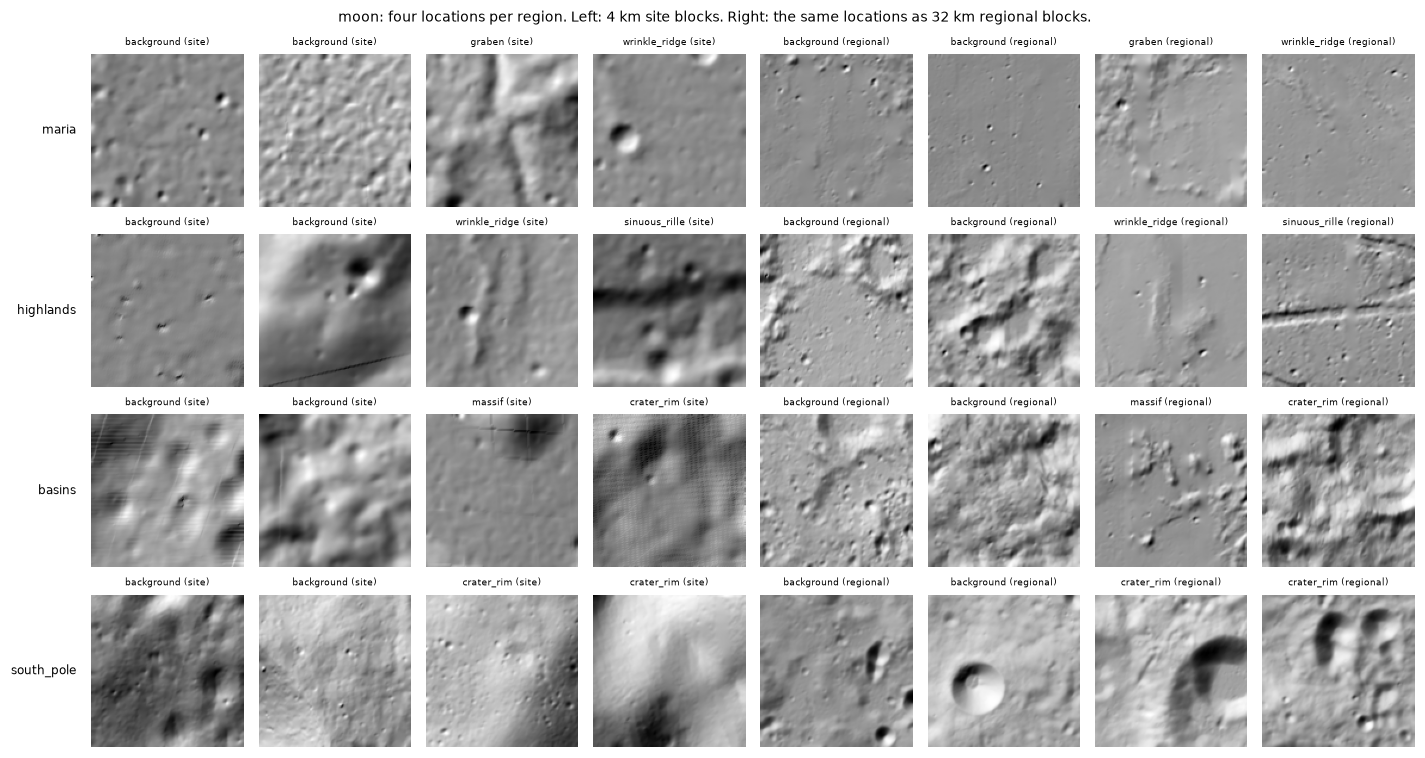

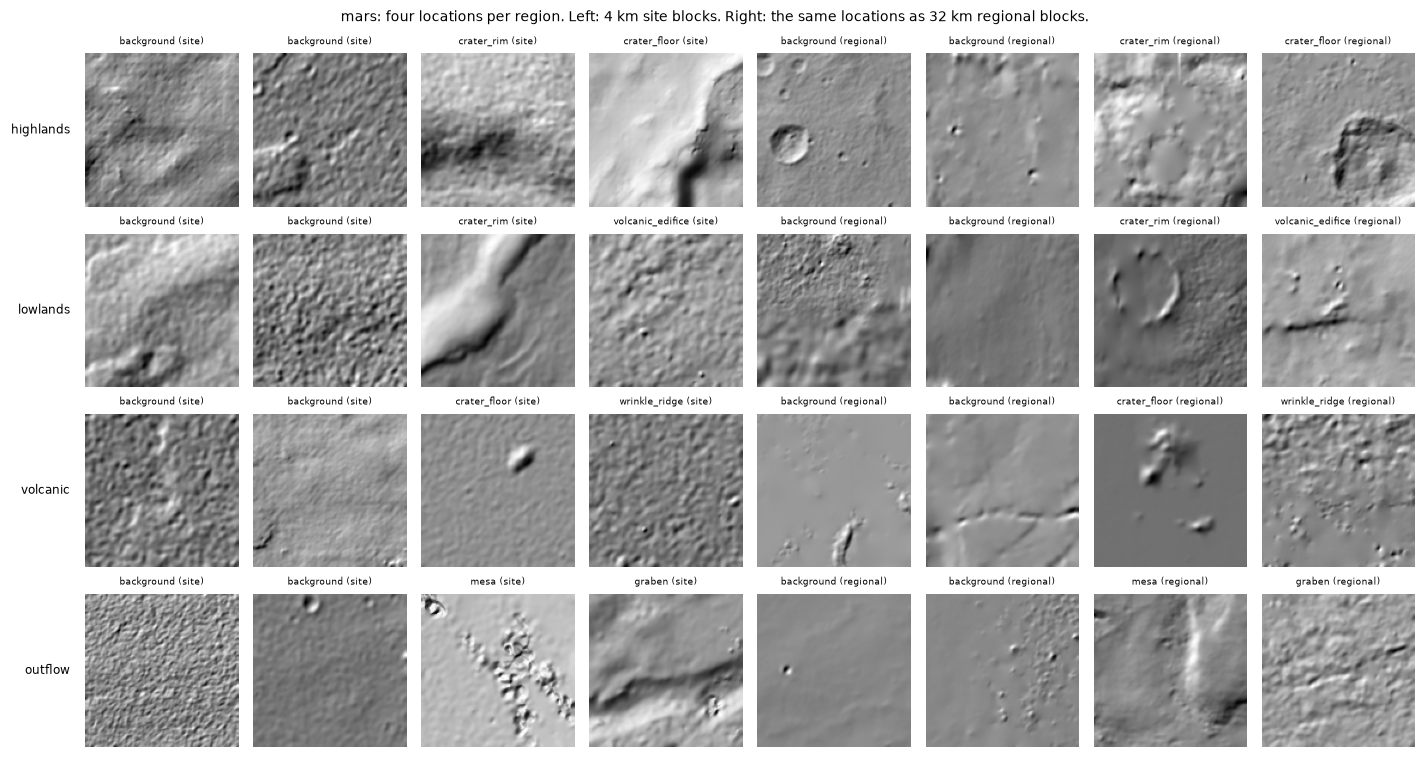

In [8]:
for w in WORLDS:
    L = libs[w]
    fig, axes = plt.subplots(len(REGIONS[w]), 8, figsize=(13, 1.75 * len(REGIONS[w])))
    for r_, (key, title) in enumerate(REGIONS[w]):
        ids = np.r_[np.flatnonzero((L["region"] == key) & (L["tag"] == "background"))[:2],
                    np.flatnonzero((L["region"] == key) & (L["tag"] != "background"))[:2]]
        for k, ax in enumerate(axes[r_]):
            ax.axis("off")
            if k % 4 < len(ids):
                i, s = ids[k % 4], ("site", "regional")[k // 4]
                ax.imshow(hillshade(L[f"dem_{s}"][i].astype(float), rt.SCALES[s]["res"]), cmap="gray")
                ax.set_title(f"{L['tag'][i]} ({s})", fontsize=6)
        axes[r_, 0].text(-0.1, 0.5, key, transform=axes[r_, 0].transAxes, ha="right", va="center", fontsize=8)
    plt.suptitle(f"{w}: four locations per region. Left: 4 km site blocks. Right: the same locations as 32 km regional blocks.", fontsize=9)
    plt.tight_layout(); plt.show()

In [9]:
def precip_grid():
    out = RAW / "climate" / "precip_10m_annual.npy"
    if not out.exists():
        z = need("worldclim")
        out.parent.mkdir(parents=True, exist_ok=True)
        total, bad = None, None
        for m in range(1, 13):
            with rasterio.open(f"zip://{z}!wc2.1_10m_prec_{m:02d}.tif") as ds:
                a = ds.read(1).astype(np.float64)
                miss = (a == ds.nodata) | (a < 0) if ds.nodata is not None else (a < 0)
            total = a if total is None else total + a
            bad = miss if bad is None else bad | miss
        np.save(out, np.where(bad, 65535, np.clip(total, 0, 65534)).astype(np.uint16))
    return np.load(out)


PRECIP = precip_grid()


def aridity_grid():
    # v2.1: Global Aridity Index v3.1 (Zomer, Xu & Trabucco 2022, figshare 7504448, CC BY 4.0), 30 arc-seconds,
    # averaged to the rainfall grid (10 arc-minutes, row 0 = 90 N). stored as AI x 10000; 65535 = unknown (sea, south of 60 S)
    out = RAW / "climate" / "aridity_10m.npy"
    if not out.exists():
        tif = RAW / "climate" / "aridity" / "Global-AI_ET0__annual_v3_1" / "ai_v31_yr.tif"
        g = np.full(PRECIP.shape, 65535, dtype=np.uint16)
        with rasterio.open(tif) as ds:
            rows = int(round((ds.bounds.top - ds.bounds.bottom) / 180.0 * g.shape[0]))
            a = ds.read(1, out_shape=(rows, g.shape[1]), resampling=rasterio.enums.Resampling.average).astype(np.float64)
        r0 = int(round((90.0 - ds.bounds.top) / 180.0 * g.shape[0]))
        g[r0:r0 + rows] = np.clip(a, 0, 65534).astype(np.uint16)
        g[PRECIP >= 65535] = 65535                         # the aridity file has 0 on the sea; keep only land
        np.save(out, g)
    return np.load(out)


ARIDITY = aridity_grid()
print(f"aridity grid: {(ARIDITY < 65535).mean():.0%} of cells known, land median AI {np.median(ARIDITY[ARIDITY < 65535]) / 1e4:.2f}")


class _PrecipOnly:                      # lets rt.precip_at / rt.aridity_at run before the model object exists
    precip = PRECIP
    aridity = ARIDITY


def merged_sites():
    # ml/analog_sites.csv: every site is named by an agency or programme document, or by 3+ peer-reviewed papers,
    # and its coordinates come from a gazetteer or the source itself. sites within 10 km of each other become one
    keep, Re = [], rt.RADIUS_M["earth"]
    cols_ = ["name", "lat", "lon", "world", "kind", "coord_quality", "region_tag", "landform_tag"]
    for s in pd.read_csv(need("analog_sites"))[cols_].fillna("").itertuples(index=False, name=None):
        if all(haversine_m(s[1], s[2], k[1], k[2], Re) > 10e3 for k in keep):
            keep.append(s)
    return keep


def check_site(site):
    # a field site should be mostly bare and dry. if the block is mostly tree/crop/built/water, look within snap_km
    # for the cleanest 4 km block; if nothing nearby is clean, drop the site (it's not a terrain or conditions analog)
    name, lat, lon, w, kind, cq, rtag, ltag = site
    meta = dict(world=w, kind=kind, coord_quality=cq, region_tag=rtag, landform_tag=ltag)
    cover = lambda la, lo: sum(np.nan_to_num(v) for k, v in rd.worldcover_shares(la, lo).items() if k in ("tree", "crop", "built", "water"))
    c0 = cover(lat, lon)
    if c0 <= CFG["cover_max"]:
        return dict(name=name, lat=lat, lon=lon, status="ok", moved_km=0.0, cover=c0, **meta)
    Re, best = rt.RADIUS_M["earth"], (c0, 0.0, lat, lon)
    for d in np.arange(2.0, CFG["snap_km"] + 0.1, 2.0):
        for az in np.linspace(0, 2 * np.pi, 8, endpoint=False):
            la, lo = destination(lat, lon, d * 1000, az, Re)
            c = cover(la, lo)
            if c < best[0] - 1e-6:
                best = (c, d, la, lo)
        if best[0] <= CFG["cover_max"]:
            break
    status = "moved" if best[0] <= CFG["cover_max"] else "dropped"
    return dict(name=name, lat=best[2], lon=best[3], status=status, moved_km=best[1], cover=best[0], **meta)


def checked_sites():
    path = CACHE / f"analog_sites_{CACHE_TAG}_v20.json"
    if path.exists():
        return pd.DataFrame(json.loads(path.read_text()))
    sites = merged_sites()
    res = run_parallel(check_site, sites, "analog sites", every=50)
    df = pd.DataFrame([r if r else dict(name=s[0], lat=s[1], lon=s[2], world=s[3], kind=s[4], coord_quality=s[5], region_tag=s[6],
                                        landform_tag=s[7], status="ok", moved_km=0.0, cover=np.nan)
                       for s, r in zip(sites, res)])
    path.write_text(df.to_json(orient="records"))
    return df


NEGATIVE = [  # standing negative test set: places that should never rank as good analogs. never trained on
    ("Manhattan", 40.78, -73.97), ("Tokyo", 35.68, 139.76), ("Paris", 48.86, 2.35), ("Iowa cornfields", 42.0, -93.6),
    ("Punjab farmland", 30.9, 75.8), ("Congo rainforest", 0.5, 22.0), ("Siberian taiga", 60.0, 100.0), ("Everglades", 25.8, -80.9),
    ("Bangladesh delta", 23.5, 90.3), ("Black Forest", 48.3, 8.2), ("Borneo rainforest", 1.0, 114.0), ("Ganges plain", 26.5, 82.0),
    ("Ukraine wheat belt", 49.0, 32.0), ("Orlando suburbs", 28.5, -81.4), ("Po valley", 45.1, 10.5), ("Mekong delta", 10.0, 105.8),
]
FEATURED = [  # name, lat, lon, expected rank (1 = worst), written before scoring
    ("Dutch farmland", 52.52, 5.60, 1), ("Amazon rainforest", -3.40, -62.00, 1), ("Himalayan ridge", 27.95, 86.95, 2),
    ("Utah near MDRS", 38.40, -110.80, 3), ("Holuhraun lava field", 64.87, -16.83, 4),
    ("Lanzarote Timanfaya", 29.00, -13.75, 5), ("Meteor Crater", 35.027, -111.022, 5),
    ("Haughton crater", 75.38, -89.67, 6), ("McMurdo Dry Valleys", -77.52, 161.80, 6),
]
# name, lat, lon, rim diameter (km): locations from the USGS impact-site list, diameters from Wikidata (ml/earth_craters.csv).
# buried or eroded ones are dropped later by the relief filter
EARTH_CRATERS = list(pd.read_csv(need("earth_craters"))[["name", "lat", "lon", "diameter_km"]].itertuples(index=False, name=None))


def gvp_volcanoes(n, rng):
    path = need("gvp")
    fs = json.loads(path.read_text())["features"]
    keep = [f for f in fs if str(f["properties"].get("Primary_Volcano_Type", "")).startswith(("Shield", "Caldera", "Volcanic field", "Pyroclastic cone"))]
    pick = rng.choice(len(keep), size=min(n, len(keep)), replace=False)
    return [(keep[i]["properties"]["Volcano_Name"], keep[i]["geometry"]["coordinates"][1],
             keep[i]["geometry"]["coordinates"][0]) for i in pick]


def random_land(n, rng):
    tiles, out = rd.glo30_tiles(), []
    while len(out) < n:
        lat, lon = float(np.degrees(np.arcsin(rng.uniform(-1, 1)))), float(rng.uniform(-180, 180))
        if rd.glo30_tile_name(int(np.floor(lat)), int(np.floor(lon))) in tiles:
            out.append((lat, lon))
    return out


def earth_jobs(rng):
    J = lambda name, lat, lon, set_, **k: dict(name=name, lat=float(lat), lon=float(lon), set=set_,
                                               target=k.get("target", ""), expected=k.get("expected", 0),
                                               tag=k.get("tag", ""), split=k.get("split", ""),
                                               kind=k.get("kind", ""), coordq=k.get("coordq", ""), lftag=k.get("lftag", ""))
    jobs = [J(f"random {la:.2f},{lo:.2f}", la, lo, "random") for la, lo in random_land(int(CFG["n_random_land"] * 1.3), rng)]
    Re = rt.RADIUS_M["earth"]
    far = lambda la, lo: all(haversine_m(la, lo, f[1], f[2], Re) > 50e3 for f in FEATURED)
    sites = checked_sites()
    print("analog sites:", sites["status"].value_counts().to_dict())
    sites = sites[sites["status"] != "dropped"]
    sites = sites[[far(a, b) for a, b in zip(sites.lat, sites.lon)]]
    sites = sites.fillna("")
    jobs += [J(r.name, r.lat, r.lon, "analog", target=r.world, tag=r.region_tag, kind=r.kind, coordq=r.coord_quality, lftag=r.landform_tag)
             for r in sites.itertuples()]
    # area sampling (evaluation only): sites whose coordinates are a town or region centre are also read at 8 points
    # area_ring_km out; the evaluation uses the median over the 9 blocks
    # v3.0: every terrain site gets the ring (the heads train on the site and its ring as one bag)
    for r in sites[sites.kind == "terrain"].itertuples():
        for k_, az in enumerate(np.linspace(0, 2 * np.pi, 8, endpoint=False)):
            la2, lo2 = destination(r.lat, r.lon, CFG["area_ring_km"] * 1000, az, Re)
            jobs.append(J(f"{r.name}|{k_}", la2, lo2, "analog_area", target=r.world, tag=r.region_tag, kind=r.kind, coordq="area"))
    # v3.0: the frozen expert list (ml/expert_sites.csv), rated before scoring and never used as training labels.
    # each with the same ring, to see what the best block nearby scores
    for r in pd.read_csv(ROOT / "ml" / "expert_sites.csv").itertuples():
        jobs.append(J(r.name, r.lat, r.lon, "expert", target=r.world, expected=int(r.expert)))
        for k_, az in enumerate(np.linspace(0, 2 * np.pi, 8, endpoint=False)):
            la2, lo2 = destination(r.lat, r.lon, CFG["area_ring_km"] * 1000, az, Re)
            jobs.append(J(f"{r.name}|{k_}", la2, lo2, "expert_area", target=r.world, expected=int(r.expert)))
    jobs += [J(n, la, lo, "negative") for n, la, lo in NEGATIVE]
    jobs += [J(n, la, lo, "featured", expected=e) for n, la, lo, e in FEATURED]
    for k, (n, la, lo, d) in enumerate([c for c in EARTH_CRATERS if c[3] >= CFG["min_crater_km"]]):
        split = "train" if CFG["cross_weight"] > 0 and k % 2 == 0 else "test"      # nothing trains on them when the weight is 0
        if d <= 4.5:
            jobs.append(J(n, la, lo, "crater", tag="small_crater", split=split))
        else:                                               # three rim blocks, 120 degrees apart
            for az in (0.0, 2.094, 4.189):
                la2, lo2 = destination(la, lo, 500.0 * d, az, Re)
                jobs.append(J(f"{n} rim", la2, lo2, "crater", tag="crater_rim", split=split))
    jobs += [J(n, la, lo, "volcano", tag="volcano", split="train" if CFG["cross_weight"] > 0 and k % 2 == 0 else "test")
             for k, (n, la, lo) in enumerate(gvp_volcanoes(CFG["n_volcanoes"], rng))]
    return jobs


def earth_block(job):
    lat, lon, R = job["lat"], job["lon"], rt.RADIUS_M["earth"]
    site = rd.read_glo30_window(lat, lon, rt.SCALES["site"]["res"])
    if np.isnan(site).mean() > 0.5 or rd.flat_fraction(np.nan_to_num(site, nan=-1e9)) > 0.5:
        return None
    reg = rd.read_glo30_window(lat, lon, rt.SCALES["regional"]["res"])
    if np.isnan(reg).mean() > 0.6:
        return None                                         # a small island: no regional context
    ts, bs = rt.compute_features(site, R, "site")
    tr_, br = rt.compute_features(reg, R, "regional")
    env = rd.worldcover_shares(lat, lon)
    env["precip"] = rt.precip_at(_PrecipOnly, lat, lon)
    env["aridity"] = rt.aridity_at(_PrecipOnly, lat, lon)   # v2.1
    return dict(tokens_site=ts.astype(np.float32), block_site=bs, tokens_regional=tr_.astype(np.float32), block_regional=br,
                dem_site=site.astype(np.float32), dem_regional=reg.astype(np.float32), **env)


def build_earth(rng):
    # per-block cache: a block that was already read (same set, name and coordinates) is reused, so changing a
    # site list only reads the new blocks. reads that failed (ocean, lakes) are remembered too
    path = CACHE / f"earth_{PROFILE}_{CACHE_TAG}.npz"
    key = lambda s_, n, la, lo: f"{s_}|{n}|{float(la):.5f}|{float(lo):.5f}"
    old, have, failed, dem_row = None, {}, set(), {}
    if path.exists():
        with np.load(path, allow_pickle=False) as f:
            old = {k: f[k] for k in f.files}
        have = {key(*t): i for i, t in enumerate(zip(old["set"], old["name"], old["lat"], old["lon"]))}
        failed = set(old["failed"].tolist()) if "failed" in old else set()
        dem_row = {int(i): k for k, i in enumerate(old["dem_index"])}
    jobs = earth_jobs(rng)
    keys = [key(j["set"], j["name"], j["lat"], j["lon"]) for j in jobs]
    todo = [i for i, k in enumerate(keys) if k not in have and k not in failed]
    print(f"earth blocks: {len(jobs)} wanted, {len(jobs) - len(todo)} already cached or known to fail, {len(todo)} to read")
    res = dict(zip(todo, run_parallel(earth_block, [jobs[i] for i in todo], "earth"))) if todo else {}
    failed |= {keys[i] for i, r in res.items() if r is None}
    fields = ("tokens_site", "block_site", "tokens_regional", "block_regional")
    kept = []
    for i, (j, k) in enumerate(zip(jobs, keys)):
        if k in have:
            o = have[k]
            r = {f: old[f][o] for f in fields} | {g: float(old[g][o]) if g in old else np.nan for g in rt.ENV_NAMES}
            if o in dem_row:
                r |= dict(dem_site=old["dem_site"][dem_row[o]], dem_regional=old["dem_regional"][dem_row[o]])
        else:
            r = res.get(i)
        if r is None or (j["set"] == "crater" and r["block_site"][0] < CFG["crater_min_relief"]):   # buried or eroded
            continue
        kept.append((j, r))
    # blocks cached before v1.3 have no "sparse" share: re-read WorldCover for them (land cover only, no terrain)
    refill = [k for k, (j, r) in enumerate(kept) if np.isnan(r.get("sparse", np.nan))]
    if refill:
        got = run_parallel(lambda j: rd.worldcover_shares(j["lat"], j["lon"]), [kept[k][0] for k in refill], "worldcover refill", every=500)
        for k, e in zip(refill, got):
            if e:
                kept[k][1].update({g: v for g, v in e.items() if g != "precip"})
    rand = [k for k in kept if k[0]["set"] == "random"][:CFG["n_random_land"]]
    kept = rand + [k for k in kept if k[0]["set"] != "random"]
    keep_dem = np.array([j["set"] in ("featured", "analog", "crater", "negative") and "dem_site" in r for j, r in kept])
    E = dict(
        **{c: np.array([j[c] for j, _ in kept]) for c in ("name", "lat", "lon", "set", "target", "expected", "tag", "split", "kind", "coordq", "lftag")},
        **{f: np.stack([r[f] for _, r in kept]) for f in fields},
        dem_site=np.stack([r["dem_site"] for (j, r), k in zip(kept, keep_dem) if k]).astype(np.float32),
        dem_regional=np.stack([r["dem_regional"] for (j, r), k in zip(kept, keep_dem) if k]).astype(np.float32),
        dem_index=np.flatnonzero(keep_dem),
        **{g: np.array([r[g] for _, r in kept], dtype=float) for g in rt.ENV_NAMES},
        failed=np.array(sorted(failed) or [""]))
    np.savez_compressed(path, **E)
    return E


earth = build_earth(np.random.default_rng(SEED + 7))
earth_group = np.array([f"{int(a // 5)}:{int(b // 5)}" for a, b in zip(earth["lat"], earth["lon"])])
print(pd.Series(earth["set"]).value_counts().to_dict())
pd.DataFrame({g: earth[g] for g in rt.ENV_NAMES}).groupby(earth["set"]).mean().round(2)

aridity grid: 25% of cells known, land median AI 0.67


analog sites: {'ok': 76, 'dropped': 16, 'moved': 13}
earth blocks: 4394 wanted, 4301 already cached or known to fail, 93 to read


  [earth] 93/93 done, 93 ok, 25s


  [worldcover refill] 22/22 done, 22 ok, 0s


{'random': 2500, 'analog_area': 449, 'volcano': 250, 'expert_area': 155, 'analog': 77, 'crater': 74, 'expert': 20, 'negative': 16, 'featured': 9}


,tree,crop,built,water,snow,bare,sparse,precip,aridity
analog,0.04,0.00,0.01,0.01,0.01,0.55,0.38,423.12,NaN
analog_area,0.07,0.01,0.00,0.02,0.02,0.51,0.37,416.55,0.75
crater,0.26,0.11,0.01,0.07,0.00,0.21,0.34,549.15,NaN
expert,0.10,0.07,0.01,0.08,0.01,0.49,0.23,541.80,0.94
expert_area,0.10,0.09,0.01,0.02,0.03,0.48,0.25,553.38,0.92
featured,0.11,0.09,0.00,0.00,0.22,0.48,0.09,642.56,NaN
negative,0.39,0.20,0.26,0.09,0.00,0.00,0.06,1316.44,NaN
random,0.30,0.09,0.01,0.03,0.11,0.15,0.31,743.52,NaN
volcano,0.33,0.04,0.01,0.05,0.06,0.19,0.33,1091.57,NaN


In [10]:
lib = {k: np.concatenate([libs[w][k] for w in WORLDS]) for k in libs["moon"]}
N_LIB = len(lib["region"])
lib_region = np.array([REGION_KEYS.index(f"{w}:{r}") for w, r in zip(lib["world"], lib["region"])])
lib_group, lib_tag = lib["group"], lib["tag"]
world_idx = {w: np.flatnonzero(lib["world"] == w) for w in WORLDS}
members = [np.flatnonzero(lib_region == r) for r in range(len(REGION_KEYS))]
rand = earth["set"] == "random"

# v2.0: each new spatial feature must pass a planet check before the model may use it (balanced 5-NN vote)
NEW_TOK = ("tpi_near", "tpi_far")
NEW_BLK = tuple(b for b in rt.BLOCK_FEATURES if b.startswith(("spec", "bowl", "cone")))
PLANET_REF = {"site": 0.633, "regional": 0.678}          # v1.3, all features, same test (diag.ipynb D0)


def planet_check(Xw, k=5, reps=10, seed=0):
    r_ = np.random.default_rng(seed)
    n = min(min(len(v) for v in Xw), 600)
    acc = []
    for _ in range(reps):
        X = np.concatenate([v[r_.choice(len(v), n, replace=False)] for v in Xw])
        y = np.repeat(np.arange(len(Xw)), n)
        D = ((X[:, None] - X[None]) ** 2).sum(-1)
        np.fill_diagonal(D, np.inf)
        nb = y[np.argsort(D, 1)[:, :k]]
        acc.append(np.mean(np.array([np.bincount(row, minlength=len(Xw)).argmax() for row in nb]) == y))
    return float(np.mean(acc))


rows_p, CFG["drop_block"] = [], {s: () for s in SCALES}
for s in SCALES:
    wt = [lib[f"tokens_{s}"][lib["world"] == w].astype(float) for w in WORLDS] + [earth[f"tokens_{s}"][rand].astype(float)]
    wb = [lib[f"block_{s}"][lib["world"] == w].astype(float) for w in WORLDS] + [earth[f"block_{s}"][rand].astype(float)]
    cells_ = np.concatenate([x.reshape(-1, rt.N_TOK) for x in wt])
    q25_, q75_ = np.percentile(cells_, [25, 75], axis=0)
    sc_ = np.where(q75_ - q25_ > 1e-9, q75_ - q25_, 1.0)
    sk_ = [rt.sketch_raw(x / sc_) for x in wt]
    col = lambda f: [q * rt.N_TOK + rt.TOKEN_FEATURES.index(f) for q in range(len(rt.QUANTILES))]
    drop_t, drop_b = list(CFG["drop"].get(s, ())), []
    for f in NEW_TOK:
        a = planet_check([x[:, col(f)] for x in sk_])
        rows_p.append(dict(scale=s, feature=f, kind="token", alone=a))
        if a > CFG["planet_alone_max"]:
            drop_t.append(f)
    for b in NEW_BLK:
        j = rt.BLOCK_FEATURES.index(b)
        pool = np.concatenate([x[:, j] for x in wb])
        iqr = np.subtract(*np.nanpercentile(pool, [75, 25])) or 1.0
        a = planet_check([np.nan_to_num(x[:, j:j + 1] / iqr) for x in wb])
        rows_p.append(dict(scale=s, feature=b, kind="block", alone=a))
        if a > CFG["planet_alone_max"]:
            drop_b.append(b)
    keep = lambda drops: [c for f in rt.TOKEN_FEATURES if f not in drops for c in col(f)]
    comb = planet_check([x[:, keep(drop_t)] for x in sk_])
    while comb > PLANET_REF[s] + 0.02:            # still worse than v1.3: drop the worst remaining new token feature
        left = [r_ for r_ in rows_p if r_["scale"] == s and r_["kind"] == "token" and r_["feature"] not in drop_t]
        if not left:
            break
        drop_t.append(max(left, key=lambda r_: r_["alone"])["feature"])
        comb = planet_check([x[:, keep(drop_t)] for x in sk_])
    CFG["drop"][s], CFG["drop_block"][s] = tuple(drop_t), tuple(drop_b)
    print(f"{s}: planet check with every kept feature {comb:.3f} (v1.3: {PLANET_REF[s]:.3f}); "
          f"switched off: tokens {list(drop_t)}, block features {drop_b}")
print(pd.DataFrame(rows_p).round(3).to_string(index=False))

SC = {}
for s in SCALES:
    lt, et = lib[f"tokens_{s}"].astype(float), earth[f"tokens_{s}"].astype(float)
    cells = np.concatenate([lt, et[rand]]).reshape(-1, rt.N_TOK)
    q25, q75 = np.percentile(cells, [25, 75], axis=0)
    scale = np.where(q75 - q25 > 1e-9, q75 - q25, np.where(cells.std(0) > 1e-9, cells.std(0), 1.0))
    for f_ in CFG["drop"].get(s, ()):            # a dropped feature scales to 0, so sketches, matching and curves ignore it
        scale[rt.TOKEN_FEATURES.index(f_)] = np.inf
    lt, et = lt / scale, et / scale
    bmask = np.array([0.0 if b in CFG["drop_block"].get(s, ()) else 1.0 for b in rt.BLOCK_FEATURES])
    raw_sk = rt.sketch_raw(np.concatenate([lt, et[rand]]))
    pca_mean = raw_sk.mean(0)
    pca_comp = np.linalg.svd(raw_sk - pca_mean, full_matrices=False)[2][:32]
    SC[s] = dict(scale=scale, pca_mean=pca_mean, pca_comp=pca_comp,
                 lib_tok=lt, lib_blk=lib[f"block_{s}"].astype(float) * bmask, lib_sk=(rt.sketch_raw(lt) - pca_mean) @ pca_comp.T, block_mask=bmask,
                 earth_tok=et, earth_blk=earth[f"block_{s}"].astype(float) * bmask, earth_sk=(rt.sketch_raw(et) - pca_mean) @ pca_comp.T)


def pair_rows(s, pairs, earth_anchor=False):
    P = SC[s]
    A_tok, A_blk = (P["earth_tok"], P["earth_blk"]) if earth_anchor else (P["lib_tok"], P["lib_blk"])
    pairs = np.asarray(pairs)
    raw = np.empty((len(pairs), rt.N_IN))
    order = np.argsort(pairs[:, 0], kind="stable")
    cuts = np.flatnonzero(np.diff(pairs[order, 0])) + 1
    for rows in np.split(order, cuts):
        a, bs = pairs[rows[0], 0], pairs[rows, 1]
        raw[rows] = rt.pair_inputs_many(A_tok[a], P["lib_tok"][bs], A_blk[a], P["lib_blk"][bs])[0]
    return raw


t0 = time.time()
r_t = np.random.default_rng(SEED + 4)
n_tab = 6000
ll = np.concatenate([np.c_[r_t.choice(world_idx[w], n_tab // 2), r_t.choice(world_idx[w], n_tab // 2)] for w in WORLDS])
ll = ll[ll[:, 0] != ll[:, 1]]
el = np.c_[r_t.choice(np.flatnonzero(rand), n_tab), r_t.choice(N_LIB, n_tab)]
for s in SCALES:
    SC[s]["pct_table"] = np.quantile(np.concatenate([pair_rows(s, ll), pair_rows(s, el, True)]), rt.GRID, axis=0).T   # (19, 1001)
print(f"{N_LIB} library locations x {len(SCALES)} scales; percentile tables from {len(ll) + len(el)} pairs per scale ({time.time() - t0:.0f}s)")

site: planet check with every kept feature 0.653 (v1.3: 0.633); switched off: tokens ['rough_coarse'], block features []


regional: planet check with every kept feature 0.678 (v1.3: 0.678); switched off: tokens [], block features []
   scale  feature  kind  alone
    site tpi_near token  0.464
    site  tpi_far token  0.411
    site    spec1 block  0.343
    site    spec2 block  0.334
    site    spec3 block  0.402
    site    spec4 block  0.435
    site    spec5 block  0.499
    site    spec6 block  0.536
    site     bowl block  0.336
    site   bowl_r block  0.340
    site     cone block  0.333
    site   cone_r block  0.349
regional tpi_near token  0.429
regional  tpi_far token  0.388
regional    spec1 block  0.368
regional    spec2 block  0.345
regional    spec3 block  0.388
regional    spec4 block  0.421
regional    spec5 block  0.464
regional    spec6 block  0.540
regional     bowl block  0.348
regional   bowl_r block  0.329
regional     cone block  0.342
regional   cone_r block  0.327


4636 library locations x 2 scales; percentile tables from 11998 pairs per scale (4s)


In [11]:
class MonotoneBasis:
    # Cubic B-splines on [0, 1]; I-spline columns = reversed cumulative sums (each a 0 -> 1 ramp).
    def __init__(self, n_segments=10, degree=3):
        inner = np.linspace(0.0, 1.0, n_segments + 1)
        self.knots, self.degree = np.r_[[0.0] * degree, inner, [1.0] * degree], degree
        self.n_cols = n_segments + degree - 1

    def ispline(self, z):
        from scipy.interpolate import BSpline
        B = BSpline.design_matrix(np.clip(np.asarray(z, float), 0, 1), self.knots, self.degree).toarray()
        return np.cumsum(B[:, ::-1], axis=1)[:, ::-1][:, 1:]

    def smooth_penalty(self):
        D = np.diff(np.eye(self.n_cols), axis=0)
        return D.T @ D


BASIS = MonotoneBasis(CFG["n_segments"])
GRID_I = BASIS.ispline(rt.GRID)


def ncols(kind):
    return 1 if kind == "M1" else BASIS.n_cols


def design(Z, signs, kind):
    # [term columns | intercept]
    blocks = [s * (np.clip(Z[:, k], 0, 1)[:, None] if kind == "M1" else BASIS.ispline(Z[:, k])) for k, s in enumerate(signs)]
    return np.hstack(blocks + [np.ones((len(Z), 1))])


def penalty(n_terms, kind, lam_s, lam_r):
    nc = ncols(kind)
    P = np.zeros((n_terms * nc + 1,) * 2)
    blk = (lam_s * BASIS.smooth_penalty() + lam_r * np.eye(nc)) if kind == "M2" else lam_r * np.eye(1)
    for k in range(n_terms):
        P[k * nc:(k + 1) * nc, k * nc:(k + 1) * nc] = blk
    return P


def fit(X, y, w, P):
    ypm = np.where(y == 1, 1.0, -1.0)

    def f(th):
        m = ypm * (X @ th)
        Pt = P @ th
        return w @ np.logaddexp(0, -m) + th @ Pt, X.T @ (w * -ypm * expit(-m)) + 2 * Pt

    bounds = [(0.0, None)] * (X.shape[1] - 1) + [(None, None)]
    return minimize(f, np.zeros(X.shape[1]), jac=True, method="L-BFGS-B", bounds=bounds,
                    options=dict(maxiter=3000, ftol=1e-11, gtol=1e-8)).x


def balanced(y, mult=None):
    m = np.ones(len(y)) if mult is None else mult.astype(float)
    w = np.zeros(len(y))
    for c in (0, 1):
        s = y == c
        if s.any():
            w[s] = 0.5 * m[s] / m[s].sum()
    return w


def curve_tables(th, signs, kind):
    # Curves on GRID, each centred to mean 0 (a typical pair gets 0); constants move into the bias.
    nc, curves = ncols(kind), []
    for k, s in enumerate(signs):
        beta = th[k * nc:(k + 1) * nc]
        curves.append(s * (rt.GRID * beta[0] if kind == "M1" else GRID_I @ beta))
    curves = np.array(curves)
    centres = curves.mean(1)
    return curves - centres[:, None], float(th[-1] + centres.sum())


def group_folds(groups, k, seed):
    u = np.unique(groups)
    np.random.default_rng(seed).shuffle(u)
    f = {g: i % k for i, g in enumerate(u)}
    return np.array([f[g] for g in groups])


PAIR_SIGNS = [-1.0] * rt.N_IN
lib_fold = group_folds(lib_group, CFG["folds"], SEED + 11)
earth_fold = group_folds(earth_group, CFG["folds"], SEED + 12)
tag_key = np.array([t if t != "background" else f"bg:{r}" for t, r in zip(lib_tag, lib["region"])])
LABELS = {"region": lib_region, "tag": np.unique(np.char.add(np.char.add(lib["world"], ":"), tag_key), return_inverse=True)[1]}

In [12]:
def library_triplets(label, rng):
    lab, rows = LABELS[label], []
    for w in WORLDS:
        idx = world_idx[w]
        anchors = rng.choice(idx, size=min(len(idx), CFG["max_anchors"] // 2), replace=False)
        for a in anchors:
            same = idx[(lab[idx] == lab[a]) & (lib_group[idx] != lib_group[a])]
            diff = idx[lab[idx] != lab[a]]
            if len(same) == 0 or len(diff) == 0:
                continue
            pos = rng.choice(same, size=min(CFG["pos_per_block"], len(same)), replace=False)
            rows += [(a, p, n) for p, n in zip(pos, rng.choice(diff, size=len(pos)))]
    return np.array(rows)


def cross_triplets(rng, per_anchor=12):
    is_crater = np.isin(lib_tag, CRATER_TAGS)
    smooth_bg = (lib_tag == "background") & np.isin(lib["region"], ["maria", "lowlands", "volcanic"])
    not_crater = (~is_crater & (lib_tag != "background")) | smooth_bg
    volcanic = lib_region == REGION_KEYS.index("mars:volcanic")
    rows = []
    for e in np.flatnonzero((earth["split"] == "train") & np.isin(earth["set"], ["crater", "volcano"])):
        for w in WORLDS:
            inw = lib["world"] == w
            if earth["set"][e] == "crater":
                pos, neg = np.flatnonzero(inw & (lib_tag == earth["tag"][e])), np.flatnonzero(inw & not_crater)
            elif w == "mars":
                pos, neg = np.flatnonzero(inw & volcanic), np.flatnonzero(inw & ~volcanic)
            else:
                continue
            if len(pos) and len(neg):
                k = min(per_anchor, len(pos))
                rows += [(e, p, n) for p, n in zip(rng.choice(pos, size=k, replace=False), rng.choice(neg, size=k))]
    return np.array(rows).reshape(-1, 3)


t0 = time.time()
rng_t = np.random.default_rng(SEED + 20)
X_TRIP = cross_triplets(rng_t)
TR = {}
for label in LABELS:
    L_TRIP = library_triplets(label, rng_t)
    n_l, n_x = len(L_TRIP), len(X_TRIP)
    cw = CFG["cross_weight"] if n_x else 0.0
    folds3 = np.r_[lib_fold[L_TRIP], np.c_[earth_fold[X_TRIP[:, 0]], lib_fold[X_TRIP[:, 1:]]]] if n_x else lib_fold[L_TRIP]
    anchor_group = np.r_[lib_group[L_TRIP[:, 0]], np.char.add("earth:", earth_group[X_TRIP[:, 0]])] if n_x else lib_group[L_TRIP[:, 0]]
    for s in SCALES:
        tab = SC[s]["pct_table"]
        Zp = rt.to_z(tab, np.r_[pair_rows(s, L_TRIP[:, [0, 1]]), pair_rows(s, X_TRIP[:, [0, 1]], True)] if n_x else pair_rows(s, L_TRIP[:, [0, 1]]))
        Zn = rt.to_z(tab, np.r_[pair_rows(s, L_TRIP[:, [0, 2]]), pair_rows(s, X_TRIP[:, [0, 2]], True)] if n_x else pair_rows(s, L_TRIP[:, [0, 2]]))
        TR[(s, label)] = dict(Zp=Zp, Zn=Zn, folds3=folds3, is_cross=np.r_[np.zeros(n_l, bool), np.ones(n_x, bool)],
                              anchor_group=anchor_group,
                              D={k: design(Zp, PAIR_SIGNS, k) - design(Zn, PAIR_SIGNS, k) for k in ("M1", "M2")})
    print(f"label {label}: {n_l} library triplets + {n_x} cross-world triplets ({time.time() - t0:.0f}s)")


# v2.0 joint loss: region triplets and landform triplets together
for s in SCALES:
    ra, ta = TR[(s, "region")], TR[(s, "tag")]
    TR[(s, "joint")] = dict(Zp=np.r_[ra["Zp"], ta["Zp"]], Zn=np.r_[ra["Zn"], ta["Zn"]], folds3=np.r_[ra["folds3"], ta["folds3"]],
                            is_cross=np.r_[ra["is_cross"], ta["is_cross"]], anchor_group=np.r_[ra["anchor_group"], ta["anchor_group"]],
                            D={k: np.r_[ra["D"][k], ta["D"][k]] for k in ra["D"]},
                            mult=np.r_[np.ones(len(ra["is_cross"])), np.full(len(ta["is_cross"]), CFG["joint_beta"])])


def train(s, label, kind, lam_s, mask, use_cross=True, mult=None):
    T = TR[(s, label)]
    m = mask & (use_cross | ~T["is_cross"])
    cross = T["is_cross"][m]
    base = np.ones(m.sum()) if mult is None else mult[m].astype(float)
    if "mult" in T:                              # joint loss: landform triplets carry joint_beta of a region triplet's weight
        base = base * T["mult"][m]
    w = np.zeros(m.sum())
    cw = CFG["cross_weight"] if (cross.any() and use_cross) else 0.0
    w[~cross] = (1 - cw) * base[~cross] / base[~cross].sum()
    if cw:
        w[cross] = cw * base[cross] / base[cross].sum()
    th = fit(T["D"][kind][m], np.ones(m.sum(), int), w, penalty(rt.N_IN, kind, lam_s, CFG["lam_r"]))
    curves, _ = curve_tables(th, PAIR_SIGNS, kind)
    lm = m & ~T["is_cross"]
    sc = np.r_[rt.curves_at(curves, T["Zp"][lm]).sum(1), rt.curves_at(curves, T["Zn"][lm]).sum(1)]
    y = np.r_[np.ones(lm.sum(), int), np.zeros(lm.sum(), int)]
    ab = fit(np.c_[sc, np.ones_like(sc)], y, balanced(y), np.zeros((2, 2)))          # a >= 0, b free
    return curves * ab[0], float(ab[1])


def ranking_loss(s, label, kind, model_, mask):
    T = TR[(s, label)]
    m = mask & ~T["is_cross"]
    d = rt.curves_at(model_[0], T["Zp"][m]).sum(1) - rt.curves_at(model_[0], T["Zn"][m]).sum(1)
    return float(np.mean(np.logaddexp(0, -d)))

label region: 24000 library triplets + 0 cross-world triplets (16s)


label tag: 24000 library triplets + 0 cross-world triplets (33s)


In [13]:
rng_e = np.random.default_rng(SEED + 30)
Q = np.sort(np.concatenate([rng_e.choice(m, size=min(len(m), CFG["n_eval"]), replace=False) for m in members]))
world_regions = {w: [r for r, k in enumerate(REGION_KEYS) if k.startswith(w + ":")] for w in WORLDS}
NR, S_ = max(len(v) for v in world_regions.values()), CFG["shortlist"]
q_region = lib_region[Q]
q_regs = np.array([world_regions[lib["world"][q]] for q in Q])                 # (|Q|, 4) region ids, in order


def top_k_for(n_members):
    return max(3, min(CFG["top_k"], n_members // 4))


t0 = time.time()
EV = {}
for s in SCALES:
    P = SC[s]
    short = np.full((len(Q), NR, S_), -1)
    raw = np.zeros((len(Q), NR, S_, rt.N_IN), np.float32)
    n_mem = np.zeros((len(Q), NR), int)
    for i, q in enumerate(Q):
        for c, r in enumerate(q_regs[i]):
            mem = members[r][lib_group[members[r]] != lib_group[q]]
            n_mem[i, c] = len(mem)
            sh = mem[np.argsort(((P["lib_sk"][mem] - P["lib_sk"][q]) ** 2).sum(1))[:S_]]
            short[i, c, :len(sh)] = sh
            raw[i, c, :len(sh)] = rt.pair_inputs_many(P["lib_tok"][q], P["lib_tok"][sh], P["lib_blk"][q], P["lib_blk"][sh])[0]
    EV[s] = dict(short=short, raw=raw, n_mem=n_mem, W=raw[..., :rt.N_TOK].sum(-1))
print(f"{len(Q)} evaluation queries, {int((EV['site']['short'] >= 0).sum())} pairs per scale ({time.time() - t0:.0f}s)")


LAM_W, LOGW = 0.0, {}          # v2.0 library weighting, set after the final fits


def eval_logits(s, model_):
    E = EV[s]
    if model_ is None:
        L = -E["W"].astype(float)
    else:
        Z = rt.to_z(SC[s]["pct_table"], E["raw"].reshape(-1, rt.N_IN))
        L = (model_[1] + rt.curves_at(model_[0], Z).sum(1)).reshape(E["W"].shape)
    if LAM_W and s in LOGW:
        L = L + LAM_W * LOGW[s][np.maximum(E["short"], 0)]
    return np.where(E["short"] >= 0, L, -np.inf)


def aggregates(s, L):
    # Mean of the top-k pair logits per (query, region), the same rule as rt.region_scores.
    A = np.full(L.shape[:2], np.nan)
    Ls = -np.sort(-L, axis=2)
    for i in range(L.shape[0]):
        for c in range(L.shape[1]):
            if EV[s]["n_mem"][i, c] >= 4:
                A[i, c] = Ls[i, c, :top_k_for(EV[s]["n_mem"][i, c])].mean()
    return A


def calibrated_scores(A, calib_mask, query_mask):
    own_col = np.array([list(q_regs[i]).index(q_region[i]) for i in range(len(Q))])
    own = A[np.arange(len(Q)), own_col]
    out = np.full(A.shape, np.nan)
    for r in range(len(REGION_KEYS)):
        cal = np.sort(own[(q_region == r) & calib_mask & ~np.isnan(own)])
        if len(cal) == 0:
            continue
        for i in np.flatnonzero(query_mask):
            c = np.flatnonzero(q_regs[i] == r)
            if len(c) and not np.isnan(A[i, c[0]]):
                out[i, c[0]] = rt.calibrated(cal, A[i, c[0]], drop_self=own[i] if (q_region[i] == r and calib_mask[i]) else None)
    return out


def region_accuracy(score, mask):
    pred = q_regs[np.arange(len(Q)), np.nanargmax(np.where(np.isnan(score), -1e9, score), axis=1)]
    hit = pred == q_region
    return float(np.mean([hit[mask & (q_region == r)].mean() for r in np.unique(q_region[mask])])), pred


def p_at_10(s, L, mask):
    reg, tag = [], []
    for i in np.flatnonzero(mask):
        flat, ids = L[i].ravel(), EV[s]["short"][i].ravel()
        top = ids[np.argsort(-flat)[:10]]
        top = top[top >= 0]
        reg.append(np.mean(lib_region[top] == q_region[i]))
        if lib_tag[Q[i]] != "background":
            tag.append(np.mean(lib_tag[top] == lib_tag[Q[i]]))
    return float(np.mean(reg)), float(np.mean(tag)) if tag else np.nan

1200 evaluation queries, 480000 pairs per scale (135s)


In [14]:
VARIANTS = [("M0", None, "M0"), ("joint M1", "joint", "M1"), ("region M1", "region", "M1"), ("tag M1", "tag", "M1"),
            ("region M2", "region", "M2"), ("tag M2", "tag", "M2")]
q_fold = lib_fold[Q]
cv = {s: {v[0]: [] for v in VARIANTS} for s in SCALES}
oof = {s: {v[0]: np.full((len(Q), NR), np.nan) for v in VARIANTS} for s in SCALES}
lam_pick = {s: {v[0]: [] for v in VARIANTS} for s in SCALES}
t0 = time.time()
for s in SCALES:
    for f in range(CFG["folds"]):
        te, tr = q_fold == f, q_fold != f
        for name, label, kind in VARIANTS:
            if kind == "M0":
                m = None
            else:
                tmask = (TR[(s, label)]["folds3"] != f).all(1)
                lam = CFG["lam_s_grid"][1]
                if kind == "M2":        # pick the smoothness on one inner fold of the training groups
                    v = (f + 1) % CFG["folds"]
                    inner, val = tmask & (TR[(s, label)]["folds3"] != v).all(1), tmask & (TR[(s, label)]["folds3"][:, 0] == v)
                    lam = min(CFG["lam_s_grid"], key=lambda l: ranking_loss(s, label, kind, train(s, label, kind, l, inner), val))
                lam_pick[s][name].append(lam)
                m = train(s, label, kind, lam, tmask)
            L = eval_logits(s, m)
            score = calibrated_scores(aggregates(s, L), tr, te)
            acc, _ = region_accuracy(score, te)
            pr, pt = p_at_10(s, L, te)
            cv[s][name].append(dict(region_acc=acc, p10_region=pr, p10_tag=pt))
            oof[s][name][te] = score[te]
        print(f"{s} fold {f}: " + "  ".join(f"{n} {cv[s][n][-1]['region_acc']:.2f}" for n, _, _ in VARIANTS) + f"  ({time.time() - t0:.0f}s)")

CHOSEN = {}
for s in SCALES:
    ms = {n: (np.mean([r["region_acc"] for r in v]), np.std([r["region_acc"] for r in v], ddof=1) / np.sqrt(len(v))) for n, v in cv[s].items()}
    best = max((n for n, _, k in VARIANTS if k != "M0"), key=lambda n: ms[n][0])
    CHOSEN[s] = next(v for v in VARIANTS[1:] if ms[v[0]][0] >= ms[best][0] - ms[best][1])
    print(f"{s}: ships '{CHOSEN[s][0]}' (region accuracy {ms[CHOSEN[s][0]][0]:.3f}; untrained M0 {ms['M0'][0]:.3f}; chance 0.25)")
pd.concat({s: pd.DataFrame({n: {k: f"{np.mean([r[k] for r in v]):.3f} ± {np.std([r[k] for r in v], ddof=1) / np.sqrt(len(v)):.3f}"
                                 for k in ("region_acc", "p10_region", "p10_tag")} for n, v in cv[s].items()}).T for s in SCALES})

site fold 0: M0 0.40  joint M1 0.36  region M1 0.34  tag M1 0.34  region M2 0.34  tag M2 0.33  (5s)


site fold 1: M0 0.36  joint M1 0.38  region M1 0.36  tag M1 0.36  region M2 0.35  tag M2 0.36  (10s)


site fold 2: M0 0.39  joint M1 0.38  region M1 0.41  tag M1 0.36  region M2 0.38  tag M2 0.32  (14s)


site fold 3: M0 0.35  joint M1 0.43  region M1 0.42  tag M1 0.35  region M2 0.39  tag M2 0.37  (19s)


site fold 4: M0 0.39  joint M1 0.40  region M1 0.41  tag M1 0.44  region M2 0.41  tag M2 0.37  (24s)


regional fold 0: M0 0.43  joint M1 0.46  region M1 0.45  tag M1 0.45  region M2 0.48  tag M2 0.45  (29s)


regional fold 1: M0 0.42  joint M1 0.45  region M1 0.46  tag M1 0.45  region M2 0.46  tag M2 0.44  (34s)


regional fold 2: M0 0.40  joint M1 0.50  region M1 0.51  tag M1 0.49  region M2 0.54  tag M2 0.51  (39s)


regional fold 3: M0 0.41  joint M1 0.49  region M1 0.50  tag M1 0.45  region M2 0.50  tag M2 0.47  (44s)


regional fold 4: M0 0.44  joint M1 0.42  region M1 0.40  tag M1 0.44  region M2 0.49  tag M2 0.48  (49s)
site: ships 'joint M1' (region accuracy 0.389; untrained M0 0.380; chance 0.25)
regional: ships 'region M2' (region accuracy 0.493; untrained M0 0.421; chance 0.25)


region_acc     p10_region        p10_tag
site     M0         0.380 ± 0.010  0.379 ± 0.011  0.133 ± 0.009
         joint M1   0.389 ± 0.011  0.391 ± 0.013  0.142 ± 0.011
         region M1  0.388 ± 0.016  0.391 ± 0.012  0.138 ± 0.010
         tag M1     0.369 ± 0.018  0.391 ± 0.011  0.148 ± 0.012
         region M2  0.375 ± 0.014  0.397 ± 0.013  0.142 ± 0.012
         tag M2     0.349 ± 0.010  0.395 ± 0.010  0.143 ± 0.010
regional M0         0.421 ± 0.006  0.504 ± 0.016  0.139 ± 0.005
         joint M1   0.463 ± 0.015  0.499 ± 0.014  0.127 ± 0.003
         region M1  0.465 ± 0.020  0.498 ± 0.016  0.127 ± 0.005
         tag M1     0.456 ± 0.010  0.505 ± 0.013  0.133 ± 0.005
         region M2  0.493 ± 0.013  0.505 ± 0.012  0.128 ± 0.004
         tag M2     0.470 ± 0.012  0.510 ± 0.013  0.136 ± 0.002

held-out region accuracy (chance 0.25):  site 0.387 ± 0.010   regional 0.496 ± 0.012   blend 0.494 ± 0.013
learned weights: {'site': 0.08, 'regional': 0.37} bias 0.27
4 km share raised from 0.19 to 0.40: region accuracy 0.489 -> 0.464
weights used: {'site': 0.19, 'regional': 0.28} bias 0.26


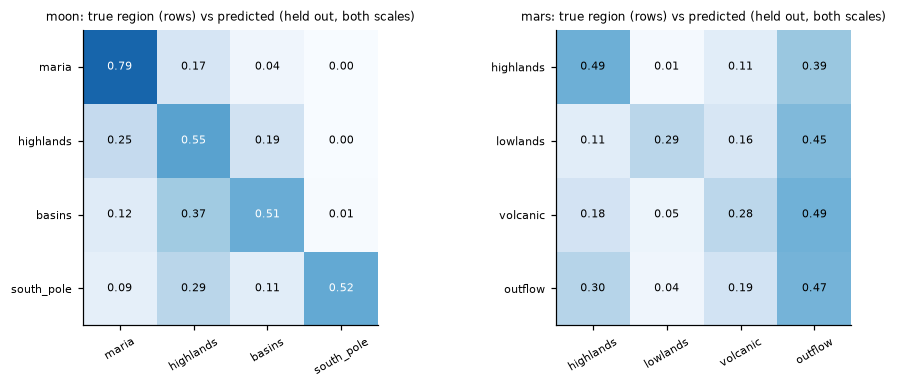

In [15]:
def to_logit_arr(score):
    return np.log(np.clip(score, 0.02, 0.98) / (1 - np.clip(score, 0.02, 0.98)))


XS = np.stack([to_logit_arr(oof[s][CHOSEN[s][0]]) for s in SCALES], axis=-1)       # (|Q|, 4, n_scales)
valid = ~np.isnan(XS).any(-1)
Y = (q_regs == q_region[:, None]).astype(int)


def fit_combo(mask):
    rows = valid & mask[:, None]
    return fit(np.c_[XS[rows], np.ones(rows.sum())], Y[rows], balanced(Y[rows]), np.zeros((len(SCALES) + 1,) * 2))


combo_cv = {n: [] for n in (*SCALES, "blend")}
blend_oof = np.full(XS.shape[:2], np.nan)
for f in range(CFG["folds"]):
    te = q_fold == f
    th = fit_combo(~te)
    blend_oof[te] = (XS[te] @ th[:-1]) + th[-1]
    combo_cv["blend"].append(region_accuracy(np.where(valid, blend_oof, np.nan), te)[0])
    for k, s in enumerate(SCALES):
        combo_cv[s].append(region_accuracy(np.where(valid, XS[..., k], np.nan), te)[0])
TH_COMBO = fit_combo(np.ones(len(Q), bool))
print("held-out region accuracy (chance 0.25):  " + "   ".join(f"{n} {np.mean(v):.3f} ± {np.std(v, ddof=1) / np.sqrt(len(v)):.3f}" for n, v in combo_cv.items()))
print("learned weights:", {s: round(float(TH_COMBO[k]), 2) for k, s in enumerate(SCALES)}, "bias", round(float(TH_COMBO[-1]), 2))
# The learned mix leans almost entirely on 32 km, which would make clicks a few km apart score nearly the same.
# So the 4 km scale gets a minimum share; the overall strength and the bias are refitted on the fixed mix.
w_l = np.maximum(TH_COMBO[:-1], 0.0)
k_site = SCALES.index("site")
if len(SCALES) > 1 and w_l.sum() > 0 and w_l[k_site] / w_l.sum() < CFG["site_share_min"]:
    mix = np.full(len(SCALES), (1 - CFG["site_share_min"]) / (len(SCALES) - 1)); mix[k_site] = CFG["site_share_min"]
    th1 = fit(np.c_[XS[valid] @ mix, np.ones(valid.sum())], Y[valid], balanced(Y[valid]), np.zeros((2, 2)))
    acc_mix = region_accuracy(np.where(valid, XS @ mix, np.nan), np.ones(len(Q), bool))[0]
    acc_learned = region_accuracy(np.where(valid, XS @ w_l, np.nan), np.ones(len(Q), bool))[0]
    TH_COMBO = np.r_[th1[0] * mix, th1[1]]
    print(f"4 km share raised from {w_l[k_site] / w_l.sum():.2f} to {CFG['site_share_min']:.2f}: region accuracy {acc_learned:.3f} -> {acc_mix:.3f}")
print("weights used:", {s: round(float(TH_COMBO[k]), 2) for k, s in enumerate(SCALES)}, "bias", round(float(TH_COMBO[-1]), 2))

pred_blend = q_regs[np.arange(len(Q)), np.nanargmax(np.where(np.isnan(blend_oof), -1e9, blend_oof), axis=1)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, w in zip(axes, WORLDS):
    ids = world_regions[w]
    M = np.array([[np.mean(pred_blend[q_region == a] == b) for b in ids] for a in ids])
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    names = [REGION_KEYS[r].split(":")[1] for r in ids]
    ax.set_xticks(range(len(ids)), names, rotation=30, fontsize=7); ax.set_yticks(range(len(ids)), names, fontsize=7)
    for (a, b), v in np.ndenumerate(M):
        ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.5 else "black")
    ax.set_title(f"{w}: true region (rows) vs predicted (held out, both scales)", fontsize=8)
plt.tight_layout(); plt.show()

site: final joint M1, smoothness 1, 48000 triplets, 20 bootstrap refits (2s)


regional: final region M2, smoothness 0.1, 24000 triplets, 20 bootstrap refits (3s)


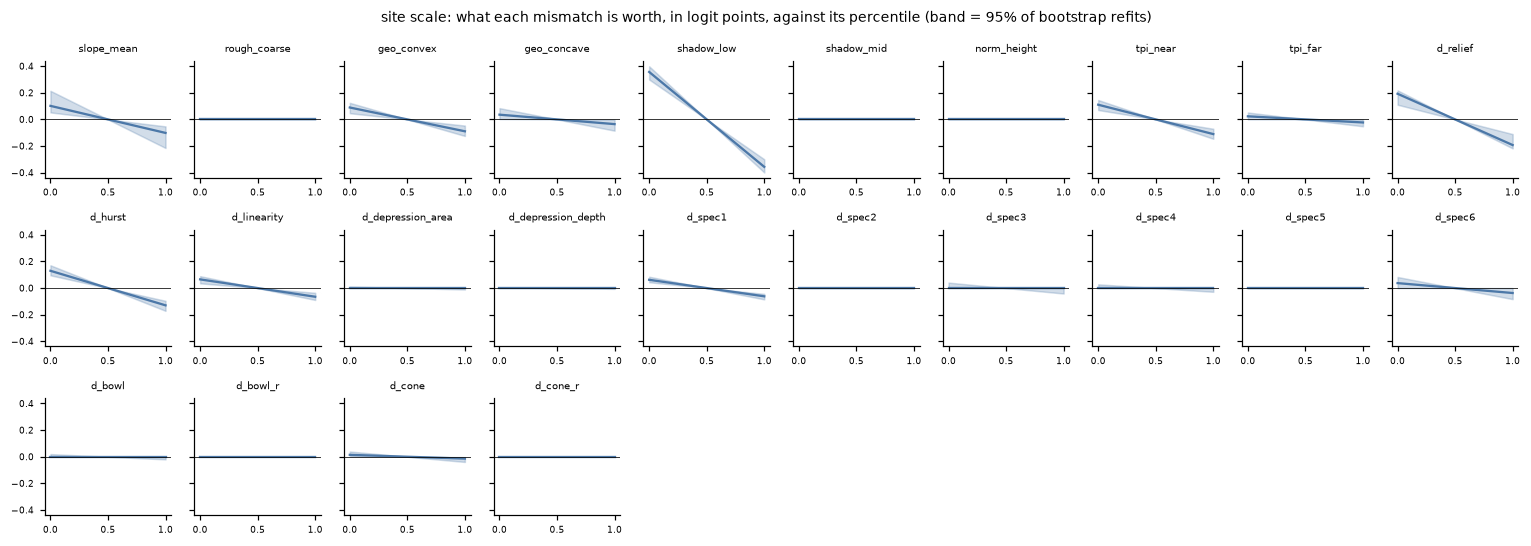

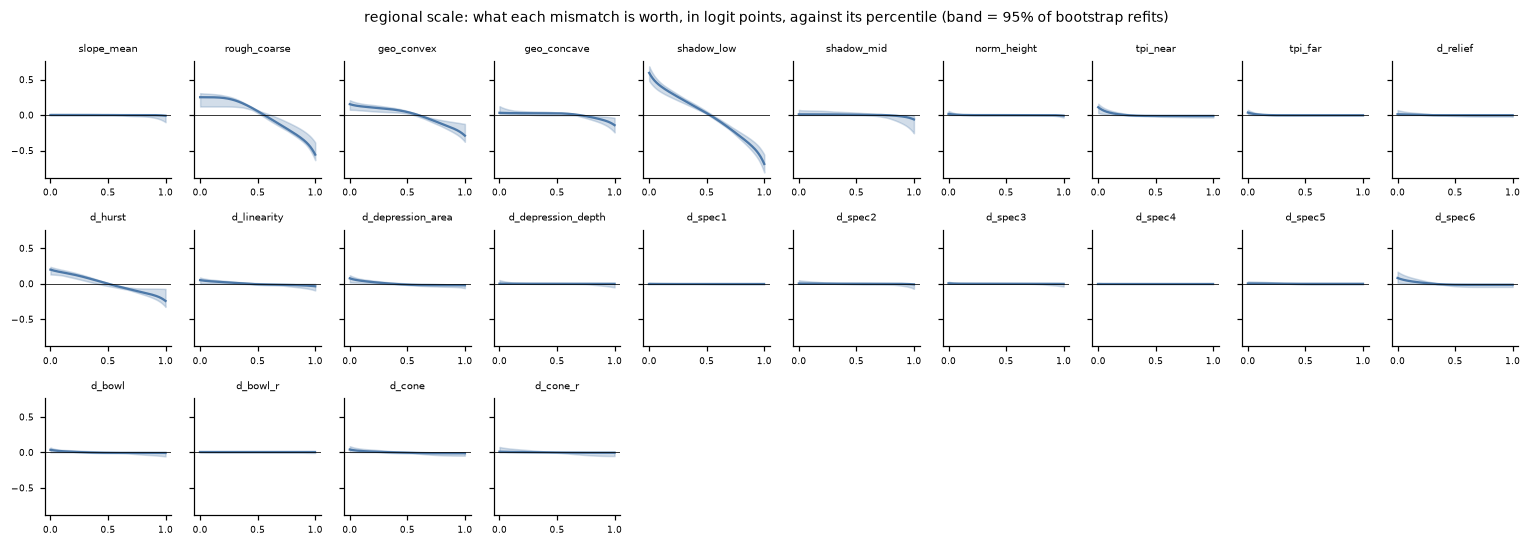

In [16]:
FINAL, FINAL_NOX, ENS = {}, {}, {}
rng_f = np.random.default_rng(SEED + 40)
t0 = time.time()
for s in SCALES:
    name, label, kind = CHOSEN[s]
    T = TR[(s, label)]
    lam = float(np.median(lam_pick[s][name]))
    allm = np.ones(len(T["is_cross"]), bool)
    FINAL[s] = train(s, label, kind, lam, allm)
    FINAL_NOX[s] = train(s, label, kind, lam, allm, use_cross=False)
    assert np.abs(FINAL[s][0]).max() > 0, f"the {s} pair model learned nothing: check the training rows"
    groups_u, gidx = np.unique(T["anchor_group"], return_inverse=True)
    curves_b, bias_b = [], []
    for _ in range(CFG["n_boot"]):
        mult = np.bincount(rng_f.integers(0, len(groups_u), len(groups_u)), minlength=len(groups_u))[gidx]
        c_, b_ = train(s, label, kind, lam, mult > 0, mult=mult)
        curves_b.append(c_); bias_b.append(b_)
    ENS[s] = (np.array(curves_b), np.array(bias_b))
    print(f"{s}: final {name}, smoothness {lam:g}, {len(allm)} triplets, {CFG['n_boot']} bootstrap refits ({time.time() - t0:.0f}s)")

for s in SCALES:
    fig, axes = plt.subplots(3, 10, figsize=(14, 5.0), sharey=True)
    for k, ax in enumerate(axes.flat):
        if k >= rt.N_IN:
            ax.axis("off"); continue
        lo, hi = np.percentile(ENS[s][0][:, k], [2.5, 97.5], axis=0)
        ax.fill_between(rt.GRID, lo, hi, color="#4c78a8", alpha=0.25)
        ax.plot(rt.GRID, FINAL[s][0][k], color="#4c78a8")
        ax.axhline(0, c="k", lw=0.5); ax.set_title(rt.INPUT_NAMES[k], fontsize=6.5); ax.tick_params(labelsize=6)
    fig.suptitle(f"{s} scale: what each mismatch is worth, in logit points, against its percentile (band = 95% of bootstrap refits)", fontsize=9)
    plt.tight_layout(); plt.show()

In [17]:
own_col = np.array([list(q_regs[i]).index(q_region[i]) for i in range(len(Q))])


def final_calibration(s, model_):
    A = aggregates(s, eval_logits(s, model_))
    own = A[np.arange(len(Q)), own_col]
    return A, [np.sort(own[(q_region == r) & ~np.isnan(own)]) for r in range(len(REGION_KEYS))]


def build_mz(models):
    w = np.maximum(TH_COMBO[:-1], 0.0)
    if w.sum() <= 0:
        w = np.r_[1.0, np.zeros(len(SCALES) - 1)]
    mz = dict(
        version=np.array(MODEL_VERSION), scales=np.array(SCALES),
        lib_world=lib["world"], lib_region=lib_region, lib_tag=lib_tag, lib_name=lib["name"],
        lib_lat=lib["lat"].astype(float), lib_lon=lib["lon"].astype(float), lib_href=lib["href"],
        region_keys=np.array(REGION_KEYS), region_title=np.array(REGION_TITLE),
        combo_bias=float(TH_COMBO[-1]), top_k=CFG["top_k"], shortlist=CFG["shortlist"],
        gate_names=np.array(rt.GATE_NAMES), gate_table=np.tile(rt.GRID, (len(rt.GATE_NAMES), 1)),
        gate_curve_vals=np.zeros((len(rt.GATE_NAMES), len(rt.GRID))), gate_bias=0.0,
        discount_floor=CFG["discount_floor"], precip_grid=PRECIP, aridity_grid=ARIDITY, weight_lambda=float(LAM_W))
    r_o = np.random.default_rng(SEED + 50)
    for k, s in enumerate(SCALES):
        P = SC[s]
        es = P["earth_sk"][rand]
        es = es[r_o.choice(len(es), size=min(len(es), 3000), replace=False)]
        nn = ((es[:, None] - es[None]) ** 2).sum(-1)
        np.fill_diagonal(nn, np.inf)
        _, calib = final_calibration(s, models[s])
        mz.update({f"{s}__{a}": b for a, b in dict(
            scaler_scale=P["scale"], pca_mean=P["pca_mean"], pca_components=P["pca_comp"], pct_table=P["pct_table"],
            curve_vals=models[s][0], bias=models[s][1], ens_curve_vals=ENS[s][0], ens_bias=ENS[s][1],
            lib_tokens=P["lib_tok"].astype(np.float16), lib_block=P["lib_blk"], lib_sketch=P["lib_sk"].astype(np.float32),
            earth_sketch=es.astype(np.float32), ood_threshold=float(np.percentile(np.sqrt(nn.min(1)), 99)),
            combo_weight=float(w[k]), lib_logw=LOGW.get(s, np.zeros(N_LIB)).astype(np.float32), block_mask=P["block_mask"]).items()})
        mz.update({f"{s}__calib__{r}": (c if len(c) else np.array([0.0])) for r, c in enumerate(calib)})
    return mz


MZ = build_mz(FINAL)
model = rt.Model(MZ)
model_nox = rt.Model(build_mz(FINAL_NOX))


def earth_emb(i):
    return {s: (SC[s]["earth_tok"][i], SC[s]["earth_blk"][i], SC[s]["earth_sk"][i]) for s in SCALES}


def lib_emb(i):
    return {s: (SC[s]["lib_tok"][i], SC[s]["lib_blk"][i], SC[s]["lib_sk"][i]) for s in SCALES}


print("blend weights in the model:", {s: round(model.S[s]["weight"], 2) for s in SCALES},
      "| calibration blocks per region:", {REGION_KEYS[r]: len(model.calib["site"][r]) for r in range(len(REGION_KEYS))})

blend weights in the model: {'site': 0.19, 'regional': 0.28} | calibration blocks per region: {'moon:maria': 150, 'moon:highlands': 150, 'moon:basins': 150, 'moon:south_pole': 150, 'mars:highlands': 150, 'mars:lowlands': 150, 'mars:volcanic': 150, 'mars:outflow': 150}


In [18]:
# ---- v2.0 library weighting: how common is each library block's terrain on Earth?
t0 = time.time()
r_split = np.random.default_rng(SEED + 80)
rand_idx = np.flatnonzero(earth["set"] == "random"); r_split.shuffle(rand_idx)
REF, HOLD = rand_idx[: len(rand_idx) // 2], rand_idx[len(rand_idx) // 2:]        # weights from REF, evaluation on HOLD
com_e = np.random.default_rng(SEED + 81).choice(REF, size=min(CFG["commonness_n"], len(REF)), replace=False)
LAM_W, LOGW, COMMON = 0.0, {}, {}
for s in SCALES:
    A0 = final_calibration(s, FINAL[s])[0]
    own0 = A0[np.arange(len(Q)), own_col]
    thr = np.array([np.nanmedian(own0[q_region == r]) if (q_region == r).any() else np.inf for r in range(len(REGION_KEYS))])
    lg_e = np.empty((len(com_e), N_LIB))
    for a_, e in enumerate(com_e):
        raw_ = rt.pair_inputs_many(SC[s]["earth_tok"][e], SC[s]["lib_tok"], SC[s]["earth_blk"][e], SC[s]["lib_blk"])[0]
        lg_e[a_] = FINAL[s][1] + rt.curves_at(FINAL[s][0], rt.to_z(SC[s]["pct_table"], raw_)).sum(1)
    COMMON[s] = (lg_e > thr[lib_region][None, :]).mean(0)       # share of Earth land that matches this block as well as a typical own-region match
    LOGW[s] = np.log(np.clip(1.0 - COMMON[s], 0.02, 1.0))
    print(f"{s}: commonness from {len(com_e)} Earth blocks ({time.time() - t0:.0f}s); median by region:",
          {REGION_KEYS[r].split(":")[1][:9]: round(float(np.median(COMMON[s][members[r]])), 2) for r in range(len(REGION_KEYS))})


def combined_region_accuracy():
    A_ = {s: final_calibration(s, FINAL[s])[0] for s in SCALES}
    S_ = np.stack([to_logit_arr(calibrated_scores(A_[s], np.ones(len(Q), bool), np.ones(len(Q), bool))) for s in SCALES], -1)
    return region_accuracy(np.where(np.isnan(S_).any(-1), np.nan, S_ @ np.maximum(TH_COMBO[:-1], 0)), np.ones(len(Q), bool))[0]


def score_earth(mz):
    tmp_ = CACHE / f"model_tmp_{PROFILE}.npz"
    np.savez(tmp_, **mz)
    with ProcessPoolExecutor(CFG["score_workers"]) as ex:
        out_ = list(ex.map(rt.region_logits_task, [(str(tmp_), earth_emb(i)) for i in range(len(earth["set"]))], chunksize=16))
    tmp_.unlink()
    return np.stack([o[0] for o in out_]), np.stack([o[1] for o in out_])


an_t = np.flatnonzero((earth["set"] == "analog") & (earth["kind"] == "terrain"))
neg_t = np.flatnonzero(earth["set"] == "negative")
rows_w, RUNS = [], {}
for lam in CFG["weight_lambda_grid"]:
    LAM_W = float(lam)
    mz_ = build_mz(FINAL)
    EL_, ELS_ = score_earth(mz_)
    sim_ = np.nan_to_num(100 * expit(EL_), nan=-1).max(1)
    hold_ = sim_[HOLD]
    rows_w.append(dict(weight=lam, region_accuracy=combined_region_accuracy(),
                       analog_similarity_rank=float(np.median([(hold_ > v).mean() for v in sim_[an_t]])),
                       negatives_top25=int(sum((hold_ > v).mean() < 0.25 for v in sim_[neg_t]))))
    RUNS[lam] = (EL_, ELS_)
    print(f"  weight {lam}: {rows_w[-1]} ({time.time() - t0:.0f}s)")
WTAB = pd.DataFrame(rows_w)
acc0 = float(WTAB.loc[WTAB.weight == 0, "region_accuracy"].iloc[0])
okw = WTAB[WTAB.region_accuracy >= acc0 - 0.02]
LAM_W = float(okw.sort_values(["analog_similarity_rank", "weight"]).iloc[0].weight)
print(WTAB.round(3).to_string(index=False))
print(f"chosen weight {LAM_W} (best analog rank while region accuracy stays within 0.02 of no weighting)")
MZ = build_mz(FINAL)
model = rt.Model(MZ)
model_nox = rt.Model(build_mz(FINAL_NOX))
EL, EL_SCALE = RUNS[LAM_W]


site: commonness from 200 Earth blocks (173s); median by region: {'maria': 0.0, 'highlands': 0.0, 'basins': 0.0, 'south_pol': 0.0, 'lowlands': 0.0, 'volcanic': 0.01, 'outflow': 0.01}


regional: commonness from 200 Earth blocks (349s); median by region: {'maria': 0.01, 'highlands': 0.0, 'basins': 0.0, 'south_pol': 0.0, 'lowlands': 0.01, 'volcanic': 0.01, 'outflow': 0.01}


  weight 0.0: {'weight': 0.0, 'region_accuracy': 0.45416666666666666, 'analog_similarity_rank': 0.6828, 'negatives_top25': 2} (514s)


  weight 0.5: {'weight': 0.5, 'region_accuracy': 0.4783333333333333, 'analog_similarity_rank': 0.6648000000000001, 'negatives_top25': 2} (690s)


  weight 1.0: {'weight': 1.0, 'region_accuracy': 0.48083333333333333, 'analog_similarity_rank': 0.6048, 'negatives_top25': 2} (872s)


  weight 2.0: {'weight': 2.0, 'region_accuracy': 0.48916666666666664, 'analog_similarity_rank': 0.47319999999999995, 'negatives_top25': 1} (1045s)
 weight  region_accuracy  analog_similarity_rank  negatives_top25
    0.0            0.454                   0.683                2
    0.5            0.478                   0.665                2
    1.0            0.481                   0.605                2
    2.0            0.489                   0.473                1
chosen weight 2.0 (best analog rank while region accuracy stays within 0.02 of no weighting)


In [19]:
# 1. Runtime agreement on a sample of evaluation blocks
A_fin = {s: final_calibration(s, FINAL[s])[0] for s in SCALES}
S_fin = np.stack([to_logit_arr(calibrated_scores(A_fin[s], np.ones(len(Q), bool), np.ones(len(Q), bool))) for s in SCALES], -1)
nb_pred = q_regs[np.arange(len(Q)), np.nanargmax(np.where(np.isnan(S_fin).any(-1), -1e9, S_fin @ np.maximum(TH_COMBO[:-1], 0)), axis=1)]
r_c = np.random.default_rng(SEED + 60)
pick = r_c.choice(len(Q), size=min(60, len(Q)), replace=False)
agree = [rt.region_scores(model, lib_emb(Q[i]), lib["world"][Q[i]], exclude=lib_group == lib_group[Q[i]], n_best=1)[0]["region_id"] == nb_pred[i]
         for i in pick]
print(f"runtime agreement: {np.mean(agree):.2f} of {len(pick)} blocks get the same top region from rt.region_scores as from the notebook")

# 2. Planet check, per scale: 5-nearest-neighbour guess of the world from the sketch (leave one out)
for s in SCALES:
    Sk = np.concatenate([SC[s]["lib_sk"], SC[s]["earth_sk"][rand]])
    lab = np.r_[lib["world"], np.array(["earth"] * rand.sum())]
    sub = r_c.choice(len(Sk), size=min(len(Sk), 3000), replace=False)
    D = ((Sk[sub][:, None] - Sk[sub][None]) ** 2).sum(-1)
    np.fill_diagonal(D, np.inf)
    guess = np.array([pd.Series(r).mode()[0] for r in lab[sub][np.argsort(D, axis=1)[:, :5]]])
    print(f"planet check, {s}: world guessed from the sketch {np.mean(guess == lab[sub]):.2f} of the time (chance 0.33)")

runtime agreement: 1.00 of 60 blocks get the same top region from rt.region_scores as from the notebook


planet check, site: world guessed from the sketch 0.68 of the time (chance 0.33)


planet check, regional: world guessed from the sketch 0.69 of the time (chance 0.33)


In [20]:
# Cross-world transfer. With cross_weight = 0 nothing was trained on these, so every crater and volcano is a test block.
# Only fairly bare blocks count: GLO-30 sees canopy and roofs, which isn't the landform.
VOLC_TAGS = ("volcanic_edifice", "lava_flow")
earth_cover = np.nansum([earth[g] for g in ("tree", "crop", "built", "water")], axis=0)


def cross_world(model_):
    rows = []
    sel = (earth["split"] == "test") & np.isin(earth["set"], ["crater", "volcano"]) & (earth_cover <= CFG["cover_max"])
    for i in np.flatnonzero(sel):
        world = "moon" if earth["set"][i] == "crater" else "mars"
        regs = rt.region_scores(model_, earth_emb(i), world, n_best=10)
        best = sorted((b for reg in regs for b in reg["best"]), key=lambda b: -b["logit"])[:10]
        if world == "moon":
            rows.append(dict(set="crater", name=earth["name"][i], value=np.mean([b["tag"] in CRATER_TAGS for b in best]), top=best[0]["tag"]))
        else:
            rows.append(dict(set="volcano", name=earth["name"][i], value=np.mean([b["tag"] in VOLC_TAGS for b in best]),
                             region=float(regs[0]["region"] == "mars:volcanic"), top=regs[0]["region"]))
    return pd.DataFrame(rows)


base_c = np.mean(np.isin(lib_tag[world_idx["moon"]], CRATER_TAGS))
base_v = np.mean(np.isin(lib_tag[world_idx["mars"]], VOLC_TAGS))
runs = [("shipped model", cross_world(model))] + ([("without cross-world triplets", cross_world(model_nox))] if CFG["cross_weight"] > 0 else [])
for name, d in runs:
    c, v = d[d.set == "crater"], d[d.set == "volcano"]
    print(f"{name:30s} Earth craters: {c.value.mean():.2f} of the 10 best Moon matches are crater-tagged (base rate {base_c:.2f}, n={len(c)})   "
          f"Earth volcanoes: {v.value.mean():.2f} of the 10 best Mars matches are volcano or lava-flow tagged (base rate {base_v:.2f}), "
          f"top region volcanic {v.region.mean():.2f} (chance 0.25, n={len(v)})")
xw = runs[0][1]
xw.groupby("set").head(8)

shipped model                  Earth craters: 0.14 of the 10 best Moon matches are crater-tagged (base rate 0.19, n=31)   Earth volcanoes: 0.05 of the 10 best Mars matches are volcano or lava-flow tagged (base rate 0.05), top region volcanic 0.23 (chance 0.25, n=119)


,set,name,value,top,region
0,crater,Aorounga rim,0.3,background,NaN
1,crater,Aorounga rim,0.1,wrinkle_ridge,NaN
2,crater,Aorounga rim,0.3,crater_chain,NaN
3,crater,Araguainha rim,0.4,graben,NaN
4,crater,Barringer (= Meteor),0.1,background,NaN
5,crater,Eagle Butte rim,0.0,wrinkle_ridge,NaN
6,crater,Eagle Butte rim,0.0,wrinkle_ridge,NaN
7,crater,Eagle Butte rim,0.0,wrinkle_ridge,NaN
31,volcano,Andahua-Orcopampa,0.0,mars:outflow,0.0
32,volcano,Jordan Craters,0.0,mars:outflow,0.0


region logits for 3550 Earth blocks in 0s
landscape = similarity x (floor + (1 - floor) x Earth percentile). held-out terrain analog sites, rank among held-out random land:
 floor  best_region_rank  own_region_rank  negatives_top25  earth_share_of_score
   0.2             0.442            0.525                1                 0.482
   0.3             0.447            0.525                1                 0.426
   0.4             0.450            0.525                1                 0.371
chosen floor 0.2 (best analog rank while the Earth part stays under half of the score)
aridity known for 93% of Earth blocks; analog sites median AI 0.150, random land 0.669
sparse vegetation sign -1: conditions held-out median rank 28.3%
sparse vegetation sign +1: conditions held-out median rank 33.6%
kept sign -1.0
held-out terrain analog sites, rank among held-out random land (0% = top, 50% = chance):
  similarity only  median  47.9%   in the top 10%: 0.18   in the top 25%: 0.29   n=56
  landsca

terrain sites in their own region: median rank 27.0%, own region is the site's best region for 15% (chance about 1/8). by region:
                 n  own_rank  best_rank
region                                 
mars:highlands  12     0.103      0.253
mars:lowlands    5     0.498      0.177
mars:outflow     1     0.615      0.698
mars:volcanic    7     0.196      0.094
moon:highlands   1     0.017      0.181


v2.1 discount family: 12 settings meet the rules, best analog rank 0.209
v2.1 overall = landscape x (surface/100)^beta, landscape = similarity x (floor + (1 - floor) x percentile^gamma). held-out:
271 settings, 1 meet the rules; the 15 best by analog rank, and v2.0 first:
 floor  gamma beta    w  power  analog_rank  negatives_top25  analog_median  random_median  random_p90  spread
   0.2    1.0 sqrt 0.50    1.0        0.220                0         55.721         36.664      68.231  19.057
   0.2    1.0  geo 0.35    1.0        0.217                0         51.955         36.637      62.456  15.318
chosen floor 0.2, gamma 1.0, surface weight 0.35, power 1.0: analog median 52.0, random median 36.6, rank 0.217 (v2.0: analog median overall 55.7, random land median 36.7)
surface max 71.5; overall on random land, median / 90th / 99th: {'moon': [26.0, 51.0, 72.0], 'mars': [35.0, 62.0, 75.0]}


terrain head, verified terrain sites among random land (held-out areas, 0% = top):
  l2  median_rank  top10  top25
 1.0         5.12  0.643  0.804
 3.0         5.26  0.661  0.804
10.0         5.52  0.661  0.804
30.0         5.66  0.679  0.821 
chosen l2 1.0


  without the volcano and crater positives: median 10.6%


surface head: median 12.8%  top 10% 0.25  top 25% 0.73
overall = terrain^(1-w) x surface^w (held-out areas):
  w  median_rank  top10  top25  negatives_top25  sites_median  land_median  land_p90
0.2         2.88  0.732  0.839                0        68.527       25.530    53.960
0.3         3.26  0.750  0.875                0        66.404       23.647    53.711
0.4         3.54  0.732  0.875                0        65.695       21.974    54.078 
chosen w 0.2
  terrain (best region)  sites: rank median   4.5%, top 10% 0.64, top 25% 0.77 | score: sites median 74 (10th-90th 29-94), land median 32, 90th 64, 99th 84
  surface                sites: rank median  13.1%, top 10% 0.25, top 25% 0.68 | score: sites median 73 (10th-90th 36-86), land median 21, 90th 84, 99th 87
  overall                sites: rank median   2.9%, top 10% 0.73, top 25% 0.84 | score: sites median 69 (10th-90th 32-89), land median 26, 90th 54, 99th 77
  best block within 4.0 km of each site: median overall 75 (the liste

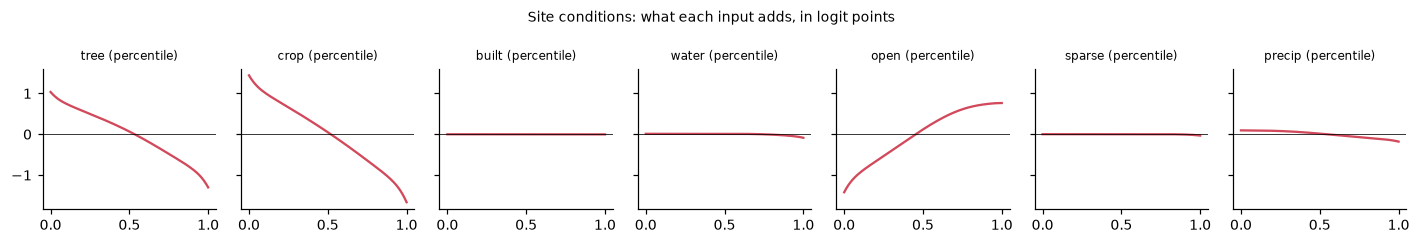

In [21]:
t0 = time.time()
gsel = np.flatnonzero(np.isin(earth["set"], ["analog", "random"]))
feat_idx = np.flatnonzero(earth["set"] == "featured")
# Earth blocks were scored in the weighting cell, with the chosen weight (EL, EL_SCALE)
print(f"region logits for {len(EL)} Earth blocks in {time.time() - t0:.0f}s")
S_ = earth["set"]


# ---- landscape: similarity x Earth factor (option C). the factor only discounts; it never raises a weak match
def earth_pct(ref_idx):
    # percentile of every block's region logit among the reference random-land blocks, per region
    return np.stack([np.searchsorted(np.sort(EL[ref_idx, k][~np.isnan(EL[ref_idx, k])]), EL[:, k], side="right")
                     / max((~np.isnan(EL[ref_idx, k])).sum(), 1) for k in range(EL.shape[1])], 1)


def landscape(Pct, floor):
    return np.nan_to_num(100 * expit(EL) * (floor + (1 - floor) * Pct), nan=-1.0)


r_split = np.random.default_rng(SEED + 80)
rand_idx = np.flatnonzero(S_ == "random"); r_split.shuffle(rand_idx)
REF, HOLD = rand_idx[: len(rand_idx) // 2], rand_idx[len(rand_idx) // 2:]
P_half = earth_pct(REF)
an_eval = np.flatnonzero((S_ == "analog") & (earth["kind"] == "terrain"))
an_reg = an_eval[np.isin(earth["tag"][an_eval], REGION_KEYS)]          # only sites that really are a region's terrain
an_exact = an_eval[earth["coordq"][an_eval] != "area"]
neg_idx = np.flatnonzero(S_ == "negative")


def site_score(Lnd, i):
    # area-quality sites: median over the centre block and its 8 ring blocks
    if earth["coordq"][i] != "area":
        return Lnd[i]
    ring = np.flatnonzero((S_ == "analog_area") & np.char.startswith(earth["name"].astype(str), earth["name"][i] + "|"))
    return np.median(np.r_[[Lnd[i]], Lnd[ring]], axis=0)


def ranks(vals, ref_vals):
    return np.array([(ref_vals > v).mean() for v in vals])


rows_f = []
for floor in CFG["earth_floor_grid"]:
    Lnd = landscape(P_half, floor)
    best_hold = Lnd[HOLD].max(1)
    best_an = np.array([site_score(Lnd, i).max() for i in an_eval])
    own = np.array([site_score(Lnd, i)[REGION_KEYS.index(earth["tag"][i])] for i in an_reg])
    own_ref = {k: Lnd[HOLD, k] for k in range(len(REGION_KEYS))}
    own_rank = np.array([(own_ref[REGION_KEYS.index(earth["tag"][i])] > v).mean() for i, v in zip(an_reg, own)])
    lg_s, lg_f = np.log(np.clip(100 * expit(EL[HOLD]), 1e-6, None)), np.log(floor + (1 - floor) * P_half[HOLD])
    tot = lg_s + lg_f
    share = float(np.nanmean([np.cov(lg_f[:, k], tot[:, k])[0, 1] / tot[:, k].var() for k in range(tot.shape[1])]))
    rows_f.append(dict(floor=floor, best_region_rank=np.median(ranks(best_an, best_hold)), own_region_rank=np.median(own_rank),
                       negatives_top25=int((ranks(Lnd[neg_idx].max(1), best_hold) < 0.25).sum()), earth_share_of_score=share))
FLOORS = pd.DataFrame(rows_f)
ok_ = FLOORS[FLOORS.earth_share_of_score < 0.5]
EARTH_FLOOR = float(ok_.sort_values(["best_region_rank", "floor"], ascending=[True, True]).iloc[0].floor)
print("landscape = similarity x (floor + (1 - floor) x Earth percentile). held-out terrain analog sites, rank among held-out random land:")
print(FLOORS.round(3).to_string(index=False))
print(f"chosen floor {EARTH_FLOOR} (best analog rank while the Earth part stays under half of the score)")
P_all = earth_pct(rand_idx)
LAND = landscape(P_all, EARTH_FLOOR)                 # every Earth block, per region (reference = all random land)
LAND_best = LAND.max(1)

# ---- conditions: tree, crop, built, water, open (bare + snow and ice), sparse vegetation (shrub, grass, moss), rainfall
antarctic = (earth["lat"] < -60) & np.isnan(earth["bare"])
earth["aridity"] = np.array([0.0 if antarctic[i] else rt.aridity_at(_PrecipOnly, earth["lat"][i], earth["lon"][i]) for i in range(len(earth["set"]))])
print(f"aridity known for {np.isfinite(earth['aridity']).mean():.0%} of Earth blocks; analog sites median AI "
      f"{np.nanmedian(earth['aridity'][earth['set'] == 'analog']):.3f}, random land {np.nanmedian(earth['aridity'][earth['set'] == 'random']):.3f}")
env_rows = [dict(tree=0.0, crop=0.0, built=0.0, water=0.0, snow=1.0, bare=0.0, sparse=0.0, precip=earth["precip"][i], aridity=0.0) if antarctic[i]
            else {g: earth[g][i] for g in rt.ENV_NAMES} for i in range(len(earth["set"]))]
ENV = np.stack([rt.gate_inputs(e) for e in env_rows])
gate_table = np.stack([np.quantile(ENV[rand, m][~np.isnan(ENV[rand, m])], rt.GRID) for m in range(ENV.shape[1])])
Zg = rt.to_z(gate_table, np.nan_to_num(ENV))
Zg[np.isnan(ENV)] = 0.5
# positives: terrain and habitat analog sites only (rock-sample sites aren't surface analogs)
gsel = np.flatnonzero((S_ == "random") | ((S_ == "analog") & np.isin(earth["kind"], ["terrain", "habitat"])))
yg, Zs, gg = (S_[gsel] == "analog").astype(int), Zg[gsel], earth_group[gsel]
built_raw = np.nan_to_num(earth["built"])
FIXED = -CFG["built_penalty"] * np.minimum(built_raw / CFG["built_full"], 1.0)
GLAM = (1.0, 1e-2)
gf = group_folds(gg, 5, SEED + 70)
k_sparse = rt.GATE_NAMES.index("sparse")


def rank_pct(pos, neg):
    return 100.0 * (len(neg) - np.searchsorted(np.sort(neg), pos, side="left")) / len(neg)


def gate_fit(Z, y, signs):
    return fit(design(Z, signs, "M2"), y, balanced(y), penalty(len(signs), "M2", *GLAM))


def gate_oof(signs):
    G = np.zeros(len(yg))
    for f in range(5):
        G[gf == f] = design(Zs[gf == f], signs, "M2") @ gate_fit(Zs[gf != f], yg[gf != f], signs)
    return G + FIXED[gsel]


def held_out_rank(v):
    return np.concatenate([rank_pct(v[(gf == f) & (yg == 1)], v[(gf == f) & (yg == 0)]) for f in range(5) if ((gf == f) & (yg == 1)).any()])


SIGN_TEST = {}
for sgn in (-1.0, +1.0):
    signs = tuple(sgn if k == k_sparse else s for k, s in enumerate((-1.0, -1.0, -1.0, -1.0, +1.0, 0.0, -1.0)))
    G_ = gate_oof(signs)
    SIGN_TEST[sgn] = (signs, G_, float(np.median(held_out_rank(G_))))
    print(f"sparse vegetation sign {sgn:+.0f}: conditions held-out median rank {SIGN_TEST[sgn][2]:.1f}%")
GATE_SIGNS, G_oof, _ = min(SIGN_TEST.values(), key=lambda t: t[2])
print("kept sign", GATE_SIGNS[k_sparse])

# ---- held-out evaluation: terrain sites, landscape (similarity x Earth factor), conditions, overall
pos_t = np.isin(gsel, an_eval) | (yg == 0)
T_land = LAND_best[gsel]
B_oof = T_land * expit(G_oof)
print("held-out terrain analog sites, rank among held-out random land (0% = top, 50% = chance):")
for name, v in (("similarity only", 100 * expit(np.nanmax(EL, 1))[gsel]), ("landscape", T_land), ("conditions only", G_oof), ("overall", B_oof)):
    keep_ = pos_t
    rr = np.concatenate([rank_pct(v[keep_ & (gf == f) & (yg == 1)], v[keep_ & (gf == f) & (yg == 0)]) for f in range(5) if (keep_ & (gf == f) & (yg == 1)).any()])
    print(f"  {name:16s} median {np.median(rr):5.1f}%   in the top 10%: {np.mean(rr <= 10):.2f}   in the top 25%: {np.mean(rr <= 25):.2f}   n={len(rr)}")

th_g = gate_fit(Zs, yg, GATE_SIGNS)
nc = BASIS.n_cols
g_curves = np.array([s * (GRID_I @ th_g[m * nc:(m + 1) * nc]) for m, s in enumerate(GATE_SIGNS)])
g_centres = g_curves.mean(1)
MZ.update(gate_table=gate_table, gate_curve_vals=g_curves - g_centres[:, None], gate_bias=float(th_g[-1] + g_centres.sum()),
          discount_floor=CFG["discount_floor"], built_penalty=CFG["built_penalty"], built_full=CFG["built_full"], earth_floor=EARTH_FLOOR,
          **{f"earth_ref__{k}": np.sort(EL[rand_idx, k][~np.isnan(EL[rand_idx, k])]).astype(np.float32) for k in range(len(REGION_KEYS))})
model = rt.Model(MZ)
print(f"overall = landscape x conditions/100;  landscape = similarity x ({EARTH_FLOOR:.1f} + {1 - EARTH_FLOOR:.1f} x Earth percentile);  "
      f"built penalty {CFG['built_penalty']} logit points at {CFG['built_full']:.0%} built-up")

# ---- region tags: does each terrain site rank high in the region it's an analog for?
COND_ALL = 100 * expit(np.array([rt.conditions(model, e)[0] for e in env_rows]))
OVER = LAND * (COND_ALL / 100)[:, None]
rows_t = []
for i in an_reg:
    k = REGION_KEYS.index(earth["tag"][i])
    sc = site_score(OVER, i)
    rows_t.append(dict(site=earth["name"][i], region=earth["tag"][i], coords=earth["coordq"][i],
                       own_rank=(OVER[rand_idx, k] > sc[k]).mean(), best_rank=(OVER[rand_idx].max(1) > sc.max()).mean(),
                       best_region=REGION_KEYS[int(np.argmax(sc))], own_is_best=int(np.argmax(sc)) == k))
TAGS_T = pd.DataFrame(rows_t)
print(f"terrain sites in their own region: median rank {100 * TAGS_T.own_rank.median():.1f}%, own region is the site's best region for "
      f"{TAGS_T.own_is_best.mean():.0%} (chance about 1/8). by region:")
print(TAGS_T.groupby("region").agg(n=("site", "size"), own_rank=("own_rank", "median"), best_rank=("best_rank", "median")).round(3).to_string())

# ---- v1.3.1 display scale: surface out of its real maximum, overall = geometric mean, Earth percentile reference per world
SURFACE_MAX = float(np.nanmax(COND_ALL))               # the highest surface score any Earth block reaches (the curves' joint max is unreachable)
SURF100 = np.minimum(100.0, 100.0 * COND_ALL / SURFACE_MAX)
OVER = None   # set below, after the v2.1 search
w_cols = {w: [k for k, key in enumerate(REGION_KEYS) if key.startswith(w + ":")] for w in WORLDS}

# ---- v2.1: Earth factor shape (gamma) and how surface enters overall (beta), picked together on held-out sites.
# rules: the negative set passes, verified sites' median overall stays >= keep_analog_overall x v2.0's (no blanket drop),
# then the best analog rank; ties go to the larger beta (less surface inflation)
def land_g(Pct, floor, gamma, power=1.0):
    return np.nan_to_num(100 * expit(EL) ** power * (floor + (1 - floor) * Pct ** gamma), nan=-1.0)


def comb(L, S, beta, w=None):
    if w is not None:                                    # v2.1.1: weighted geometric mean
        return np.clip(L, 0, None) ** (1 - w) * np.clip(S, 0, None) ** w
    return np.sqrt(np.clip(L, 0, None) * S) if beta is None else np.clip(L, 0, None) * (S / 100.0) ** beta


def grade(floor, gamma, beta, power=1.0, w=None):
    Ov = comb(land_g(P_half, floor, gamma, power), SURF100[:, None], beta, w)
    best_hold = Ov[HOLD].max(1)
    best_an = np.array([site_score(Ov, i).max() for i in an_eval])
    return dict(floor=floor, gamma=gamma, beta=("geo" if w is not None else beta) if beta is not None or w is not None else "sqrt", w=w if w is not None else 0.5 if beta is None else None, power=power, analog_rank=float(np.median(ranks(best_an, best_hold))),
                negatives_top25=int((ranks(Ov[neg_idx].max(1), best_hold) < 0.25).sum()), analog_median=float(np.median(best_an)),
                random_median=float(np.median(best_hold)), random_p90=float(np.percentile(best_hold, 90)))


BASE = grade(EARTH_FLOOR, 1.0, None)                     # v2.0: chosen floor, gamma 1, sqrt
COMBO = pd.DataFrame([BASE] + [grade(f, g, b, k) for f in CFG["earth_floor_grid"] for g in CFG["earth_gamma_grid"]
                               for b in CFG["surface_beta_grid"] for k in CFG["terrain_power_grid"]]
                     + [grade(f, g, 0.0, k, w) for f in CFG["earth_floor_grid"] for g in CFG["earth_gamma_grid"]
                        for k in CFG["terrain_power_grid"] for w in CFG["surface_weight_grid"]])
COMBO["spread"] = COMBO.analog_median - COMBO.random_median        # how far verified sites stand above ordinary land
ok_disc = COMBO[(COMBO.beta != "sqrt") & (COMBO.beta != "geo") & (COMBO.negatives_top25 == 0)
                & (COMBO.analog_median >= CFG["keep_analog_overall"] * BASE["analog_median"]) & (COMBO.random_median <= BASE["random_median"])]
print(f"v2.1 discount family: {len(ok_disc)} settings meet the rules, best analog rank {ok_disc.analog_rank.min() if len(ok_disc) else float('nan'):.3f}")
# v2.1.1: only the weighted geometric mean, so overall always sits between terrain and surface
ok_c = COMBO[(COMBO.beta == "geo") & (COMBO.negatives_top25 == 0) & (COMBO.analog_median >= CFG["keep_analog_overall"] * BASE["analog_median"])
             & (COMBO.random_median <= BASE["random_median"])]
if len(ok_c):
    # best analog rank (to 1%), then the widest spread, then the least lift and the most surface discount
    pick_c = ok_c.assign(rank_r=ok_c.analog_rank.round(2)).sort_values(["rank_r", "spread", "power", "w"], ascending=[True, False, False, True]).iloc[0]
else:                                                    # nothing meets both: keep sites up first, then the least inflation
    pick_c = COMBO[COMBO.beta == "geo"].assign(gap=lambda d: (CFG["keep_analog_overall"] * BASE["analog_median"] - d.analog_median).clip(lower=0)) \
        .sort_values(["gap", "random_median"]).iloc[0]
EARTH_FLOOR, EARTH_GAMMA, TERRAIN_POWER, SURF_W = float(pick_c.floor), float(pick_c.gamma), float(pick_c.power), float(pick_c.w)
SURF_BETA = 0.5                                          # unused once surface_weight is set; kept so older readers still load
print("v2.1 overall = landscape x (surface/100)^beta, landscape = similarity x (floor + (1 - floor) x percentile^gamma). held-out:")
print(f"{len(COMBO)} settings, {len(ok_c)} meet the rules; the 15 best by analog rank, and v2.0 first:")
print(pd.concat([COMBO.iloc[:1], ok_c.sort_values("analog_rank").head(15) if len(ok_c) else COMBO.iloc[1:16]]).round(3).to_string(index=False))
print(f"chosen floor {EARTH_FLOOR}, gamma {EARTH_GAMMA}, surface weight {SURF_W}, power {TERRAIN_POWER}: analog median {pick_c.analog_median:.1f}, "
      f"random median {pick_c.random_median:.1f}, rank {pick_c.analog_rank:.3f} (v2.0: analog median overall {BASE['analog_median']:.1f}, "
      f"random land median {BASE['random_median']:.1f})")
LAND = land_g(P_all, EARTH_FLOOR, EARTH_GAMMA, TERRAIN_POWER)
LAND_best = LAND.max(1)
OVER = comb(LAND, SURF100[:, None], None, SURF_W)
MZ.update(earth_floor=EARTH_FLOOR, earth_gamma=EARTH_GAMMA, surface_beta=SURF_BETA, terrain_power=TERRAIN_POWER, surface_weight=SURF_W)
MZ.update(surface_max=SURFACE_MAX, **{f"overall_ref__{w}": np.sort(OVER[rand_idx][:, ks].max(1)).astype(np.float32) for w, ks in w_cols.items()})
model = rt.Model(MZ)
print(f"surface max {SURFACE_MAX:.1f}; overall on random land, median / 90th / 99th:", {w: np.percentile(OVER[rand_idx][:, ks].max(1), [50, 90, 99]).round(0).tolist() for w, ks in w_cols.items()})

# ==================================================================== v3.0: heads trained on verified sites vs random land
# the v2 terrain score asked "how typical would this block be inside a Moon/Mars region" and ranked verified sites no
# better than chance (the library is mostly plains, the sites are rugged). v3.0 learns what verified sites look like:
#   terrain head  = logistic regression on the terrain measurements (both scales)
#   surface head  = the same on land cover and rainfall, with the signs fixed where the physics is clear
#   region score  = terrain head + alpha x (how far above ordinary land the match to that region is)
# everything below is scored on whole areas the model never saw (6 degree cells held out together)
from scipy.special import ndtri
from scipy.stats import spearmanr
t0h = time.time()
NE = len(S_)
XT = np.stack([rt.head_terrain_x(earth_emb(i)) for i in range(NE)])
cover_known = earth["lat"] >= -60                           # no land cover south of 60 S: unknown
def env_of(i):
    e = {g: float(earth[g][i]) for g in rt.ENV_NAMES}
    if not cover_known[i]:
        e.update(dict(tree=0.0, crop=0.0, built=0.0, water=0.0, snow=np.nan, bare=np.nan, sparse=np.nan))   # as the readers do
    return e
XS = np.stack([rt.surface_x(env_of(i)) for i in range(NE)])
garea = np.array([f"{int(a // CFG['head_area_deg'])}:{int(b // CFG['head_area_deg'])}" for a, b in zip(earth["lat"], earth["lon"])])
names_e = earth["name"].astype(str)
ring_of = {}
for i in np.flatnonzero(np.isin(S_, ["analog_area", "expert_area"])):
    ring_of.setdefault((S_[i].split("_")[0], names_e[i].split("|")[0]), []).append(i)
h_sites = an_eval                                            # verified terrain analog sites
h_feat = np.flatnonzero(np.isin(S_, ["volcano", "crater"]))  # verified geological features: weaker positives (terrain head only)
h_land = rand_idx


def head_fit(X, yy, sw, l2, signs=None, it=600):
    # ridge logistic regression by gradient steps; signs (+1 / -1 / 0) keeps a weight on its side of zero
    w, b, n = np.zeros(X.shape[1]), 0.0, sw.sum()
    for _ in range(it):
        pr = expit(X @ w + b)
        w -= 0.5 * (X.T @ (sw * (pr - yy)) / n + l2 * w / n)
        b -= 0.5 * np.sum(sw * (pr - yy)) / n
        if signs is not None:
            w = np.where(signs > 0, np.maximum(w, 0), np.where(signs < 0, np.minimum(w, 0), w))
    return w, b


def head_train_set(keep, with_feat):
    # rows, labels and weights: a site and its ring share one unit of weight; classes balanced
    idx, yy, sw = [], [], []
    for i in h_sites:
        if keep[i]:
            bag = [i] + ring_of.get(("analog", names_e[i]), [])
            idx += bag; yy += [1.0] * len(bag); sw += [1.0 / len(bag)] * len(bag)
    if with_feat:
        ex = [i for i in h_feat if keep[i]]
        idx += ex; yy += [1.0] * len(ex); sw += [CFG["head_feature_weight"]] * len(ex)
    nl = [i for i in h_land if keep[i]]
    idx += nl; yy += [0.0] * len(nl); sw += [1.0] * len(nl)
    idx, yy, sw = np.array(idx), np.array(yy), np.array(sw)
    sw = np.where(yy == 1, 0.5 / sw[yy == 1].sum(), 0.5 / sw[yy == 0].sum()) * sw * len(yy)
    return idx, yy, sw


def head_scaler(X, idx):
    mu, sd = np.nanmean(X[idx], 0), np.nanstd(X[idx], 0)
    mu, sd = np.nan_to_num(mu), np.where(np.nan_to_num(sd) < 1e-6, np.inf, sd)     # a constant input carries nothing
    return mu, sd


def head_z(X, mu, sd):
    return np.clip(np.nan_to_num((X - mu) / sd), -rt.HEAD_Z_CLIP, rt.HEAD_Z_CLIP)


def head_oof(X, l2, with_feat, signs=None, seeds=3):
    # logit of every Earth block from models that never saw its area
    out = np.zeros(NE)
    for sd_ in range(seeds):
        ug = np.unique(garea); np.random.default_rng(SEED + 300 + sd_).shuffle(ug)
        fold = {u: k % 5 for k, u in enumerate(ug)}; fd = np.array([fold[u] for u in garea])
        for k in range(5):
            idx, yy, sw = head_train_set(fd != k, with_feat)
            mu, sd = head_scaler(X, idx)
            w, b = head_fit(head_z(X[idx], mu, sd), yy, sw, l2, signs)
            out[fd == k] += (head_z(X[fd == k], mu, sd) @ w + b) / seeds
    return out


def head_final(X, l2, with_feat, signs=None):
    idx, yy, sw = head_train_set(np.ones(NE, bool), with_feat)
    mu, sd = head_scaler(X, idx)
    w, b = head_fit(head_z(X[idx], mu, sd), yy, sw, l2, signs)
    return w, b, mu, sd


def site_rank(v, pos=None):
    # rank of each verified site among random land, 0% = top
    pos = h_sites if pos is None else pos
    ref = np.sort(v[h_land])
    return 100.0 * (1.0 - np.searchsorted(ref, v[pos], side="left") / len(ref))


def platt(v, offset=None):
    # 1-d recalibration of held-out logits on sites vs land: a x v + c (+ offset), classes balanced
    offset = np.zeros(NE) if offset is None else offset
    idx = np.r_[h_sites, h_land]; yy = np.r_[np.ones(len(h_sites)), np.zeros(len(h_land))]
    sw = np.where(yy == 1, 0.5 / len(h_sites), 0.5 / len(h_land)) * len(yy)
    a, c = 1.0, 0.0
    for _ in range(3000):
        pr = expit(a * v[idx] + c + offset[idx])
        a -= 0.3 * np.sum(sw * (pr - yy) * v[idx]) / len(yy); c -= 0.3 * np.sum(sw * (pr - yy)) / len(yy)
    return float(a), float(c)


# terrain head: ridge strength on held-out areas
rows_h, T_try = [], {}
for l2 in CFG["head_l2_grid"]:
    T_try[l2] = head_oof(XT, l2, True)
    rr = site_rank(T_try[l2])
    rows_h.append(dict(l2=l2, median_rank=np.median(rr), top10=np.mean(rr <= 10), top25=np.mean(rr <= 25)))
HEAD_L2 = float(pd.DataFrame(rows_h).sort_values(["median_rank", "l2"], ascending=[True, False]).iloc[0].l2)
T_oof = T_try[HEAD_L2]
print("terrain head, verified terrain sites among random land (held-out areas, 0% = top):")
print(pd.DataFrame(rows_h).round(3).to_string(index=False), f"\nchosen l2 {HEAD_L2}")
rr0 = site_rank(head_oof(XT, HEAD_L2, False))
print(f"  without the volcano and crater positives: median {np.median(rr0):.1f}%")
# surface head: signs fixed where the physics is clear (trees, crops, buildings, water, snow and rain never help; bare ground never hurts)
S_SIGNS = np.array([-1.0, -1.0, -1.0, -1.0, -1.0, +1.0, 0.0, -1.0])
S_oof = head_oof(XS, 1.0, False, S_SIGNS)
rs_ = site_rank(S_oof)
print(f"surface head: median {np.median(rs_):.1f}%  top 10% {np.mean(rs_ <= 10):.2f}  top 25% {np.mean(rs_ <= 25):.2f}")

# region match: how far above ordinary land each block's match to each region is
Z_all = np.nan_to_num(ndtri(np.clip(P_all, 0.005, 0.995)))
ALPHA = float(CFG["head_alpha"])
a_t, c_t = platt(T_oof, ALPHA * Z_all.max(1))
a_s, c_s = platt(S_oof)
FIXED_ALL = -CFG["built_penalty"] * np.minimum(np.nan_to_num(earth["built"]) / CFG["built_full"], 1.0)
TERR = 100.0 * expit((a_t * T_oof + c_t)[:, None] + ALPHA * Z_all)         # per region, held-out
SURF100 = 100.0 * expit(a_s * S_oof + c_s + FIXED_ALL)
rows_o = []
for w_ in CFG["head_overall_grid"]:
    Ov = TERR ** (1 - w_) * SURF100[:, None] ** w_
    rr = site_rank(Ov.max(1))
    rows_o.append(dict(w=w_, median_rank=np.median(rr), top10=np.mean(rr <= 10), top25=np.mean(rr <= 25),
                       negatives_top25=int(((Ov[h_land].max(1)[None, :] > Ov[neg_idx].max(1)[:, None]).mean(1) < 0.25).sum()),
                       sites_median=np.median(Ov[h_sites].max(1)), land_median=np.median(Ov[h_land].max(1)), land_p90=np.percentile(Ov[h_land].max(1), 90)))
OVT = pd.DataFrame(rows_o)
ok_o = OVT[OVT.negatives_top25 == 0]
SURF_W = float((ok_o if len(ok_o) else OVT).assign(r=lambda d: d.median_rank.round(1)).sort_values(["r", "w"], ascending=[True, False]).iloc[0].w)
print("overall = terrain^(1-w) x surface^w (held-out areas):")
print(OVT.round(3).to_string(index=False), f"\nchosen w {SURF_W}")
LAND = TERR
LAND_best = LAND.max(1)
COND_ALL = SURF100.copy()
SURFACE_MAX = 100.0
OVER = TERR ** (1 - SURF_W) * SURF100[:, None] ** SURF_W
for label, v in (("terrain (best region)", LAND_best), ("surface", SURF100), ("overall", OVER.max(1))):
    rr = site_rank(v)
    print(f"  {label:22s} sites: rank median {np.median(rr):5.1f}%, top 10% {np.mean(rr <= 10):.2f}, top 25% {np.mean(rr <= 25):.2f} | score: sites median {np.median(v[h_sites]):.0f} "
          f"(10th-90th {np.percentile(v[h_sites], 10):.0f}-{np.percentile(v[h_sites], 90):.0f}), land median {np.median(v[h_land]):.0f}, 90th {np.percentile(v[h_land], 90):.0f}, 99th {np.percentile(v[h_land], 99):.0f}")
# best block of each site's ring (the listed point is often a few km off)
bag_best = np.array([max(OVER[[i] + ring_of.get(("analog", names_e[i]), [])].max(1)) for i in h_sites])
print(f"  best block within {CFG['area_ring_km']} km of each site: median overall {np.median(bag_best):.0f} (the listed point: {np.median(OVER[h_sites].max(1)):.0f})")

# final fits on everything, for the model file
w_t, b_t, mu_t, sd_t = head_final(XT, HEAD_L2, True)
w_s, b_s, mu_s, sd_s = head_final(XS, 1.0, False, S_SIGNS)
MZ.update(head_t_w=w_t, head_t_mu=mu_t, head_t_sd=sd_t, head_t_b=b_t, head_s_w=w_s, head_s_mu=mu_s, head_s_sd=sd_s, head_s_b=b_s,
          head_cal_t=np.array([a_t, c_t]), head_cal_s=np.array([a_s, c_s]), head_alpha=ALPHA,
          surface_weight=SURF_W, surface_max=SURFACE_MAX, terrain_power=1.0, earth_gamma=1.0,
          **{f"overall_ref__{w}": np.sort(OVER[rand_idx][:, ks].max(1)).astype(np.float32) for w, ks in w_cols.items()})
model = rt.Model(MZ)
grp_w = pd.Series(a_t * w_t).groupby(list(rt.HEAD_T_GROUPS)).apply(lambda s: float(np.abs(s).sum())).sort_values(ascending=False)
print("terrain head, measurements by total weight:", {k: round(v, 2) for k, v in grp_w.head(10).items()})
print("surface head weights:", {n: round(float(a_s * v), 2) for n, v in zip(rt.SURFACE_INPUTS, w_s)})

# the check sites and the frozen expert list (never used as labels; scored from models that didn't see their area)
from scipy.stats import spearmanr
chk = np.flatnonzero(S_ == "featured")
CHK = pd.DataFrame(dict(site=names_e[chk], expected=earth["expected"][chk], terrain=LAND_best[chk].round(0), surface=SURF100[chk].round(0), overall=OVER[chk].max(1).round(0)))
print(f"check sites: Spearman with the expected order {spearmanr(CHK.expected, CHK.overall).statistic:+.2f}")
print(CHK.sort_values("expected").to_string(index=False))
exi = np.flatnonzero(S_ == "expert")
if len(exi):
    w_of = lambda i: w_cols.get(str(earth["target"][i]), list(range(len(REGION_KEYS))))
    ex_o = np.array([OVER[i, w_of(i)].max() for i in exi]); ex_t = np.array([LAND[i, w_of(i)].max() for i in exi])
    ex_b = np.array([max(OVER[j, w_of(i)].max() for j in [i] + ring_of.get(("expert", names_e[i]), [])) for i in exi])
    EXP = pd.DataFrame(dict(site=names_e[exi], expert=earth["expected"][exi], terrain=ex_t.round(0), surface=SURF100[exi].round(0), overall=ex_o.round(0), best_nearby=ex_b.round(0)))
    print(f"expert list ({len(EXP)} sites): Spearman with the expert rating: overall {spearmanr(EXP.expert, EXP.overall).statistic:+.2f}, terrain {spearmanr(EXP.expert, EXP.terrain).statistic:+.2f}, "
          f"surface {spearmanr(EXP.expert, EXP.surface).statistic:+.2f}, best block nearby {spearmanr(EXP.expert, EXP.best_nearby).statistic:+.2f}; "
          f"sites rated 80+ scoring 70+: {int(((EXP.expert >= 80) & (EXP.overall >= 70)).sum())} of {int((EXP.expert >= 80).sum())} (best nearby: {int(((EXP.expert >= 80) & (EXP.best_nearby >= 70)).sum())})")
    print(EXP.sort_values("expert", ascending=False).to_string(index=False))
# region tags under the new score
rows_t = []
for i in an_reg:
    k = REGION_KEYS.index(earth["tag"][i])
    rows_t.append(dict(region=earth["tag"][i], own_rank=(OVER[rand_idx, k] > OVER[i, k]).mean(), own_is_best=int(np.argmax(OVER[i])) == k))
TT = pd.DataFrame(rows_t)
print(f"terrain sites in their own tagged region (v3.0): median rank {100 * TT.own_rank.median():.1f}%, own region is the best region for {TT.own_is_best.mean():.0%}")
print(f"v3.0 heads done in {time.time() - t0h:.0f}s")

# ---- standing negative test set: none should reach the top 25% of random land on overall
neg_rank = (OVER[rand_idx].max(1)[None, :] > OVER[neg_idx].max(1)[:, None]).mean(1)
NEG = pd.DataFrame(dict(place=earth["name"][neg_idx], landscape=LAND_best[neg_idx].round(1), conditions=COND_ALL[neg_idx].round(1),
                        overall=OVER[neg_idx].max(1).round(1), rank=neg_rank.round(3))).sort_values("rank")
print(f"negative set: {(neg_rank < 0.25).sum()} of {len(neg_idx)} in the top 25% of random land -> {'PASS' if (neg_rank < 0.25).sum() == 0 else 'FAIL'}")
print(NEG.to_string(index=False))
np.savez_compressed(CACHE / f"earth_scores_{PROFILE}_{CACHE_TAG}.npz", logit=EL, per_scale=EL_SCALE, landscape=LAND, overall=OVER, conditions=COND_ALL,
                    name=earth["name"], set=earth["set"], lat=earth["lat"], lon=earth["lon"], regions=np.array(REGION_KEYS), scales=np.array(SCALES))

fig, axes = plt.subplots(1, len(rt.GATE_NAMES), figsize=(13, 2.2), sharey=True)
for m, ax in enumerate(axes):
    ax.plot(rt.GRID, model.gate_curve[m], color="#d1495b"); ax.axhline(0, c="k", lw=0.5)
    ax.set_title(f"{rt.GATE_NAMES[m]} (percentile)", fontsize=8)
plt.suptitle("Site conditions: what each input adds, in logit points", fontsize=9)
plt.tight_layout(); plt.show()

In [22]:
# ---- v2.0 landform scores: calibration, Earth reference and validation
from collections import Counter
t0 = time.time()
LF = [(r, t) for r in range(len(REGION_KEYS)) for t, n in sorted(Counter(lib_tag[members[r]]).items())
      if t != "background" and n >= CFG["lf_min_blocks"]]
MZ.update(lf_keys=np.array([f"{REGION_KEYS[r]}|{t}" for r, t in LF]), lf_region=np.array([r for r, _ in LF]),
          lf_tag=np.array([t for _, t in LF]), lf_badge_min=float(CFG["lf_badge_min"]))
lf_of_region = {r: [i for i, (rr, _) in enumerate(LF) if rr == r] for r in range(len(REGION_KEYS))}
tmp_lf = CACHE / f"model_lf_{PROFILE}.npz"
np.savez(tmp_lf, **MZ)
# 1) tagged evaluation blocks, every landform of their region, own group held out
ALLQ = np.arange(len(lib_tag))                     # v2.1: every library block, each scored with its own group left out
qs = [q for q in ALLQ if any(LF[i][1] == lib_tag[q] for i in lf_of_region[lib_region[q]])]
with ProcessPoolExecutor(CFG["score_workers"]) as ex:
    res_q = list(ex.map(rt.landform_task, [(str(tmp_lf), lib_emb(q), lf_of_region[lib_region[q]], lib_group == lib_group[q]) for q in qs], chunksize=8))
own_a = {s: {i: [] for i in range(len(LF))} for s in SCALES}
q_own = []
for q, rr in zip(qs, res_q):
    i_own = next(i for i in lf_of_region[lib_region[q]] if LF[i][1] == lib_tag[q])
    q_own.append(i_own)
    for s in SCALES:
        if i_own in rr and s in rr[i_own]:
            own_a[s][i_own].append(rr[i_own][s]["aggregate"])
for s in SCALES:
    for i in range(len(LF)):
        MZ[f"{s}__lfcal__{i}"] = np.sort(np.array(own_a[s][i] or [0.0]))
m_cal = rt.Model(MZ)
# 2) validation (v2.0.1): does a landform score higher on its own held-out blocks than on the region's untagged blocks?
#    AUC of own-tagged vs untagged held-out blocks. "top landform" accuracy is kept as extra info.
rng_v = np.random.default_rng(SEED + 83)
bg_q = []
for r in range(len(REGION_KEYS)):
    if lf_of_region[r]:
        pool = [q for q in ALLQ if lib_region[q] == r and lib_tag[q] == "background"]
        bg_q += list(rng_v.choice(pool, size=min(60, len(pool)), replace=False)) if pool else []
with ProcessPoolExecutor(CFG["score_workers"]) as ex:
    res_b = list(ex.map(rt.landform_task, [(str(tmp_lf), lib_emb(q), lf_of_region[lib_region[q]], lib_group == lib_group[q]) for q in bg_q], chunksize=8))
own_l = {i: [] for i in range(len(LF))}
bg_l = {i: [] for i in range(len(LF))}
hit = {i: [] for i in range(len(LF))}
for q, rr, i_own in zip(qs, res_q, q_own):
    sc = {i: rt.landform_score(m_cal, i, per)["logit"] for i, per in rr.items()}
    if i_own in sc:
        own_l[i_own].append(sc[i_own])
        if len(sc) > 1:
            hit[i_own].append(max(sc, key=sc.get) == i_own)
for q, rr in zip(bg_q, res_b):
    for i, per in rr.items():
        bg_l[i].append(rt.landform_score(m_cal, i, per)["logit"])
def auc(pos, neg):
    if not pos or not neg:
        return np.nan
    pos, neg = np.asarray(pos)[:, None], np.asarray(neg)[None, :]
    return float((pos > neg).mean() + 0.5 * (pos == neg).mean())
LFTAB = pd.DataFrame([dict(landform=f"{REGION_KEYS[r]} | {t}", blocks=int(len(m_cal.lf_members[i])), tested=len(own_l[i]),
                           untagged=len(bg_l[i]), auc=auc(own_l[i], bg_l[i]),
                           top_acc=float(np.mean(hit[i])) if hit[i] else np.nan, chance=1.0 / max(len(lf_of_region[r]), 1))
                      for i, (r, t) in enumerate(LF)], columns=["landform", "blocks", "tested", "untagged", "auc", "top_acc", "chance"])
LFTAB["validated"] = (LFTAB.tested >= CFG["lf_valid_min"]) & (LFTAB.auc >= CFG["lf_valid_auc"])
MZ["lf_valid"] = LFTAB["validated"].values.astype(bool)
# 3) Earth reference: landform logits of random land (REF half), all landforms
ref_e = np.random.default_rng(SEED + 82).choice(REF, size=min(300, len(REF)), replace=False)
with ProcessPoolExecutor(CFG["score_workers"]) as ex:
    res_e = list(ex.map(rt.landform_task, [(str(tmp_lf), earth_emb(e), list(range(len(LF))), None) for e in ref_e], chunksize=8))
for i in range(len(LF)):
    v = [rt.landform_score(m_cal, i, rr[i])["logit"] for rr in res_e if i in rr]
    MZ[f"lf_earth__{i}"] = np.sort(np.array(v or [0.0])).astype(np.float32)
tmp_lf.unlink()
model = rt.Model(MZ)
print(f"{len(LF)} landform scores, {int(LFTAB.validated.sum())} validated ({time.time() - t0:.0f}s)")
print(LFTAB.round(3).to_string(index=False))
# 4) Earth sites with a landform label: does that landform come out on top, and how does it rank among random land?
lab_sites = [i for i in np.flatnonzero((earth["set"] == "analog") & (earth["kind"] == "terrain")) if earth["lftag"][i] in set(model.lf_tag)]
rows_l = []
for i in lab_sites:
    w = str(earth["target"][i])
    ids = [k for k in range(len(LF)) if REGION_KEYS[LF[k][0]].startswith(w + ":")]
    agg = rt.landform_aggregates(model, earth_emb(i), ids)
    scs = {k: rt.landform_score(model, k, per)["score"] for k, per in agg.items()}
    own_k = [k for k in scs if LF[k][1] == earth["lftag"][i]]
    if not own_k:
        continue
    best_k = max(scs, key=scs.get)
    rows_l.append(dict(site=earth["name"][i], landform=earth["lftag"][i], best=LF[best_k][1], own_score=round(max(scs[k] for k in own_k), 1),
                       top_is_own=LF[best_k][1] == earth["lftag"][i]))
LSITE = pd.DataFrame(rows_l)
if len(LSITE):
    print(f"Earth sites with a landform label: {len(LSITE)}; their own landform is the top landform for {LSITE.top_is_own.mean():.0%}")
    print(LSITE.to_string(index=False))


34 landform scores, 19 validated (15s)
                         landform  blocks  tested  untagged   auc  top_acc  chance  validated
        moon:maria | crater_chain      26      26        60 0.876    0.500   0.200       True
        moon:maria | crater_floor      33      33        60 0.597    0.364   0.200      False
              moon:maria | massif      32      32        60 0.447    0.688   0.200      False
       moon:maria | sinuous_rille      43      43        60 0.527    0.558   0.200      False
       moon:maria | wrinkle_ridge      51      51        60 0.906    0.216   0.200       True
    moon:highlands | crater_floor      41      41        60 0.592    0.195   0.167      False
          moon:highlands | graben      39      39        60 0.570    0.026   0.167      False
          moon:highlands | massif      44      44        60 0.172    0.864   0.167      False
   moon:highlands | sinuous_rille      31      31        60 0.653    0.355   0.167       True
    moon:highlands | 

Earth sites with a landform label: 8; their own landform is the top landform for 38%
                             site         landform             best  own_score  top_is_own
   Channeled Scablands, Dry Falls          channel          channel       40.4        True
                        Mauna Loa volcanic_edifice volcanic_edifice       78.5        True
                        Mutnovsky volcanic_edifice           graben       22.5       False
Nevada Test Site, Schooner crater     small_crater    sinuous_rille       23.4       False
   Nevada Test Site, Sedan crater     small_crater    sinuous_rille       26.8       False
                 Rio Grande Gorge    sinuous_rille    sinuous_rille       58.0        True
             Sierra Madera crater       crater_rim           massif       15.3       False
                        Tolbachik volcanic_edifice           canyon       57.5       False


In [23]:
def stored_click(i):
    k = int(np.searchsorted(earth["dem_index"], i))
    return ({"site": earth["dem_site"][k].astype(float), "regional": earth["dem_regional"][k].astype(float)},
            {n: float(v) for n, v in env_rows[i].items()})


rows = []
for i in feat_idx:
    r = rt.score_click(model, *stored_click(i))
    row = dict(site=earth["name"][i], expected=int(earth["expected"][i]), conditions=round(r["conditions"]["score"]))
    for w in WORLDS:
        top = r["worlds"][w]["regions"][0]
        row[f"{w}_region"], row[f"{w}_landscape"], row[f"{w}_overall"] = top["region"].split(":")[1], round(top["score"]), round(top["overall"])
    rows.append(row)
feat = pd.DataFrame(rows).sort_values("expected")
print(f"Spearman with the expected order: conditions {spearmanr(feat.expected, feat.conditions).statistic:.2f}, "
      + ", ".join(f"{w} overall {spearmanr(feat.expected, feat[f'{w}_overall']).statistic:.2f}" for w in WORLDS))
feat

Spearman with the expected order: conditions 0.44, moon overall 0.57, mars overall 0.61


,site,expected,conditions,moon_region,moon_landscape,moon_overall,mars_region,mars_landscape,mars_overall
0,Dutch farmland,1,0,maria,6,2,volcanic,9,3
1,Amazon rainforest,1,6,maria,7,7,volcanic,9,8
2,Himalayan ridge,2,8,south_pole,60,40,highlands,51,35
3,Utah near MDRS,3,86,highlands,38,45,highlands,34,41
4,Holuhraun lava field,4,85,maria,60,65,volcanic,61,65
5,Lanzarote Timanfaya,5,81,highlands,78,79,highlands,73,74
6,Meteor Crater,5,72,maria,83,81,highlands,68,69
7,Haughton crater,6,85,basins,31,38,highlands,28,35
8,McMurdo Dry Valleys,6,7,basins,96,57,outflow,91,55


In [24]:
model_path = EXPORT / "model.npz"
np.savez_compressed(model_path, **MZ)
np.savez_compressed(EXPORT / "regions.npz", moon=REGION_GRID["moon"], mars=REGION_GRID["mars"], res_deg=RES_DEG,
                    keys=np.array(REGION_KEYS), titles=np.array(REGION_TITLE), excluded=EXCLUDED)
i_mc = int(np.flatnonzero(earth["name"] == "Meteor Crater")[0])
dems_mc, env_mc = stored_click(i_mc)
np.savez(CACHE / "test_click_meteor.npz", **dems_mc)
(CACHE / "test_env_meteor.json").write_text(json.dumps(env_mc))

model = rt.load(model_path)
here = rt.score_click(model, dems_mc, env_mc)

probe = f'''
import json, sys, time, numpy as np
sys.path.insert(0, {str(EXPORT)!r})
import analog_runtime as rt
m = rt.load({str(model_path)!r})
d = np.load({str(CACHE / "test_click_meteor.npz")!r})
env = json.loads(open({str(CACHE / "test_env_meteor.json")!r}).read())
t = time.time()
r = rt.score_click(m, {{k: d[k] for k in d.files}}, env)
ms = 1000 * (time.time() - t)
heavy = [k for k in ("rasterio", "pandas", "pyproj", "sklearn", "torch") if k in sys.modules]
print(json.dumps({{w: [r["worlds"][w]["landscape_score"], r["worlds"][w]["best_match"]["name"]] for w in r["worlds"]}} | {{"ms": ms, "heavy": heavy}}))
'''
there = json.loads(subprocess.run([sys.executable, "-I", "-c", probe], capture_output=True, text=True, check=True).stdout)
for w in WORLDS:
    assert abs(there[w][0] - here["worlds"][w]["landscape_score"]) < 1e-9 and there[w][1] == here["worlds"][w]["best_match"]["name"]
assert not there["heavy"], there["heavy"]
print(f"round trip OK. model.npz = {model_path.stat().st_size / 1e6:.1f} MB for {N_LIB} library locations; "
      f"score_click = {there['ms']:.0f} ms in a fresh process (excluding the reads)")

CHECK_LIVE = False      # True: also time one live GLO-30 + WorldCover read through analog_readers
if CHECK_LIVE:
    t0 = time.time()
    dems_live, env_live = rd.fetch_earth(model, 35.027, -111.022)
    t_fetch = time.time() - t0
    live = rt.score_click(model, dems_live, env_live)
    print(f"live path: fetch {t_fetch:.1f}s (GLO-30 at two scales + WorldCover) + score {time.time() - t0 - t_fetch:.1f}s; "
          + ", ".join(f"{w} landscape {live['worlds'][w]['landscape_score']:.0f} (stored windows: {here['worlds'][w]['landscape_score']:.0f})" for w in WORLDS))


def jsonable(o):
    if isinstance(o, dict):
        return {k: jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, (float, np.floating)):
        return None if not np.isfinite(o) else round(float(o), 4)
    return o.item() if isinstance(o, np.generic) else o


(EXPORT / "example_response.json").write_text(json.dumps(jsonable(here), indent=1))
print("wrote", [p.name for p in sorted(EXPORT.glob("*")) if p.is_file()])

round trip OK. model.npz = 17.8 MB for 4636 library locations; score_click = 457 ms in a fresh process (excluding the reads)
wrote ['analog_readers.py', 'analog_runtime.py', 'best_sites.csv', 'best_sites.json', 'example_response.json', 'model.npz', 'regions.npz']


SITE CONDITIONS 72/100   tree +1.12  crop +8.68  built -2.59  water -0.00  snow -0.00  bare +21.66  sparse +10.66  precip -0.00

MOON TAB   best region: moon:maria   best single site: massif (Mons Latreille), 1 km from Mons Latreille (pair score 44)
   Lunar maria                      landscape  33.9  overall  39.4   [site 0, regional 37]   best: massif (Mons Latreille), 1 km from Mons Latreille [massif] (18.47, 61.95)
   Lunar highlands                  landscape  12.0  overall  17.1   [site 1, regional 0]   best: wrinkle ridge, 42 km from Rima Oppolzer [wrinkle_ridge] (-0.17, 1.34)
   Impact basin rings and ejecta    landscape  12.0  overall  17.1   [site 0, regional 0]   best: graben, 13 km from Fra Mauro P [graben] (-5.18, -16.88)
   South polar region               landscape  12.0  overall  17.1   [site 0, regional 0]   best: south polar region, 37 km from Idel'son L [background] (-84.83, 127.87)

MARS TAB   best region: mars:lowlands   best single site: northern lowlands, 22 km f

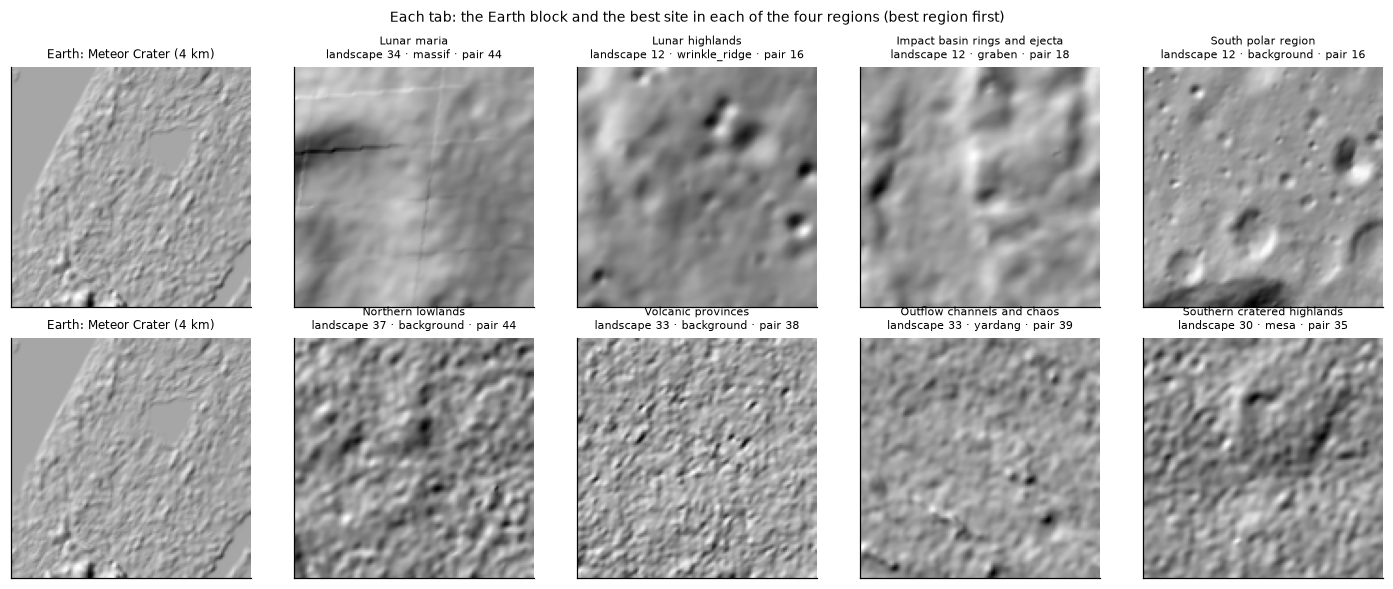

In [25]:
res = here
c = res["conditions"]
print(f"SITE CONDITIONS {c['score']:.0f}/100   " + "  ".join(f"{k} {v:+.2f}" for k, v in c["terms"].items()))
for w in WORLDS:
    r = res["worlds"][w]
    print(f"\n{w.upper()} TAB   best region: {r['best_region']}   best single site: {r['best_match']['name']} (pair score {r['best_match']['pair_score']:.0f})")
    for reg in r["regions"]:
        b = reg["best"][0]
        print(f"   {reg['title']:32s} landscape {reg['score']:5.1f}  overall {reg['overall']:5.1f}   "
              f"[site {reg['scales']['site']['score']:.0f}, regional {reg['scales'].get('regional', {}).get('score', float('nan')):.0f}]   "
              f"best: {b['name']} [{b['tag']}] ({b['lat']:.2f}, {b['lon']:.2f})")

pad = slice(rt.PAD_PX, -rt.PAD_PX)
fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
for row, w in enumerate(WORLDS):
    axes[row, 0].imshow(hillshade(dems_mc["site"][pad, pad]), cmap="gray")
    axes[row, 0].set_title("Earth: Meteor Crater (4 km)", fontsize=8)
    for ax, reg in zip(axes[row, 1:], res["worlds"][w]["regions"]):
        b = reg["best"][0]
        ax.imshow(hillshade(lib["dem_site"][b["index"]].astype(float)), cmap="gray")
        ax.set_title(f"{reg['title']}\nlandscape {reg['score']:.0f} · {b['tag']} · pair {b['pair_score']:.0f}", fontsize=7)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Each tab: the Earth block and the best site in each of the four regions (best region first)", fontsize=9)
plt.tight_layout(); plt.show()